In [1]:
# ============================================================
# CELL 1 — MENTALBERT + EMOTION-BASED CLEANING
# FRESH EXPERIMENT START
# ============================================================

import os
import re
import gc
import json
import html
import random
import warnings

import numpy as np
import pandas as pd
import torch

warnings.filterwarnings("ignore")


# ============================================================
# REPRODUCIBILITY
# ============================================================

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)


# ============================================================
# DEVICE
# ============================================================

device = torch.device(
    "cuda" if torch.cuda.is_available()
    else "cpu"
)


# ============================================================
# EXPERIMENT CONFIGURATION
# ============================================================

MODEL_NAME = (
    "mental/mental-bert-base-uncased"
)

EXPERIMENT_NAME = (
    "MentalBERT + Emotion-Based Cleaning"
)

CLEANING_METHOD = (
    "Emotion-Based cleaning after diagnostic anchor removal"
)

MAX_LENGTH = 512

METADATA_DIM = 53


# ============================================================
# OUTPUT DIRECTORIES
# ============================================================

BASE_RESULT_DIR = (
    "/kaggle/working/"
    "mentalbert_emotion"
)

RESULT_DIR = os.path.join(
    BASE_RESULT_DIR,
    "results"
)

CHECKPOINT_DIR = os.path.join(
    BASE_RESULT_DIR,
    "checkpoints"
)

BACKUP_DIR = os.path.join(
    BASE_RESULT_DIR,
    "backup"
)

os.makedirs(
    RESULT_DIR,
    exist_ok=True
)

os.makedirs(
    CHECKPOINT_DIR,
    exist_ok=True
)

os.makedirs(
    BACKUP_DIR,
    exist_ok=True
)


# ============================================================
# EMOTION-BASED CLEANING POLICY
# ============================================================
#
# The objective is to remove noisy social-media artifacts
# while retaining information potentially useful for emotion
# and mental-health signal detection.
#
# IMPORTANT:
# The exact emotion-aware transformation should be kept
# consistent with the earlier DistilBERT Emotion-Based
# experiment.
# ============================================================

EMOTION_POLICY = [

    "Remove standard URLs",

    "Remove malformed URL variants",

    "Remove user mentions",

    "Remove hashtag symbol while retaining hashtag text",

    "Decode HTML entities",

    "Preserve normal words",

    "Preserve sentence wording",

    "Preserve punctuation",

    "Preserve digits",

    "Preserve emojis",

    "Preserve emoticons",

    "Preserve repeated-character expressions",

    "Preserve exclamation and question patterns",

    "Preserve emotion-bearing symbols",

    "Lowercase text",

    "Normalize whitespace"
]


# ============================================================
# PRINT CONFIGURATION
# ============================================================

print("=" * 60)
print("MENTALBERT + EMOTION-BASED CLEANING")
print("=" * 60)

print()

print(
    "Device:",
    device
)

if torch.cuda.is_available():

    print(
        "GPU:",
        torch.cuda.get_device_name(0)
    )

    print(
        "CUDA:",
        torch.version.cuda
    )

print()

print(
    "Model:",
    MODEL_NAME
)

print(
    "Cleaning:",
    CLEANING_METHOD
)

print(
    "Context length:",
    MAX_LENGTH
)

print(
    "Metadata features:",
    METADATA_DIM
)

print(
    "Seed:",
    SEED
)


# ============================================================
# CLEANING POLICY
# ============================================================

print()
print("=" * 60)
print("EMOTION-BASED CLEANING POLICY")
print("=" * 60)

for i, rule in enumerate(
    EMOTION_POLICY,
    start=1
):

    print(
        f"{i:02d}. {rule}"
    )


# ============================================================
# FIXED EXPERIMENT CONTROLS
# ============================================================

FIXED_CONTROLS = {

    "user_level_split": True,

    "train_users": 6135,

    "validation_users": 767,

    "test_users": 767,

    "diagnostic_anchor_removal": True,

    "metadata_features": 53,

    "metadata_scaling":
        "TRAIN ONLY",

    "training_balance":
        "2013 negative + 2013 positive",

    "batch_size": 16,

    "context_length": 512,

    "random_seed": 42,

    "checkpoint_metric":
        "Validation F1",

    "early_stopping_patience": 2,

    "maximum_epochs": 10
}


# ============================================================
# SAVE EXPERIMENT CONFIG
# ============================================================

experiment_config = {

    "experiment_name":
        EXPERIMENT_NAME,

    "model_name":
        MODEL_NAME,

    "cleaning_method":
        CLEANING_METHOD,

    "context_length":
        MAX_LENGTH,

    "metadata_dimension":
        METADATA_DIM,

    "seed":
        SEED,

    "emotion_policy":
        EMOTION_POLICY,

    "fixed_controls":
        FIXED_CONTROLS
}


with open(
    os.path.join(
        RESULT_DIR,
        "experiment_config.json"
    ),
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        experiment_config,
        f,
        indent=2
    )


# ============================================================
# FINAL
# ============================================================

print()
print("=" * 60)
print("CELL 1 COMPLETE")
print("=" * 60)

print("✓ MentalBERT selected")
print("✓ Emotion-Based cleaning selected")
print("✓ Context length = 512")
print("✓ Metadata dimension = 53")
print("✓ Seed = 42")
print("✓ Emotion cleaning policy defined")
print("✓ Result directory created")
print("✓ Checkpoint directory created")
print("✓ Backup directory created")
print("✓ Experiment configuration saved")
print("✓ RAW outputs untouched")
print("✓ Aggressive outputs untouched")
print("✓ Selective outputs untouched")
print("✓ Fixed experimental controls recorded")

MENTALBERT + EMOTION-BASED CLEANING

Device: cuda
GPU: Tesla T4
CUDA: 12.8

Model: mental/mental-bert-base-uncased
Cleaning: Emotion-Based cleaning after diagnostic anchor removal
Context length: 512
Metadata features: 53
Seed: 42

EMOTION-BASED CLEANING POLICY
01. Remove standard URLs
02. Remove malformed URL variants
03. Remove user mentions
04. Remove hashtag symbol while retaining hashtag text
05. Decode HTML entities
06. Preserve normal words
07. Preserve sentence wording
08. Preserve punctuation
09. Preserve digits
10. Preserve emojis
11. Preserve emoticons
12. Preserve repeated-character expressions
13. Preserve exclamation and question patterns
14. Preserve emotion-bearing symbols
15. Lowercase text
16. Normalize whitespace

CELL 1 COMPLETE
✓ MentalBERT selected
✓ Emotion-Based cleaning selected
✓ Context length = 512
✓ Metadata dimension = 53
✓ Seed = 42
✓ Emotion cleaning policy defined
✓ Result directory created
✓ Checkpoint directory created
✓ Backup directory created
✓ Exp

In [2]:
# ============================================================
# CELL 2 — MENTALBERT EMOTION-BASED
# LOADING EXACT USER-LEVEL SPLIT
# ============================================================

print("=" * 60)
print("MENTALBERT EMOTION-BASED — LOADING EXACT USER-LEVEL SPLIT")
print("=" * 60)


# ============================================================
# SPLIT PATHS
# ============================================================

SPLIT_ROOT = (
    "/kaggle/input/datasets/"
    "vedantnawghare35/"
    "mddl-experiment-1-splits"
)

TRAIN_PATH = os.path.join(
    SPLIT_ROOT,
    "MDDL_train_raw.pkl"
)

VAL_PATH = os.path.join(
    SPLIT_ROOT,
    "MDDL_val_raw.pkl"
)

TEST_PATH = os.path.join(
    SPLIT_ROOT,
    "MDDL_test_raw.pkl"
)


print()
print("TRAIN:", TRAIN_PATH)
print("VAL:  ", VAL_PATH)
print("TEST: ", TEST_PATH)


# ============================================================
# FILE CHECK
# ============================================================

assert os.path.exists(TRAIN_PATH), (
    f"TRAIN split not found: {TRAIN_PATH}"
)

assert os.path.exists(VAL_PATH), (
    f"VALIDATION split not found: {VAL_PATH}"
)

assert os.path.exists(TEST_PATH), (
    f"TEST split not found: {TEST_PATH}"
)

print()
print("✓ All split files found")


# ============================================================
# LOAD
# ============================================================

print()
print("Loading TRAIN...")
train_df = pd.read_pickle(TRAIN_PATH)

print("Loading VALIDATION...")
val_df = pd.read_pickle(VAL_PATH)

print("Loading TEST...")
test_df = pd.read_pickle(TEST_PATH)


# ============================================================
# SHAPES
# ============================================================

print()
print("=" * 60)
print("SPLIT SHAPES")
print("=" * 60)

print("Train:", train_df.shape)
print("Validation:", val_df.shape)
print("Test:", test_df.shape)

assert train_df.shape == (6135, 82)
assert val_df.shape == (767, 82)
assert test_df.shape == (767, 82)


# ============================================================
# REQUIRED COLUMNS
# ============================================================

print()
print("=" * 60)
print("REQUIRED COLUMN CHECK")
print("=" * 60)

required_columns = [
    "user_id",
    "username",
    "label",
    "timeline_text"
]

for column in required_columns:

    assert column in train_df.columns
    assert column in val_df.columns
    assert column in test_df.columns

    print(
        f"✓ {column}"
    )


# ============================================================
# USER-LEVEL INTEGRITY
# ============================================================

print()
print("=" * 60)
print("USER-LEVEL INTEGRITY")
print("=" * 60)

train_users = set(
    train_df["user_id"]
)

val_users = set(
    val_df["user_id"]
)

test_users = set(
    test_df["user_id"]
)


print(
    "Train unique users:",
    train_df["user_id"].nunique()
)

print(
    "Validation unique users:",
    val_df["user_id"].nunique()
)

print(
    "Test unique users:",
    test_df["user_id"].nunique()
)


assert train_df["user_id"].is_unique
assert val_df["user_id"].is_unique
assert test_df["user_id"].is_unique


train_val_overlap = (
    train_users & val_users
)

train_test_overlap = (
    train_users & test_users
)

val_test_overlap = (
    val_users & test_users
)


print(
    "TRAIN ↔ VAL:",
    len(train_val_overlap)
)

print(
    "TRAIN ↔ TEST:",
    len(train_test_overlap)
)

print(
    "VAL ↔ TEST:",
    len(val_test_overlap)
)


assert len(train_val_overlap) == 0
assert len(train_test_overlap) == 0
assert len(val_test_overlap) == 0


print()
print("✓ No duplicate users")
print("✓ No cross-split overlap")


# ============================================================
# LABEL DISTRIBUTION
# ============================================================

print()
print("=" * 60)
print("LABEL DISTRIBUTION")
print("=" * 60)

print()
print("TRAIN:")
print(
    train_df[
        "label"
    ]
    .value_counts()
    .sort_index()
)

print()
print("VALIDATION:")
print(
    val_df[
        "label"
    ]
    .value_counts()
    .sort_index()
)

print()
print("TEST:")
print(
    test_df[
        "label"
    ]
    .value_counts()
    .sort_index()
)


# ============================================================
# EXACT LABEL CHECK
# ============================================================

assert (
    train_df["label"]
    .value_counts()
    .sort_index()
    .to_dict()
    ==
    {
        0: 4122,
        1: 2013
    }
)

assert (
    val_df["label"]
    .value_counts()
    .sort_index()
    .to_dict()
    ==
    {
        0: 515,
        1: 252
    }
)

assert (
    test_df["label"]
    .value_counts()
    .sort_index()
    .to_dict()
    ==
    {
        0: 516,
        1: 251
    }
)


# ============================================================
# TIMELINE CHECK
# ============================================================

print()
print("=" * 60)
print("TIMELINE TEXT CHECK")
print("=" * 60)

for df, split_name in [

    (
        train_df,
        "TRAIN"
    ),

    (
        val_df,
        "VALIDATION"
    ),

    (
        test_df,
        "TEST"
    )

]:

    null_count = int(
        df[
            "timeline_text"
        ]
        .isna()
        .sum()
    )

    print(
        f"{split_name} null timeline texts:",
        null_count
    )

    assert null_count == 0


# ============================================================
# FINAL
# ============================================================

print()
print("=" * 60)
print("CELL 2 COMPLETE")
print("=" * 60)

print("✓ Exact user-level split restored")
print("✓ TRAIN = 6135")
print("✓ VALIDATION = 767")
print("✓ TEST = 767")
print("✓ Same labels as previous experiments")
print("✓ No duplicate users")
print("✓ No cross-split user overlap")
print("✓ Timeline text available")

MENTALBERT EMOTION-BASED — LOADING EXACT USER-LEVEL SPLIT

TRAIN: /kaggle/input/datasets/vedantnawghare35/mddl-experiment-1-splits/MDDL_train_raw.pkl
VAL:   /kaggle/input/datasets/vedantnawghare35/mddl-experiment-1-splits/MDDL_val_raw.pkl
TEST:  /kaggle/input/datasets/vedantnawghare35/mddl-experiment-1-splits/MDDL_test_raw.pkl

✓ All split files found

Loading TRAIN...
Loading VALIDATION...
Loading TEST...

SPLIT SHAPES
Train: (6135, 82)
Validation: (767, 82)
Test: (767, 82)

REQUIRED COLUMN CHECK
✓ user_id
✓ username
✓ label
✓ timeline_text

USER-LEVEL INTEGRITY
Train unique users: 6135
Validation unique users: 767
Test unique users: 767
TRAIN ↔ VAL: 0
TRAIN ↔ TEST: 0
VAL ↔ TEST: 0

✓ No duplicate users
✓ No cross-split overlap

LABEL DISTRIBUTION

TRAIN:
label
0    4122
1    2013
Name: count, dtype: int64

VALIDATION:
label
0    515
1    252
Name: count, dtype: int64

TEST:
label
0    516
1    251
Name: count, dtype: int64

TIMELINE TEXT CHECK
TRAIN null timeline texts: 0
VALIDATION 

In [3]:
# ============================================================
# CELL 3 — MENTALBERT EMOTION-BASED
# EXACT D1 ANCHOR DETECTION
# ============================================================

import os
import re
import json
import glob

from collections import defaultdict


print("=" * 60)
print("MENTALBERT EMOTION-BASED — EXACT D1 ANCHOR DETECTION")
print("=" * 60)


# ============================================================
# D1 TIMELINE DIRECTORY
# ============================================================

DATASET_ROOT = (
    "/kaggle/input/datasets/"
    "vedantnawghare35/"
    "depression-detection-mddl-final-pbl/"
    "Dataset_MDDL"
)

D1_TIMELINE_DIR = os.path.join(
    DATASET_ROOT,
    "labeled",
    "positive",
    "data",
    "timeline"
)

assert os.path.exists(
    D1_TIMELINE_DIR
), (
    f"D1 timeline directory not found: "
    f"{D1_TIMELINE_DIR}"
)


# ============================================================
# FIND D1 TIMELINE FILES
# ============================================================

d1_timeline_files = glob.glob(
    os.path.join(
        D1_TIMELINE_DIR,
        "*.json"
    )
)

print()
print(
    "D1 timeline files found:",
    len(d1_timeline_files)
)

assert len(
    d1_timeline_files
) == 2626


# ============================================================
# EXACT ANCHOR PATTERNS
# SAME AS PREVIOUS EXPERIMENTS
# ============================================================

REFINED_ANCHOR_PATTERNS = [

    r"\bi(?:'m| am)\s+diagnosed\s+with\s+(?:major\s+)?depression\b",

    r"\bi\s+(?:was|were)\s+diagnosed\s+with\s+(?:major\s+)?depression\b",

    r"\bi(?:'ve| have)\s+been\s+diagnosed\s+with\s+(?:major\s+)?depression\b",

    r"\bi(?:'m| am)\s+diagnosed\s+with\s+(?:major\s+)?depressive\s+disorder\b",

    r"\bi\s+(?:was|were)\s+diagnosed\s+with\s+(?:major\s+)?depressive\s+disorder\b",

    r"\bi(?:'ve| have)\s+been\s+diagnosed\s+with\s+(?:major\s+)?depressive\s+disorder\b",

    r"\bi\s+have\s+(?:major\s+)?depression\b",

    r"\bi\s+suffer\s+from\s+(?:major\s+)?depression\b",

    r"\bi\s+(?:was|am|'m)\s+diagnosed\b.{0,80}\bdepress",

    (
        r"\b(?:my|a)\s+(?:doctor|psychiatrist)"
        r"\s+(?:has\s+)?diagnosed\s+me\b"
        r".{0,80}\bdepress"
    )
]


compiled_anchor_patterns = [

    re.compile(
        pattern,
        flags=re.IGNORECASE | re.DOTALL
    )

    for pattern
    in REFINED_ANCHOR_PATTERNS
]


# ============================================================
# EXCLUSION PATTERNS
# SAME AS PREVIOUS EXPERIMENTS
# ============================================================

EXCLUSION_PATTERNS = [

    r"\bmy\s+friend\s+(?:was|is|has\s+been)\s+diagnosed",

    r"\bmy\s+sister\s+(?:was|is|has\s+been)\s+diagnosed",

    r"\bmy\s+brother\s+(?:was|is|has\s+been)\s+diagnosed",

    r"\bmy\s+mother\s+(?:was|is|has\s+been)\s+diagnosed",

    r"\bmy\s+father\s+(?:was|is|has\s+been)\s+diagnosed",

    r"\bmy\s+answer\s+to\s*:",

    r"\banswer\s+to\s*:",

    r"\bquestion\s*:",

    r"\bq\s*:"
]


compiled_exclusion_patterns = [

    re.compile(
        pattern,
        flags=re.IGNORECASE | re.DOTALL
    )

    for pattern
    in EXCLUSION_PATTERNS
]


# ============================================================
# ANCHOR DETECTOR
# ============================================================

def is_refined_anchor_tweet(
    text
):

    if text is None:
        return False

    text = str(
        text
    ).strip()

    if not text:
        return False

    # --------------------------------------------------------
    # Apply exclusions first
    # --------------------------------------------------------

    for pattern in compiled_exclusion_patterns:

        if pattern.search(text):
            return False

    # --------------------------------------------------------
    # Apply exact anchor patterns
    # --------------------------------------------------------

    for pattern in compiled_anchor_patterns:

        if pattern.search(text):
            return True

    return False


# ============================================================
# POSITIVE USERS BY SPLIT
# ============================================================

train_positive_users = set(
    train_df.loc[
        train_df["label"] == 1,
        "username"
    ]
    .astype(str)
)

val_positive_users = set(
    val_df.loc[
        val_df["label"] == 1,
        "username"
    ]
    .astype(str)
)

test_positive_users = set(
    test_df.loc[
        test_df["label"] == 1,
        "username"
    ]
    .astype(str)
)

all_positive_users = (
    train_positive_users
    |
    val_positive_users
    |
    test_positive_users
)


print()
print("=" * 60)
print("POSITIVE USERS BY SPLIT")
print("=" * 60)

print(
    "TRAIN:",
    len(train_positive_users)
)

print(
    "VALIDATION:",
    len(val_positive_users)
)

print(
    "TEST:",
    len(test_positive_users)
)


assert len(
    train_positive_users
) == 2013

assert len(
    val_positive_users
) == 252

assert len(
    test_positive_users
) == 251

assert len(
    all_positive_users
) == 2516


# ============================================================
# INDEX TIMELINE FILES BY USER
# ============================================================

timeline_files_by_user = (
    defaultdict(list)
)


for timeline_file in d1_timeline_files:

    filename = os.path.basename(
        timeline_file
    )

    username = filename.split(
        "created_at"
    )[0]

    timeline_files_by_user[
        username
    ].append(
        timeline_file
    )


assert len(
    timeline_files_by_user
) == 2516


# ============================================================
# SCAN ALL POSITIVE USER TIMELINES
# ============================================================

anchor_records = []

users_processed = set()

tweets_scanned = 0


for username in sorted(
    all_positive_users
):

    if username not in timeline_files_by_user:

        raise KeyError(
            f"Missing D1 timeline for user: "
            f"{username}"
        )

    users_processed.add(
        username
    )


    for timeline_file in (
        timeline_files_by_user[
            username
        ]
    ):

        with open(
            timeline_file,
            "r",
            encoding="utf-8"
        ) as f:

            for line in f:

                line = line.strip()

                if not line:
                    continue

                record = json.loads(
                    line
                )

                tweets_scanned += 1


                tweet_id = str(
                    record.get(
                        "id_str",
                        record.get(
                            "id",
                            ""
                        )
                    )
                )

                tweet_text = str(
                    record.get(
                        "text",
                        ""
                    )
                )


                if (
                    tweet_id
                    and
                    is_refined_anchor_tweet(
                        tweet_text
                    )
                ):

                    anchor_records.append(
                        {
                            "username":
                                username,

                            "tweet_id":
                                tweet_id,

                            "created_at":
                                record.get(
                                    "created_at"
                                ),

                            "text":
                                tweet_text
                        }
                    )


# ============================================================
# UNIQUE ANCHOR PAIRS
# ============================================================

anchor_pairs = {

    (
        record["username"],
        record["tweet_id"]
    )

    for record
    in anchor_records
}


# ============================================================
# SPLIT-WISE UNIQUE ANCHORS
# ============================================================

train_anchor_pairs = {
    pair
    for pair in anchor_pairs
    if pair[0] in train_positive_users
}

val_anchor_pairs = {
    pair
    for pair in anchor_pairs
    if pair[0] in val_positive_users
}

test_anchor_pairs = {
    pair
    for pair in anchor_pairs
    if pair[0] in test_positive_users
}


# ============================================================
# SUMMARY
# ============================================================

print()
print("=" * 60)
print("EXACT ANCHOR SUMMARY")
print("=" * 60)

print(
    "Positive users processed:",
    len(users_processed)
)

print(
    "Tweets scanned:",
    tweets_scanned
)

print(
    "Raw anchor records:",
    len(anchor_records)
)

print(
    "Unique anchor pairs:",
    len(anchor_pairs)
)

print()
print(
    "TRAIN unique anchors:",
    len(train_anchor_pairs)
)

print(
    "VAL unique anchors:",
    len(val_anchor_pairs)
)

print(
    "TEST unique anchors:",
    len(test_anchor_pairs)
)


# ============================================================
# EXACT CONTROL ASSERTIONS
# ============================================================

assert len(
    users_processed
) == 2516

assert len(
    anchor_records
) == 1920

assert len(
    anchor_pairs
) == 1847

assert len(
    train_anchor_pairs
) == 1476

assert len(
    val_anchor_pairs
) == 190

assert len(
    test_anchor_pairs
) == 181


# ============================================================
# SAVE ANCHOR RECORDS
# ============================================================

mental_emotion_anchor_df = pd.DataFrame(
    anchor_records
)

mental_emotion_anchor_df.to_csv(
    os.path.join(
        RESULT_DIR,
        "exact_anchor_records.csv"
    ),
    index=False
)


# ============================================================
# SAVE UNIQUE ANCHOR PAIRS
# ============================================================

pd.DataFrame(
    list(anchor_pairs),
    columns=[
        "username",
        "tweet_id"
    ]
).to_csv(
    os.path.join(
        RESULT_DIR,
        "unique_anchor_pairs.csv"
    ),
    index=False
)


# ============================================================
# FINAL
# ============================================================

print()
print("=" * 60)
print("CELL 3 COMPLETE")
print("=" * 60)

print("✓ Exact anchor detector reproduced")
print("✓ 1,847 unique anchors confirmed")
print("✓ 1,920 anchor records confirmed")
print("✓ TRAIN = 1,476 unique anchors")
print("✓ VAL = 190 unique anchors")
print("✓ TEST = 181 unique anchors")
print("✓ No D2 users included")
print("✓ Anchor records saved")
print("✓ No timelines modified yet")

MENTALBERT EMOTION-BASED — EXACT D1 ANCHOR DETECTION

D1 timeline files found: 2626

POSITIVE USERS BY SPLIT
TRAIN: 2013
VALIDATION: 252
TEST: 251

EXACT ANCHOR SUMMARY
Positive users processed: 2516
Tweets scanned: 508806
Raw anchor records: 1920
Unique anchor pairs: 1847

TRAIN unique anchors: 1476
VAL unique anchors: 190
TEST unique anchors: 181

CELL 3 COMPLETE
✓ Exact anchor detector reproduced
✓ 1,847 unique anchors confirmed
✓ 1,920 anchor records confirmed
✓ TRAIN = 1,476 unique anchors
✓ VAL = 190 unique anchors
✓ TEST = 181 unique anchors
✓ No D2 users included
✓ Anchor records saved
✓ No timelines modified yet


In [4]:
# ============================================================
# CELL 4 — MENTALBERT EMOTION-BASED
# EXACT D1 ANCHOR REMOVAL
# ============================================================

print("=" * 60)
print("MENTALBERT EMOTION-BASED — EXACT D1 ANCHOR REMOVAL")
print("=" * 60)


# ============================================================
# EXPECTED COUNTS
# ============================================================

EXPECTED_TRAIN_REMOVED = 1535
EXPECTED_VAL_REMOVED = 199
EXPECTED_TEST_REMOVED = 186
EXPECTED_TOTAL_REMOVED = 1920


# ============================================================
# PRE-REMOVAL VERIFICATION
# ============================================================

print()
print("=" * 60)
print("PRE-REMOVAL ANCHOR VERIFICATION")
print("=" * 60)

duplicate_anchor_occurrences = (
    len(anchor_records)
    - len(anchor_pairs)
)

print(
    "Raw anchor records:",
    len(anchor_records)
)

print(
    "Unique anchor pairs:",
    len(anchor_pairs)
)

print(
    "Duplicate anchor occurrences:",
    duplicate_anchor_occurrences
)

assert len(anchor_records) == 1920
assert len(anchor_pairs) == 1847
assert duplicate_anchor_occurrences == 73

print("✓ 1,847 unique anchors verified")
print("✓ 73 duplicate occurrences verified")
print("✓ 1,920 total anchor records verified")


# ============================================================
# SPLIT-LEVEL RECORD COUNTS
# ============================================================

train_anchor_records = [
    r
    for r in anchor_records
    if r["username"] in train_positive_users
]

val_anchor_records = [
    r
    for r in anchor_records
    if r["username"] in val_positive_users
]

test_anchor_records = [
    r
    for r in anchor_records
    if r["username"] in test_positive_users
]


print()
print("=" * 60)
print("SPLIT-LEVEL ANCHOR RECORD COUNTS")
print("=" * 60)

print(
    "TRAIN:",
    len(train_anchor_records),
    "| expected:",
    EXPECTED_TRAIN_REMOVED
)

print(
    "VAL:",
    len(val_anchor_records),
    "| expected:",
    EXPECTED_VAL_REMOVED
)

print(
    "TEST:",
    len(test_anchor_records),
    "| expected:",
    EXPECTED_TEST_REMOVED
)

assert len(train_anchor_records) == EXPECTED_TRAIN_REMOVED
assert len(val_anchor_records) == EXPECTED_VAL_REMOVED
assert len(test_anchor_records) == EXPECTED_TEST_REMOVED


# ============================================================
# EXACT ANCHOR SET
# ============================================================

EXACT_ANCHOR_SET = set(
    anchor_pairs
)


# ============================================================
# BUILD ANCHOR-REMOVED TEXT
# ============================================================

def build_anchor_removed_text(
    username
):

    kept_texts = []
    removed_count = 0

    for timeline_file in (
        timeline_files_by_user[
            username
        ]
    ):

        with open(
            timeline_file,
            "r",
            encoding="utf-8"
        ) as f:

            for line in f:

                line = line.strip()

                if not line:
                    continue

                record = json.loads(line)

                tweet_id = str(
                    record.get(
                        "id_str",
                        record.get(
                            "id",
                            ""
                        )
                    )
                )

                pair = (
                    str(username),
                    tweet_id
                )

                # Remove exact D1 anchor
                if pair in EXACT_ANCHOR_SET:

                    removed_count += 1
                    continue

                tweet_text = str(
                    record.get(
                        "text",
                        ""
                    )
                ).strip()

                if tweet_text:
                    kept_texts.append(
                        tweet_text
                    )

    return (
        " ".join(kept_texts),
        removed_count
    )


# ============================================================
# COPY ORIGINAL DATAFRAMES
# ============================================================

train_mental_emotion_df = train_df.copy(
    deep=True
)

val_mental_emotion_df = val_df.copy(
    deep=True
)

test_mental_emotion_df = test_df.copy(
    deep=True
)


# ============================================================
# BUILD POSITIVE USER TEXT
# ============================================================

positive_anchor_removed_text = {}

train_removed = 0
val_removed = 0
test_removed = 0


for username in sorted(
    all_positive_users
):

    (
        anchor_removed_text,
        removed_count
    ) = build_anchor_removed_text(
        username
    )

    positive_anchor_removed_text[
        username
    ] = anchor_removed_text

    if username in train_positive_users:

        train_removed += removed_count

    elif username in val_positive_users:

        val_removed += removed_count

    elif username in test_positive_users:

        test_removed += removed_count


# ============================================================
# VERIFY REMOVAL COUNTS
# ============================================================

print()
print("=" * 60)
print("FINAL ANCHOR REMOVAL COUNTS")
print("=" * 60)

print(
    "TRAIN removed:",
    train_removed
)

print(
    "VAL removed:",
    val_removed
)

print(
    "TEST removed:",
    test_removed
)

print(
    "TOTAL removed:",
    train_removed
    + val_removed
    + test_removed
)

assert train_removed == EXPECTED_TRAIN_REMOVED
assert val_removed == EXPECTED_VAL_REMOVED
assert test_removed == EXPECTED_TEST_REMOVED

assert (
    train_removed
    + val_removed
    + test_removed
    == EXPECTED_TOTAL_REMOVED
)

print(
    "✓ Record-level removal exactly matches "
    "previous experiments"
)


# ============================================================
# ASSIGN ANCHOR-REMOVED TEXT
# ============================================================

for df in [
    train_mental_emotion_df,
    val_mental_emotion_df,
    test_mental_emotion_df
]:

    positive_mask = (
        df["label"] == 1
    )

    df.loc[
        positive_mask,
        "anchor_removed_text"
    ] = (
        df.loc[
            positive_mask,
            "username"
        ]
        .astype(str)
        .map(
            positive_anchor_removed_text
        )
        .fillna("")
        .values
    )

    # D2 / negative users remain unchanged
    negative_mask = (
        df["label"] == 0
    )

    df.loc[
        negative_mask,
        "anchor_removed_text"
    ] = (
        df.loc[
            negative_mask,
            "timeline_text"
        ]
        .fillna("")
        .astype(str)
        .values
    )


# ============================================================
# D2 PRESERVATION CHECK
# ============================================================

print()
print("=" * 60)
print("D2 PRESERVATION CHECK")
print("=" * 60)

for original_df, result_df, split_name in [

    (
        train_df,
        train_mental_emotion_df,
        "TRAIN"
    ),

    (
        val_df,
        val_mental_emotion_df,
        "VALIDATION"
    ),

    (
        test_df,
        test_mental_emotion_df,
        "TEST"
    )

]:

    original_d2 = (
        original_df.loc[
            original_df["label"] == 0,
            [
                "username",
                "timeline_text"
            ]
        ]
        .set_index("username")
        .sort_index()
    )

    result_d2 = (
        result_df.loc[
            result_df["label"] == 0,
            [
                "username",
                "anchor_removed_text"
            ]
        ]
        .rename(
            columns={
                "anchor_removed_text":
                    "timeline_text"
            }
        )
        .set_index("username")
        .sort_index()
    )

    assert original_d2.equals(
        result_d2
    )

    print(
        f"✓ {split_name} D2 unchanged"
    )


# ============================================================
# USER + LABEL PRESERVATION
# ============================================================

print()
print("=" * 60)
print("USER + LABEL PRESERVATION")
print("=" * 60)

for original_df, result_df, split_name in [

    (
        train_df,
        train_mental_emotion_df,
        "TRAIN"
    ),

    (
        val_df,
        val_mental_emotion_df,
        "VALIDATION"
    ),

    (
        test_df,
        test_mental_emotion_df,
        "TEST"
    )

]:

    assert (
        original_df["user_id"].tolist()
        ==
        result_df["user_id"].tolist()
    )

    assert (
        original_df["username"].tolist()
        ==
        result_df["username"].tolist()
    )

    assert (
        original_df["label"].tolist()
        ==
        result_df["label"].tolist()
    )

    print(
        f"✓ {split_name}: users and labels unchanged"
    )


# ============================================================
# EMPTY TEXT CHECK
# ============================================================

print()
print("=" * 60)
print("ANCHOR-REMOVED TEXT INTEGRITY")
print("=" * 60)

for split_name, df in [

    (
        "TRAIN",
        train_mental_emotion_df
    ),

    (
        "VALIDATION",
        val_mental_emotion_df
    ),

    (
        "TEST",
        test_mental_emotion_df
    )

]:

    empty_count = int(
        (
            df[
                "anchor_removed_text"
            ]
            .fillna("")
            .astype(str)
            .str.strip()
            == ""
        ).sum()
    )

    print(
        f"{split_name}: "
        f"empty anchor-removed texts = "
        f"{empty_count}"
    )


# ============================================================
# PREVIEW
# ============================================================

print()
print("=" * 60)
print("ANCHOR-REMOVED TEXT PREVIEW")
print("=" * 60)

for _, row in (
    train_mental_emotion_df
    .head(3)
    .iterrows()
):

    print()
    print(
        "User:",
        row["username"]
    )

    print(
        "Label:",
        row["label"]
    )

    print(
        row["anchor_removed_text"][:1200]
    )


# ============================================================
# SAVE
# ============================================================

train_mental_emotion_df.to_pickle(
    os.path.join(
        RESULT_DIR,
        "train_anchor_removed.pkl"
    )
)

val_mental_emotion_df.to_pickle(
    os.path.join(
        RESULT_DIR,
        "val_anchor_removed.pkl"
    )
)

test_mental_emotion_df.to_pickle(
    os.path.join(
        RESULT_DIR,
        "test_anchor_removed.pkl"
    )
)


# ============================================================
# FINAL
# ============================================================

print()
print("=" * 60)
print("CELL 4 COMPLETE")
print("=" * 60)

print("✓ 1,847 unique D1 anchors removed")
print("✓ 73 duplicate occurrences handled")
print("✓ 1,920 total anchor records removed")
print("✓ TRAIN = 1,535 removed")
print("✓ VAL = 199 removed")
print("✓ TEST = 186 removed")
print("✓ D2 completely preserved")
print("✓ User IDs preserved")
print("✓ Labels preserved")
print("✓ No emotion cleaning applied yet")
print("✓ Anchor-removed source saved")

MENTALBERT EMOTION-BASED — EXACT D1 ANCHOR REMOVAL

PRE-REMOVAL ANCHOR VERIFICATION
Raw anchor records: 1920
Unique anchor pairs: 1847
Duplicate anchor occurrences: 73
✓ 1,847 unique anchors verified
✓ 73 duplicate occurrences verified
✓ 1,920 total anchor records verified

SPLIT-LEVEL ANCHOR RECORD COUNTS
TRAIN: 1535 | expected: 1535
VAL: 199 | expected: 199
TEST: 186 | expected: 186

FINAL ANCHOR REMOVAL COUNTS
TRAIN removed: 1535
VAL removed: 199
TEST removed: 186
TOTAL removed: 1920
✓ Record-level removal exactly matches previous experiments

D2 PRESERVATION CHECK
✓ TRAIN D2 unchanged
✓ VALIDATION D2 unchanged
✓ TEST D2 unchanged

USER + LABEL PRESERVATION
✓ TRAIN: users and labels unchanged
✓ VALIDATION: users and labels unchanged
✓ TEST: users and labels unchanged

ANCHOR-REMOVED TEXT INTEGRITY
TRAIN: empty anchor-removed texts = 29
VALIDATION: empty anchor-removed texts = 4
TEST: empty anchor-removed texts = 1

ANCHOR-REMOVED TEXT PREVIEW

User: RompingFox
Label: 1
@cybershot_1 

In [5]:
# ============================================================
# CELL 5 — MENTALBERT EMOTION-BASED
# TEXT CLEANING
# ============================================================

import os
import re
import html
import pandas as pd
import numpy as np

print("=" * 60)
print("MENTALBERT EMOTION-BASED — TEXT CLEANING")
print("=" * 60)


# ============================================================
# EMOTION-BASED CLEANING FUNCTION
# ============================================================
#
# REMOVE:
#   1. URLs
#   2. Malformed URLs
#   3. User mentions
#   4. Hashtag symbol (#)
#   5. HTML entity encoding
#
# PRESERVE:
#   1. Normal words
#   2. Punctuation
#   3. Digits
#   4. Emojis
#   5. Emoticons
#   6. Repeated-character expressions
#   7. Exclamation/question patterns
#   8. RT text
#   9. Emotion-bearing symbols
#
# APPLY:
#   1. Lowercase
#   2. Whitespace normalization
# ============================================================


def emotion_based_clean_text(text):

    if text is None:
        return ""

    text = str(text)

    # --------------------------------------------------------
    # 1. DECODE HTML ENTITIES
    # --------------------------------------------------------

    text = html.unescape(text)

    # --------------------------------------------------------
    # 2. REMOVE STANDARD URLs
    # --------------------------------------------------------

    text = re.sub(
        r"(?:https?://|www\.)\S+",
        " ",
        text,
        flags=re.IGNORECASE
    )

    # --------------------------------------------------------
    # 3. REMOVE MALFORMED URL VARIANTS
    # --------------------------------------------------------

    text = re.sub(
        r"https?\s*:\s*/+\S*",
        " ",
        text,
        flags=re.IGNORECASE
    )

    # --------------------------------------------------------
    # 4. REMOVE TWITTER URL FRAGMENTS
    # --------------------------------------------------------

    text = re.sub(
        r"\bpic\.twitter\.com/\S*",
        " ",
        text,
        flags=re.IGNORECASE
    )

    # --------------------------------------------------------
    # 5. REMOVE USER MENTIONS
    # --------------------------------------------------------

    text = re.sub(
        r"@\w+",
        "",
        text,
        flags=re.UNICODE
    )

    # --------------------------------------------------------
    # 6. REMOVE HASHTAG SYMBOL ONLY
    #
    # #depression -> depression
    # #mentalhealth -> mentalhealth
    #
    # The hashtag WORD itself is preserved.
    # --------------------------------------------------------

    text = re.sub(
        r"#(?=\w)",
        "",
        text,
        flags=re.UNICODE
    )

    # --------------------------------------------------------
    # 7. REMOVE STANDALONE HASH SYMBOL
    # --------------------------------------------------------

    text = re.sub(
        r"#",
        " ",
        text
    )

    # --------------------------------------------------------
    # 8. LOWERCASE
    #
    # IMPORTANT:
    # This does not remove emojis, punctuation, digits,
    # emoticons, or repeated-character expressions.
    # --------------------------------------------------------

    text = text.lower()

    # --------------------------------------------------------
    # 9. NORMALIZE WHITESPACE ONLY
    # --------------------------------------------------------

    text = re.sub(
        r"\s+",
        " ",
        text
    ).strip()

    return text


# ============================================================
# CONTROLLED SANITY TESTS
# ============================================================

print()
print("=" * 60)
print("EMOTION-BASED CLEANING TEST")
print("=" * 60)


test_examples = [

    (
        "I CAN'T sleep 😭!!! "
        "https://t.co/example @someone #depression",

        "i can't sleep 😭!!! depression"
    ),

    (
        "RT @user: I am feeling REALLY bad today!!!",

        "rt : i am feeling really bad today!!!"
    ),

    (
        "Everything is okay... or maybe NOT 😔",

        "everything is okay... or maybe not 😔"
    ),

    (
        "I have been feeling hopeless for weeks :(",

        "i have been feeling hopeless for weeks :("
    ),

    (
        "I am 23 years old and this happened 3 times!!!",

        "i am 23 years old and this happened 3 times!!!"
    ),

    (
        "Feeling sooo tired... but I'm trying :) "
        "#mentalhealth",

        "feeling sooo tired... but i'm trying :) mentalhealth"
    ),

    (
        "hello @user123!!!",

        "hello !!!"
    ),

    (
        "@one@two@three hello",

        "hello"
    ),

    (
        "#depression #mentalhealth",

        "depression mentalhealth"
    ),

    (
        "#bitcoin #anc105 #zuma",

        "bitcoin anc105 zuma"
    ),

    (
        "visit https://example.com now",

        "visit now"
    ),

    (
        "visit https:/example.com now",

        "visit now"
    ),

    (
        "RT @someone: Feeling sooo tired 😭!!!",

        "rt : feeling sooo tired 😭!!!"
    ),

    (
        "WHYYYYYY 😭😭😭!!!",

        "whyyyyyy 😭😭😭!!!"
    ),

    (
        "I HATE this!!! :(",

        "i hate this!!! :("
    ),

    (
        "NOOOOOOOO 😭💔",

        "noooooooo 😭💔"
    )
]


for idx, (
    raw_text,
    expected_text
) in enumerate(
    test_examples,
    start=1
):

    cleaned_text = (
        emotion_based_clean_text(
            raw_text
        )
    )

    print()
    print(
        f"EXAMPLE {idx}"
    )

    print("RAW:")
    print(raw_text)

    print("EMOTION-BASED CLEANED:")
    print(cleaned_text)

    assert (
        cleaned_text
        ==
        expected_text
    )


print()
print(
    "✓ All emotion-based cleaning sanity tests passed"
)


# ============================================================
# APPLY CLEANING
# ============================================================

print()
print("=" * 60)
print("APPLYING EMOTION-BASED CLEANING")
print("=" * 60)


for df in [

    train_mental_emotion_df,
    val_mental_emotion_df,
    test_mental_emotion_df

]:

    df["model_text"] = (
        df["anchor_removed_text"]
        .fillna("")
        .astype(str)
        .map(
            emotion_based_clean_text
        )
    )


# ============================================================
# EMPTY TEXT COUNTS
# ============================================================

print()

for split_name, df in [

    (
        "TRAIN",
        train_mental_emotion_df
    ),

    (
        "VALIDATION",
        val_mental_emotion_df
    ),

    (
        "TEST",
        test_mental_emotion_df
    )

]:

    empty_count = int(
        (
            df["model_text"]
            .str.strip()
            ==
            ""
        ).sum()
    )

    print(
        f"{split_name}: "
        f"empty after cleaning: "
        f"{empty_count}"
    )


# ============================================================
# USER + USERNAME + LABEL PRESERVATION
# ============================================================

print()
print("=" * 60)
print("USER + LABEL PRESERVATION")
print("=" * 60)


for original, result, split_name in [

    (
        train_df,
        train_mental_emotion_df,
        "TRAIN"
    ),

    (
        val_df,
        val_mental_emotion_df,
        "VALIDATION"
    ),

    (
        test_df,
        test_mental_emotion_df,
        "TEST"
    )

]:

    assert (
        original["user_id"].tolist()
        ==
        result["user_id"].tolist()
    )

    assert (
        original["username"].tolist()
        ==
        result["username"].tolist()
    )

    assert (
        original["label"].tolist()
        ==
        result["label"].tolist()
    )

    print(
        f"✓ {split_name}: "
        "users, usernames and labels unchanged"
    )


# ============================================================
# DATASET-LEVEL VERIFICATION
# ============================================================

print()
print("=" * 60)
print("EMOTION-BASED CLEANING VERIFICATION")
print("=" * 60)


def verify_emotion_cleaning(
    df,
    split_name
):

    texts = (
        df["model_text"]
        .fillna("")
        .astype(str)
    )

    # --------------------------------------------------------
    # LOWERCASE
    # --------------------------------------------------------

    lowercase_ok = (
        texts.eq(
            texts.str.lower()
        ).all()
    )

    assert lowercase_ok

    # --------------------------------------------------------
    # STANDARD URL CHECK
    # --------------------------------------------------------

    url_remaining = sum(
        len(
            re.findall(
                r"(?:https?://|www\.)\S+",
                text,
                flags=re.IGNORECASE
            )
        )
        for text in texts
    )

    # --------------------------------------------------------
    # MALFORMED URL CHECK
    # --------------------------------------------------------

    malformed_url_remaining = sum(
        len(
            re.findall(
                r"https?\s*:\s*/+\S*",
                text,
                flags=re.IGNORECASE
            )
        )
        for text in texts
    )

    # --------------------------------------------------------
    # HASHTAG CHECK
    # --------------------------------------------------------

    hashtag_remaining = sum(
        len(
            re.findall(
                r"#\w+",
                text,
                flags=re.UNICODE
            )
        )
        for text in texts
    )

    # --------------------------------------------------------
    # VALID MENTION CHECK
    # --------------------------------------------------------

    mention_remaining = sum(
        len(
            re.findall(
                r"(?<![\w@])@\w+",
                text,
                flags=re.UNICODE
            )
        )
        for text in texts
    )

    print()
    print(
        f"{split_name} URL tokens remaining:",
        url_remaining
    )

    print(
        f"{split_name} malformed URL tokens remaining:",
        malformed_url_remaining
    )

    print(
        f"{split_name} @username tokens remaining:",
        mention_remaining
    )

    print(
        f"{split_name} #hashtag tokens remaining:",
        hashtag_remaining
    )

    print(
        f"{split_name} lowercase check:",
        lowercase_ok
    )

    assert (
        url_remaining
        ==
        0
    )

    assert (
        malformed_url_remaining
        ==
        0
    )

    assert (
        hashtag_remaining
        ==
        0
    )

    # Mention-like malformed @ symbols are reported,
    # not treated as a fatal failure.
    #
    # This matches the handling used in the Selective
    # experiment and avoids incorrectly rejecting preserved
    # punctuation-like text.

    if mention_remaining == 0:

        print(
            f"✓ {split_name}: "
            "No valid @username tokens remain"
        )

    else:

        print(
            f"⚠ {split_name}: "
            f"{mention_remaining} "
            "mention-like patterns remain"
        )

    print(
        f"✓ {split_name} cleaning verification passed"
    )


verify_emotion_cleaning(
    train_mental_emotion_df,
    "TRAIN"
)

verify_emotion_cleaning(
    val_mental_emotion_df,
    "VALIDATION"
)

verify_emotion_cleaning(
    test_mental_emotion_df,
    "TEST"
)


# ============================================================
# EMOTION PRESERVATION CHECK
# ============================================================

print()
print("=" * 60)
print("EMOTION-PRESERVATION CHECK")
print("=" * 60)


emotion_preservation_tests = [

    (
        "😭😭",
        "😭😭"
    ),

    (
        "!!!",
        "!!!"
    ),

    (
        "???",
        "???"
    ),

    (
        ":(",
        ":("
    ),

    (
        ":)",
        ":)"
    ),

    (
        "sooooooo",
        "sooooooo"
    ),

    (
        "WHYYYYYY 😭!!!",
        "whyyyyyy 😭!!!"
    ),

    (
        "I HATE THIS!!! 💔",
        "i hate this!!! 💔"
    ),

    (
        "23 times!!!",
        "23 times!!!"
    )
]


for raw_text, expected_text in (
    emotion_preservation_tests
):

    result = (
        emotion_based_clean_text(
            raw_text
        )
    )

    assert (
        result
        ==
        expected_text
    )


print(
    "✓ Emojis preserved"
)

print(
    "✓ Emoticons preserved"
)

print(
    "✓ Exclamation patterns preserved"
)

print(
    "✓ Question patterns preserved"
)

print(
    "✓ Repeated-character expressions preserved"
)

print(
    "✓ Digits preserved"
)

print(
    "✓ Emotion-bearing symbols preserved"
)


# ============================================================
# TEXT PREVIEW
# ============================================================

print()
print("=" * 60)
print("MENTALBERT EMOTION-BASED TEXT PREVIEW")
print("=" * 60)


for _, row in (
    train_mental_emotion_df
    .head(5)
    .iterrows()
):

    print()
    print(
        "User:",
        row["username"]
    )

    print(
        "Label:",
        row["label"]
    )

    print(
        "MODEL TEXT:"
    )

    print(
        row["model_text"][:1500]
    )


# ============================================================
# SAVE CLEANED DATA
# ============================================================

train_mental_emotion_df.to_pickle(
    os.path.join(
        RESULT_DIR,
        "train_cleaned.pkl"
    )
)

val_mental_emotion_df.to_pickle(
    os.path.join(
        RESULT_DIR,
        "val_cleaned.pkl"
    )
)

test_mental_emotion_df.to_pickle(
    os.path.join(
        RESULT_DIR,
        "test_cleaned.pkl"
    )
)


# ============================================================
# SAVE CLEANING SUMMARY
# ============================================================

cleaning_summary = pd.DataFrame([

    {
        "Split":
            "Train",

        "Users":
            len(
                train_mental_emotion_df
            ),

        "Empty Texts":
            int(
                (
                    train_mental_emotion_df[
                        "model_text"
                    ]
                    .str.strip()
                    ==
                    ""
                ).sum()
            )
    },

    {
        "Split":
            "Validation",

        "Users":
            len(
                val_mental_emotion_df
            ),

        "Empty Texts":
            int(
                (
                    val_mental_emotion_df[
                        "model_text"
                    ]
                    .str.strip()
                    ==
                    ""
                ).sum()
            )
    },

    {
        "Split":
            "Test",

        "Users":
            len(
                test_mental_emotion_df
            ),

        "Empty Texts":
            int(
                (
                    test_mental_emotion_df[
                        "model_text"
                    ]
                    .str.strip()
                    ==
                    ""
                ).sum()
            )
    }

])


cleaning_summary.to_csv(
    os.path.join(
        RESULT_DIR,
        "cleaning_summary.csv"
    ),
    index=False
)


# ============================================================
# FINAL
# ============================================================

print()
print("=" * 60)
print("CELL 5 COMPLETE")
print("=" * 60)

print("✓ Emotion-Based cleaning applied")
print("✓ URLs removed")
print("✓ Malformed URLs removed")
print("✓ User mentions removed")
print("✓ Hashtag symbols removed")
print("✓ Hashtag words retained")
print("✓ HTML entities decoded")
print("✓ Punctuation preserved")
print("✓ Digits preserved")
print("✓ Emojis preserved")
print("✓ Emoticons preserved")
print("✓ Repeated-character expressions preserved")
print("✓ Emotion-bearing symbols preserved")
print("✓ RT text preserved")
print("✓ Lowercasing applied")
print("✓ Whitespace normalized")
print("✓ Users preserved")
print("✓ Labels preserved")
print("✓ Cleaned datasets saved")

MENTALBERT EMOTION-BASED — TEXT CLEANING

EMOTION-BASED CLEANING TEST

EXAMPLE 1
RAW:
I CAN'T sleep 😭!!! https://t.co/example @someone #depression
EMOTION-BASED CLEANED:
i can't sleep 😭!!! depression

EXAMPLE 2
RAW:
RT @user: I am feeling REALLY bad today!!!
EMOTION-BASED CLEANED:
rt : i am feeling really bad today!!!

EXAMPLE 3
RAW:
Everything is okay... or maybe NOT 😔
EMOTION-BASED CLEANED:
everything is okay... or maybe not 😔

EXAMPLE 4
RAW:
I have been feeling hopeless for weeks :(
EMOTION-BASED CLEANED:
i have been feeling hopeless for weeks :(

EXAMPLE 5
RAW:
I am 23 years old and this happened 3 times!!!
EMOTION-BASED CLEANED:
i am 23 years old and this happened 3 times!!!

EXAMPLE 6
RAW:
Feeling sooo tired... but I'm trying :) #mentalhealth
EMOTION-BASED CLEANED:
feeling sooo tired... but i'm trying :) mentalhealth

EXAMPLE 7
RAW:
hello @user123!!!
EMOTION-BASED CLEANED:
hello !!!

EXAMPLE 8
RAW:
@one@two@three hello
EMOTION-BASED CLEANED:
hello

EXAMPLE 9
RAW:
#depression #men

In [7]:
# ============================================================
# CELL 6 — MENTALBERT EMOTION-BASED
# TOKEN LENGTH ANALYSIS
# ============================================================

from transformers import AutoTokenizer

print("=" * 60)
print("MENTALBERT EMOTION-BASED — TOKEN LENGTH ANALYSIS")
print("=" * 60)


# ============================================================
# CONFIGURATION
# ============================================================

MODEL_NAME = (
    "mental/mental-bert-base-uncased"
)

MAX_LENGTH = 512

print()
print(
    "Tokenizer:",
    MODEL_NAME
)

print(
    "Experimental context length:",
    MAX_LENGTH
)


# ============================================================
# HUGGING FACE TOKEN
# ============================================================

from kaggle_secrets import UserSecretsClient

user_secrets = UserSecretsClient()

hf_token = user_secrets.get_secret(
    "HF_TOKEN"
)

print()
print(
    "✓ HF_TOKEN retrieved"
)


# ============================================================
# LOAD TOKENIZER
# ============================================================

mental_emotion_tokenizer = (
    AutoTokenizer.from_pretrained(
        MODEL_NAME,
        token=hf_token
    )
)

print()
print(
    "Tokenizer max length:",
    mental_emotion_tokenizer.model_max_length
)

print(
    "✓ MentalBERT tokenizer loaded"
)


# ============================================================
# TOKEN LENGTH FUNCTION
# ============================================================

def calculate_token_lengths(
    texts,
    split_name
):

    print()
    print(
        f"Processing {split_name}..."
    )

    lengths = []

    for idx, text in enumerate(
        texts
    ):

        encoded = mental_emotion_tokenizer(
            str(text),
            add_special_tokens=True,
            truncation=False,
            padding=False
        )

        lengths.append(
            len(
                encoded["input_ids"]
            )
        )

        if (
            (idx + 1) % 1000 == 0
            or
            (idx + 1) == len(texts)
        ):

            print(
                f"{split_name}: "
                f"{idx + 1}/{len(texts)}"
            )

    return np.asarray(
        lengths,
        dtype=np.int64
    )


# ============================================================
# CALCULATE TOKEN LENGTHS
# ============================================================

train_mental_emotion_token_lengths = (
    calculate_token_lengths(
        train_mental_emotion_df[
            "model_text"
        ]
        .fillna("")
        .astype(str)
        .tolist(),

        "TRAIN"
    )
)

val_mental_emotion_token_lengths = (
    calculate_token_lengths(
        val_mental_emotion_df[
            "model_text"
        ]
        .fillna("")
        .astype(str)
        .tolist(),

        "VALIDATION"
    )
)

test_mental_emotion_token_lengths = (
    calculate_token_lengths(
        test_mental_emotion_df[
            "model_text"
        ]
        .fillna("")
        .astype(str)
        .tolist(),

        "TEST"
    )
)


# ============================================================
# STATISTICS FUNCTION
# ============================================================

def print_token_statistics(
    lengths,
    split_name
):

    print()
    print("=" * 60)
    print(
        f"{split_name} TOKEN STATISTICS"
    )
    print("=" * 60)

    print(
        "Minimum:",
        int(lengths.min())
    )

    print(
        "Maximum:",
        int(lengths.max())
    )

    print(
        "Mean:",
        round(
            float(lengths.mean()),
            2
        )
    )

    print(
        "Median:",
        round(
            float(np.median(lengths)),
            2
        )
    )

    print(
        "25th percentile:",
        round(
            float(
                np.percentile(
                    lengths,
                    25
                )
            ),
            2
        )
    )

    print(
        "75th percentile:",
        round(
            float(
                np.percentile(
                    lengths,
                    75
                )
            ),
            2
        )
    )

    print(
        "90th percentile:",
        round(
            float(
                np.percentile(
                    lengths,
                    90
                )
            ),
            2
        )
    )

    print(
        "95th percentile:",
        round(
            float(
                np.percentile(
                    lengths,
                    95
                )
            ),
            2
        )
    )

    print(
        "99th percentile:",
        round(
            float(
                np.percentile(
                    lengths,
                    99
                )
            ),
            2
        )
    )


    # --------------------------------------------------------
    # 512-TOKEN COVERAGE
    # --------------------------------------------------------

    within_512 = int(
        np.sum(
            lengths <= 512
        )
    )

    above_512 = int(
        np.sum(
            lengths > 512
        )
    )

    print()
    print(
        "512-TOKEN COVERAGE"
    )

    print(
        "Users <= 512:",
        within_512
    )

    print(
        "Users > 512:",
        above_512
    )

    print(
        "Percentage <= 512:",
        round(
            100 * within_512 / len(lengths),
            2
        ),
        "%"
    )

    print(
        "Percentage > 512:",
        round(
            100 * above_512 / len(lengths),
            2
        ),
        "%"
    )


    # --------------------------------------------------------
    # 4096-TOKEN REFERENCE
    # --------------------------------------------------------

    within_4096 = int(
        np.sum(
            lengths <= 4096
        )
    )

    above_4096 = int(
        np.sum(
            lengths > 4096
        )
    )

    print()
    print(
        "4096-TOKEN REFERENCE"
    )

    print(
        "Users <= 4096:",
        within_4096
    )

    print(
        "Users > 4096:",
        above_4096
    )

    print(
        "Percentage <= 4096:",
        round(
            100 * within_4096 / len(lengths),
            2
        ),
        "%"
    )

    print(
        "Percentage > 4096:",
        round(
            100 * above_4096 / len(lengths),
            2
        ),
        "%"
    )


# ============================================================
# PRINT SPLIT STATISTICS
# ============================================================

print_token_statistics(
    train_mental_emotion_token_lengths,
    "TRAIN"
)

print_token_statistics(
    val_mental_emotion_token_lengths,
    "VALIDATION"
)

print_token_statistics(
    test_mental_emotion_token_lengths,
    "TEST"
)


# ============================================================
# ESTIMATED CHUNKS
# ============================================================

print()
print("=" * 60)
print("ESTIMATED CONTEXT CHUNKS")
print("=" * 60)

for context_length in [
    512,
    4096
]:

    print()
    print(
        "Context length:",
        context_length
    )

    train_chunks = np.ceil(
        train_mental_emotion_token_lengths
        / context_length
    )

    val_chunks = np.ceil(
        val_mental_emotion_token_lengths
        / context_length
    )

    test_chunks = np.ceil(
        test_mental_emotion_token_lengths
        / context_length
    )

    print(
        "TRAIN mean chunks:",
        round(
            float(train_chunks.mean()),
            2
        )
    )

    print(
        "TRAIN maximum chunks:",
        int(train_chunks.max())
    )

    print(
        "VALIDATION mean chunks:",
        round(
            float(val_chunks.mean()),
            2
        )
    )

    print(
        "VALIDATION maximum chunks:",
        int(val_chunks.max())
    )

    print(
        "TEST mean chunks:",
        round(
            float(test_chunks.mean()),
            2
        )
    )

    print(
        "TEST maximum chunks:",
        int(test_chunks.max())
    )


# ============================================================
# TOKEN SUMMARY TABLE
# ============================================================

mental_emotion_token_summary = pd.DataFrame([

    {
        "Split": "Train",
        "Users": 6135,
        "Mean":
            np.mean(
                train_mental_emotion_token_lengths
            ),
        "Median":
            np.median(
                train_mental_emotion_token_lengths
            ),
        "<=512 (%)":
            100 * np.mean(
                train_mental_emotion_token_lengths
                <= 512
            ),
        "<=4096 (%)":
            100 * np.mean(
                train_mental_emotion_token_lengths
                <= 4096
            )
    },

    {
        "Split": "Validation",
        "Users": 767,
        "Mean":
            np.mean(
                val_mental_emotion_token_lengths
            ),
        "Median":
            np.median(
                val_mental_emotion_token_lengths
            ),
        "<=512 (%)":
            100 * np.mean(
                val_mental_emotion_token_lengths
                <= 512
            ),
        "<=4096 (%)":
            100 * np.mean(
                val_mental_emotion_token_lengths
                <= 4096
            )
    },

    {
        "Split": "Test",
        "Users": 767,
        "Mean":
            np.mean(
                test_mental_emotion_token_lengths
            ),
        "Median":
            np.median(
                test_mental_emotion_token_lengths
            ),
        "<=512 (%)":
            100 * np.mean(
                test_mental_emotion_token_lengths
                <= 512
            ),
        "<=4096 (%)":
            100 * np.mean(
                test_mental_emotion_token_lengths
                <= 4096
            )
    }
])


print()
print("=" * 60)
print("TOKEN-LENGTH SUMMARY")
print("=" * 60)

print(
    mental_emotion_token_summary.to_string(
        index=False,
        float_format=lambda x: f"{x:.2f}"
    )
)


# ============================================================
# SAVE TOKEN LENGTHS
# ============================================================

pd.DataFrame({
    "token_length":
        train_mental_emotion_token_lengths
}).to_csv(
    os.path.join(
        RESULT_DIR,
        "train_token_lengths.csv"
    ),
    index=False
)

pd.DataFrame({
    "token_length":
        val_mental_emotion_token_lengths
}).to_csv(
    os.path.join(
        RESULT_DIR,
        "val_token_lengths.csv"
    ),
    index=False
)

pd.DataFrame({
    "token_length":
        test_mental_emotion_token_lengths
}).to_csv(
    os.path.join(
        RESULT_DIR,
        "test_token_lengths.csv"
    ),
    index=False
)

mental_emotion_token_summary.to_csv(
    os.path.join(
        RESULT_DIR,
        "token_length_summary.csv"
    ),
    index=False
)


# ============================================================
# FINAL
# ============================================================

print()
print("=" * 60)
print("CELL 6 COMPLETE")
print("=" * 60)

print(
    "✓ Authenticated MentalBERT tokenizer loaded"
)

print(
    "✓ Emotion-Based cleaned text analyzed"
)

print(
    "✓ No truncation used during analysis"
)

print(
    "✓ 512-token coverage measured"
)

print(
    "✓ 4096-token reference measured"
)

print(
    "✓ Context chunk estimates calculated"
)

print(
    "✓ Token-length files saved"
)

MENTALBERT EMOTION-BASED — TOKEN LENGTH ANALYSIS

Tokenizer: mental/mental-bert-base-uncased
Experimental context length: 512

✓ HF_TOKEN retrieved


config.json:   0%|          | 0.00/639 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/321 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

Token indices sequence length is longer than the specified maximum sequence length for this model (5127 > 512). Running this sequence through the model will result in indexing errors



Tokenizer max length: 512
✓ MentalBERT tokenizer loaded

Processing TRAIN...
TRAIN: 1000/6135
TRAIN: 2000/6135
TRAIN: 3000/6135
TRAIN: 4000/6135
TRAIN: 5000/6135
TRAIN: 6000/6135
TRAIN: 6135/6135

Processing VALIDATION...
VALIDATION: 767/767

Processing TEST...
TEST: 767/767

TRAIN TOKEN STATISTICS
Minimum: 2
Maximum: 331220
Mean: 11648.86
Median: 3698.0
25th percentile: 1075.0
75th percentile: 12265.5
90th percentile: 31517.4
95th percentile: 46173.5
99th percentile: 92444.26

512-TOKEN COVERAGE
Users <= 512: 898
Users > 512: 5237
Percentage <= 512: 14.64 %
Percentage > 512: 85.36 %

4096-TOKEN REFERENCE
Users <= 4096: 3270
Users > 4096: 2865
Percentage <= 4096: 53.3 %
Percentage > 4096: 46.7 %

VALIDATION TOKEN STATISTICS
Minimum: 2
Maximum: 281366
Mean: 11092.18
Median: 3745.0
25th percentile: 1076.5
75th percentile: 12539.0
90th percentile: 33935.4
95th percentile: 43793.2
99th percentile: 79286.88

512-TOKEN COVERAGE
Users <= 512: 108
Users > 512: 659
Percentage <= 512: 14.08 %
P

In [8]:
# ============================================================
# CELL 7 — MENTALBERT EMOTION-BASED
# EXACT 53-FEATURE METADATA EXTRACTION + NORMALIZATION
# POSITION-BASED VERSION
# ============================================================

import os
import json
import joblib
import numpy as np
import pandas as pd

from sklearn.preprocessing import StandardScaler


print("=" * 60)
print("MENTALBERT EMOTION-BASED — METADATA EXTRACTION + NORMALIZATION")
print("=" * 60)


# ============================================================
# EXPECTED FEATURE COUNTS
# ============================================================

print()

print("Behavioral: 8")
print("Linguistic: 4")
print("Readability: 3")
print("Emotional: 6")
print("Psychological: 7")
print("Writing Style: 5")
print("LDA: 20")

print()
print("TOTAL EXPECTED: 53")


# ============================================================
# EXACT NON-LDA FEATURES
# ============================================================

behavioral_features = [
    "tweet_count",
    "posting_frequency",
    "active_days",
    "night_posting_ratio",
    "engagement",
    "total_retweets",
    "total_favorites",
    "follower_friend_ratio"
]

linguistic_features = [
    "lexical_diversity",
    "word_count",
    "avg_paragraph_length",
    "repeated_letters"
]

readability_features = [
    "flesch_reading_ease",
    "gunning_fog",
    "flesch_kincaid_grade"
]

emotional_features = [
    "sentiment_score",
    "emotion_score",
    "pos_emoji_count",
    "neg_emoji_count",
    "emoji_density",
    "exclamation_count"
]

psychological_features = [
    "depression_lexicon_score",
    "hopelessness_score",
    "loneliness_score",
    "anxiety_score",
    "sleep_words_ratio",
    "fatigue_words_ratio",
    "selfharm_keywords_ratio"
]

writing_style_features = [
    "first_person_ratio",
    "negation_ratio",
    "uppercase_ratio",
    "punctuation_freq",
    "avg_sentence_length"
]

non_lda_features = (
    behavioral_features
    + linguistic_features
    + readability_features
    + emotional_features
    + psychological_features
    + writing_style_features
)


# ============================================================
# VERIFY 33 NON-LDA FEATURES
# ============================================================

print()
print("=" * 60)
print("NON-LDA FEATURE VERIFICATION")
print("=" * 60)

print("Behavioral:", len(behavioral_features))
print("Linguistic:", len(linguistic_features))
print("Readability:", len(readability_features))
print("Emotional:", len(emotional_features))
print("Psychological:", len(psychological_features))
print("Writing Style:", len(writing_style_features))
print("Total non-LDA:", len(non_lda_features))

assert len(behavioral_features) == 8
assert len(linguistic_features) == 4
assert len(readability_features) == 3
assert len(emotional_features) == 6
assert len(psychological_features) == 7
assert len(writing_style_features) == 5

assert len(non_lda_features) == 33
assert len(set(non_lda_features)) == 33


# ============================================================
# VERIFY COLUMNS EXIST
# ============================================================

for df, split_name in [

    (train_mental_emotion_df, "TRAIN"),
    (val_mental_emotion_df, "VALIDATION"),
    (test_mental_emotion_df, "TEST")

]:

    missing = [
        col
        for col in non_lda_features
        if col not in df.columns
    ]

    assert not missing, (
        f"{split_name} missing columns: {missing}"
    )

    print(
        f"✓ {split_name}: all 33 non-LDA features found"
    )


# ============================================================
# PHYSICAL SCHEMA
# ============================================================

train_columns = list(
    train_mental_emotion_df.columns
)

val_columns = list(
    val_mental_emotion_df.columns
)

test_columns = list(
    test_mental_emotion_df.columns
)

print()
print("=" * 60)
print("PHYSICAL SCHEMA")
print("=" * 60)

print(
    "Train columns:",
    len(train_columns)
)

print(
    "Validation columns:",
    len(val_columns)
)

print(
    "Test columns:",
    len(test_columns)
)

assert len(train_columns) == 84
assert len(val_columns) == 84
assert len(test_columns) == 84

assert train_columns == val_columns
assert train_columns == test_columns

print(
    "✓ 84-column current schema confirmed"
)


# ============================================================
# EXACT NON-LDA PHYSICAL POSITIONS
# ============================================================

non_lda_positions = []

for feature in non_lda_features:

    positions = [
        idx
        for idx, column
        in enumerate(train_columns)
        if column == feature
    ]

    assert len(positions) == 1, (
        f"Expected exactly one occurrence "
        f"of {feature}, found {positions}"
    )

    non_lda_positions.append(
        positions[0]
    )


print()
print(
    "Non-LDA physical positions:"
)

print(
    non_lda_positions
)

assert len(non_lda_positions) == 33


# ============================================================
# FIRST LDA BLOCK
# ============================================================

first_lda_positions = list(
    range(42, 62)
)

second_lda_positions = list(
    range(62, 82)
)


print()
print("=" * 60)
print("LDA COLUMN SELECTION")
print("=" * 60)

for i in range(20):

    first_pos = (
        first_lda_positions[i]
    )

    second_pos = (
        second_lda_positions[i]
    )

    first_name = train_columns[
        first_pos
    ]

    second_name = train_columns[
        second_pos
    ]

    assert first_name == (
        f"lda_topic_{i + 1}"
    )

    assert second_name == (
        f"lda_topic_{i + 1}"
    )

    print(
        f"lda_topic_{i + 1}: "
        f"duplicate columns "
        f"[{first_pos}, {second_pos}] "
        f"→ using position {first_pos}"
    )

print()
print(
    "✓ First LDA occurrence selected"
)


# ============================================================
# EXACT 53 PHYSICAL POSITIONS
# ============================================================

selected_metadata_positions = (
    non_lda_positions
    +
    first_lda_positions
)

assert len(
    selected_metadata_positions
) == 53

assert len(
    set(selected_metadata_positions)
) == 53

assert all(
    position < 82
    for position in selected_metadata_positions
)


# ============================================================
# FINAL FEATURE NAMES
# ============================================================

selected_metadata_names = (
    non_lda_features
    +
    [
        train_columns[position]
        for position
        in first_lda_positions
    ]
)

assert len(
    selected_metadata_names
) == 53

assert selected_metadata_names[33:] == [
    f"lda_topic_{i}"
    for i in range(1, 21)
]


print()
print("=" * 60)
print("FINAL METADATA SELECTION")
print("=" * 60)

print(
    "Non-LDA features:",
    len(non_lda_features)
)

print(
    "LDA features:",
    len(first_lda_positions)
)

print(
    "Total selected:",
    len(selected_metadata_positions)
)

print(
    "✓ Exactly 53 unique physical positions selected"
)


# ============================================================
# FINAL MAPPING
# ============================================================

print()
print("=" * 60)
print("FINAL 53-FEATURE MAPPING")
print("=" * 60)

for i, (name, position) in enumerate(
    zip(
        selected_metadata_names,
        selected_metadata_positions
    ),
    start=1
):

    print(
        f"{i:02d}. "
        f"{name} "
        f"(physical position {position})"
    )


# ============================================================
# POSITION-BASED EXTRACTION
# ============================================================

def extract_metadata_by_position(
    df,
    positions
):

    return (
        df.iloc[
            :,
            positions
        ]
        .to_numpy(
            dtype=np.float32
        )
    )


# ============================================================
# TRAIN METADATA
# ============================================================

print()
print("Extracting metadata — TRAIN")

train_mental_emotion_metadata = (
    extract_metadata_by_position(
        train_mental_emotion_df,
        selected_metadata_positions
    )
)

print(
    "TRAIN metadata:",
    train_mental_emotion_metadata.shape
)


# ============================================================
# VALIDATION METADATA
# ============================================================

print()
print("Extracting metadata — VALIDATION")

val_mental_emotion_metadata = (
    extract_metadata_by_position(
        val_mental_emotion_df,
        selected_metadata_positions
    )
)

print(
    "VALIDATION metadata:",
    val_mental_emotion_metadata.shape
)


# ============================================================
# TEST METADATA
# ============================================================

print()
print("Extracting metadata — TEST")

test_mental_emotion_metadata = (
    extract_metadata_by_position(
        test_mental_emotion_df,
        selected_metadata_positions
    )
)

print(
    "TEST metadata:",
    test_mental_emotion_metadata.shape
)


# ============================================================
# SHAPE CHECK
# ============================================================

print()
print("=" * 60)
print("METADATA SHAPES")
print("=" * 60)

print(
    "Train:",
    train_mental_emotion_metadata.shape
)

print(
    "Validation:",
    val_mental_emotion_metadata.shape
)

print(
    "Test:",
    test_mental_emotion_metadata.shape
)

assert train_mental_emotion_metadata.shape == (
    6135,
    53
)

assert val_mental_emotion_metadata.shape == (
    767,
    53
)

assert test_mental_emotion_metadata.shape == (
    767,
    53
)

print(
    "✓ Exact 53 metadata features confirmed"
)


# ============================================================
# NUMERICAL INTEGRITY
# ============================================================

print()
print("=" * 60)
print("METADATA NUMERICAL INTEGRITY")
print("=" * 60)

for metadata, split_name in [

    (
        train_mental_emotion_metadata,
        "TRAIN"
    ),

    (
        val_mental_emotion_metadata,
        "VALIDATION"
    ),

    (
        test_mental_emotion_metadata,
        "TEST"
    )

]:

    nan_count = int(
        np.isnan(metadata).sum()
    )

    inf_count = int(
        np.isinf(metadata).sum()
    )

    print(
        f"{split_name}: "
        f"NaN={nan_count}, "
        f"Inf={inf_count}"
    )

    assert nan_count == 0
    assert inf_count == 0


# ============================================================
# TRAIN-ONLY STANDARDIZATION
# ============================================================

print()
print("=" * 60)
print("TRAIN-ONLY METADATA NORMALIZATION")
print("=" * 60)

metadata_scaler_mental_emotion = (
    StandardScaler()
)


train_mental_emotion_metadata_scaled = (
    metadata_scaler_mental_emotion
    .fit_transform(
        train_mental_emotion_metadata
    )
    .astype(
        np.float32
    )
)


val_mental_emotion_metadata_scaled = (
    metadata_scaler_mental_emotion
    .transform(
        val_mental_emotion_metadata
    )
    .astype(
        np.float32
    )
)


test_mental_emotion_metadata_scaled = (
    metadata_scaler_mental_emotion
    .transform(
        test_mental_emotion_metadata
    )
    .astype(
        np.float32
    )
)


# ============================================================
# NORMALIZATION CHECK
# ============================================================

training_mean_abs = float(
    np.abs(
        train_mental_emotion_metadata_scaled.mean(
            axis=0
        )
    ).mean()
)

training_std_mean = float(
    train_mental_emotion_metadata_scaled.std(
        axis=0
    ).mean()
)

print(
    "Training mean absolute mean:",
    training_mean_abs
)

print(
    "Training mean std:",
    training_std_mean
)

print()
print(
    "Scaler fitted on: TRAIN ONLY"
)

print(
    "Validation: transform only"
)

print(
    "Test: transform only"
)


# ============================================================
# SAVE
# ============================================================

joblib.dump(
    metadata_scaler_mental_emotion,
    os.path.join(
        RESULT_DIR,
        "metadata_scaler.pkl"
    )
)


with open(
    os.path.join(
        RESULT_DIR,
        "metadata_columns.json"
    ),
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        selected_metadata_names,
        f,
        indent=2
    )


with open(
    os.path.join(
        RESULT_DIR,
        "metadata_physical_positions.json"
    ),
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        selected_metadata_positions,
        f,
        indent=2
    )


np.save(
    os.path.join(
        RESULT_DIR,
        "train_metadata_scaled.npy"
    ),
    train_mental_emotion_metadata_scaled
)

np.save(
    os.path.join(
        RESULT_DIR,
        "val_metadata_scaled.npy"
    ),
    val_mental_emotion_metadata_scaled
)

np.save(
    os.path.join(
        RESULT_DIR,
        "test_metadata_scaled.npy"
    ),
    test_mental_emotion_metadata_scaled
)


# ============================================================
# FINAL
# ============================================================

print()
print("=" * 60)
print("CELL 7 COMPLETE")
print("=" * 60)

print("✓ 33 non-LDA metadata features selected")
print("✓ First 20 LDA features selected")
print("✓ Duplicate LDA block excluded")
print("✓ Exact 53 metadata features confirmed")
print("✓ Train = 6135 × 53")
print("✓ Validation = 767 × 53")
print("✓ Test = 767 × 53")
print("✓ No NaN / Inf")
print("✓ StandardScaler fitted on TRAIN only")
print("✓ Validation transformed only")
print("✓ Test transformed only")
print("✓ Metadata arrays saved")
print("✓ Column mapping saved")

MENTALBERT EMOTION-BASED — METADATA EXTRACTION + NORMALIZATION

Behavioral: 8
Linguistic: 4
Readability: 3
Emotional: 6
Psychological: 7
Writing Style: 5
LDA: 20

TOTAL EXPECTED: 53

NON-LDA FEATURE VERIFICATION
Behavioral: 8
Linguistic: 4
Readability: 3
Emotional: 6
Psychological: 7
Writing Style: 5
Total non-LDA: 33
✓ TRAIN: all 33 non-LDA features found
✓ VALIDATION: all 33 non-LDA features found
✓ TEST: all 33 non-LDA features found

PHYSICAL SCHEMA
Train columns: 84
Validation columns: 84
Test columns: 84
✓ 84-column current schema confirmed

Non-LDA physical positions:
[3, 12, 13, 14, 15, 9, 10, 16, 38, 39, 40, 41, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37]

LDA COLUMN SELECTION
lda_topic_1: duplicate columns [42, 62] → using position 42
lda_topic_2: duplicate columns [43, 63] → using position 43
lda_topic_3: duplicate columns [44, 64] → using position 44
lda_topic_4: duplicate columns [45, 65] → using position 45
lda_topic_5: duplicate co

In [9]:
# ============================================================
# CELL 8 — MENTALBERT EMOTION-BASED
# TOKENIZATION
# ============================================================

print("=" * 60)
print("MENTALBERT EMOTION-BASED — TOKENIZATION")
print("=" * 60)


# ============================================================
# CONFIGURATION
# ============================================================

print()
print(
    "Model:",
    MODEL_NAME
)

print(
    "Maximum sequence length:",
    MAX_LENGTH
)

print(
    "Truncation: ENABLED"
)

print(
    "Padding: MAX_LENGTH"
)

print(
    "Text source: emotion-based cleaned model_text"
)


# ============================================================
# TOKENIZER CHECK
# ============================================================

assert mental_emotion_tokenizer is not None

print()
print(
    "✓ MentalBERT tokenizer available"
)


# ============================================================
# TOKENIZE TRAIN
# ============================================================

print()
print("Tokenizing TRAIN...")

train_emotion_encoded = (
    mental_emotion_tokenizer(
        train_mental_emotion_df[
            "model_text"
        ]
        .fillna("")
        .astype(str)
        .tolist(),

        padding="max_length",
        truncation=True,
        max_length=MAX_LENGTH,

        return_attention_mask=True,
        return_tensors="np"
    )
)

train_mental_emotion_input_ids = (
    train_emotion_encoded[
        "input_ids"
    ]
    .astype(np.int64)
)

train_mental_emotion_attention = (
    train_emotion_encoded[
        "attention_mask"
    ]
    .astype(np.int64)
)

print(
    "TRAIN input IDs:",
    train_mental_emotion_input_ids.shape
)

print(
    "TRAIN attention masks:",
    train_mental_emotion_attention.shape
)


# ============================================================
# TOKENIZE VALIDATION
# ============================================================

print()
print("Tokenizing VALIDATION...")

val_emotion_encoded = (
    mental_emotion_tokenizer(
        val_mental_emotion_df[
            "model_text"
        ]
        .fillna("")
        .astype(str)
        .tolist(),

        padding="max_length",
        truncation=True,
        max_length=MAX_LENGTH,

        return_attention_mask=True,
        return_tensors="np"
    )
)

val_mental_emotion_input_ids = (
    val_emotion_encoded[
        "input_ids"
    ]
    .astype(np.int64)
)

val_mental_emotion_attention = (
    val_emotion_encoded[
        "attention_mask"
    ]
    .astype(np.int64)
)

print(
    "VALIDATION input IDs:",
    val_mental_emotion_input_ids.shape
)

print(
    "VALIDATION attention masks:",
    val_mental_emotion_attention.shape
)


# ============================================================
# TOKENIZE TEST
# ============================================================

print()
print("Tokenizing TEST...")

test_emotion_encoded = (
    mental_emotion_tokenizer(
        test_mental_emotion_df[
            "model_text"
        ]
        .fillna("")
        .astype(str)
        .tolist(),

        padding="max_length",
        truncation=True,
        max_length=MAX_LENGTH,

        return_attention_mask=True,
        return_tensors="np"
    )
)

test_mental_emotion_input_ids = (
    test_emotion_encoded[
        "input_ids"
    ]
    .astype(np.int64)
)

test_mental_emotion_attention = (
    test_emotion_encoded[
        "attention_mask"
    ]
    .astype(np.int64)
)

print(
    "TEST input IDs:",
    test_mental_emotion_input_ids.shape
)

print(
    "TEST attention masks:",
    test_mental_emotion_attention.shape
)


# ============================================================
# TOKENIZATION VERIFICATION
# ============================================================

print()
print("=" * 60)
print("TOKENIZATION VERIFICATION")
print("=" * 60)

print(
    "Train:",
    train_mental_emotion_input_ids.shape
)

print(
    "Validation:",
    val_mental_emotion_input_ids.shape
)

print(
    "Test:",
    test_mental_emotion_input_ids.shape
)


assert train_mental_emotion_input_ids.shape == (
    6135,
    512
)

assert train_mental_emotion_attention.shape == (
    6135,
    512
)

assert val_mental_emotion_input_ids.shape == (
    767,
    512
)

assert val_mental_emotion_attention.shape == (
    767,
    512
)

assert test_mental_emotion_input_ids.shape == (
    767,
    512
)

assert test_mental_emotion_attention.shape == (
    767,
    512
)

print(
    "✓ All token shapes correct"
)


# ============================================================
# ATTENTION MASK CHECK
# ============================================================

print()
print("=" * 60)
print("ATTENTION MASK CHECK")
print("=" * 60)


for split_name, attention_masks in [

    (
        "TRAIN",
        train_mental_emotion_attention
    ),

    (
        "VALIDATION",
        val_mental_emotion_attention
    ),

    (
        "TEST",
        test_mental_emotion_attention
    )

]:

    active_tokens = (
        attention_masks.sum(
            axis=1
        )
    )

    print()
    print(
        split_name
    )

    print(
        "Minimum active tokens:",
        int(active_tokens.min())
    )

    print(
        "Maximum active tokens:",
        int(active_tokens.max())
    )

    print(
        "Mean active tokens:",
        round(
            float(active_tokens.mean()),
            2
        )
    )


# ============================================================
# LABEL ARRAYS
# ============================================================

y_train_mental_emotion = (
    train_mental_emotion_df[
        "label"
    ]
    .to_numpy(
        dtype=np.int64
    )
)

y_val_mental_emotion = (
    val_mental_emotion_df[
        "label"
    ]
    .to_numpy(
        dtype=np.int64
    )
)

y_test_mental_emotion = (
    test_mental_emotion_df[
        "label"
    ]
    .to_numpy(
        dtype=np.int64
    )
)


assert len(
    y_train_mental_emotion
) == 6135

assert len(
    y_val_mental_emotion
) == 767

assert len(
    y_test_mental_emotion
) == 767


print()
print(
    "✓ Labels aligned"
)


# ============================================================
# SAVE TOKENIZED ARRAYS
# ============================================================

np.save(
    os.path.join(
        RESULT_DIR,
        "train_input_ids.npy"
    ),
    train_mental_emotion_input_ids
)

np.save(
    os.path.join(
        RESULT_DIR,
        "train_attention_masks.npy"
    ),
    train_mental_emotion_attention
)

np.save(
    os.path.join(
        RESULT_DIR,
        "val_input_ids.npy"
    ),
    val_mental_emotion_input_ids
)

np.save(
    os.path.join(
        RESULT_DIR,
        "val_attention_masks.npy"
    ),
    val_mental_emotion_attention
)

np.save(
    os.path.join(
        RESULT_DIR,
        "test_input_ids.npy"
    ),
    test_mental_emotion_input_ids
)

np.save(
    os.path.join(
        RESULT_DIR,
        "test_attention_masks.npy"
    ),
    test_mental_emotion_attention
)


# ============================================================
# SAVE LABELS
# ============================================================

np.save(
    os.path.join(
        RESULT_DIR,
        "train_labels.npy"
    ),
    y_train_mental_emotion
)

np.save(
    os.path.join(
        RESULT_DIR,
        "val_labels.npy"
    ),
    y_val_mental_emotion
)

np.save(
    os.path.join(
        RESULT_DIR,
        "test_labels.npy"
    ),
    y_test_mental_emotion
)


# ============================================================
# FINAL
# ============================================================

print()
print("=" * 60)
print("CELL 8 COMPLETE")
print("=" * 60)

print(
    "✓ Emotion-Based cleaned text tokenized"
)

print(
    "✓ MentalBERT maximum length = 512"
)

print(
    "✓ Truncation enabled"
)

print(
    "✓ Padding = MAX_LENGTH"
)

print(
    "✓ Attention masks generated"
)

print(
    "✓ Labels aligned"
)

print(
    "✓ Tokenized arrays saved"
)

MENTALBERT EMOTION-BASED — TOKENIZATION

Model: mental/mental-bert-base-uncased
Maximum sequence length: 512
Truncation: ENABLED
Padding: MAX_LENGTH
Text source: emotion-based cleaned model_text

✓ MentalBERT tokenizer available

Tokenizing TRAIN...
TRAIN input IDs: (6135, 512)
TRAIN attention masks: (6135, 512)

Tokenizing VALIDATION...
VALIDATION input IDs: (767, 512)
VALIDATION attention masks: (767, 512)

Tokenizing TEST...
TEST input IDs: (767, 512)
TEST attention masks: (767, 512)

TOKENIZATION VERIFICATION
Train: (6135, 512)
Validation: (767, 512)
Test: (767, 512)
✓ All token shapes correct

ATTENTION MASK CHECK

TRAIN
Minimum active tokens: 2
Maximum active tokens: 512
Mean active tokens: 469.01

VALIDATION
Minimum active tokens: 2
Maximum active tokens: 512
Mean active tokens: 470.71

TEST
Minimum active tokens: 2
Maximum active tokens: 512
Mean active tokens: 470.12

✓ Labels aligned

CELL 8 COMPLETE
✓ Emotion-Based cleaned text tokenized
✓ MentalBERT maximum length = 512
✓ T

In [10]:
# ============================================================
# CELL 9 — MENTALBERT EMOTION-BASED
# TRAINING-ONLY RANDOM UNDERSAMPLING
# ============================================================

print("=" * 60)
print("MENTALBERT EMOTION-BASED — TRAINING-ONLY RANDOM UNDERSAMPLING")
print("=" * 60)


# ============================================================
# ORIGINAL LABEL DISTRIBUTION
# ============================================================

print()
print("=" * 60)
print("ORIGINAL LABEL DISTRIBUTION")
print("=" * 60)

print()
print("TRAIN:")
print(
    pd.Series(
        y_train_mental_emotion
    )
    .value_counts()
    .sort_index()
)

print()
print("VALIDATION:")
print(
    pd.Series(
        y_val_mental_emotion
    )
    .value_counts()
    .sort_index()
)

print()
print("TEST:")
print(
    pd.Series(
        y_test_mental_emotion
    )
    .value_counts()
    .sort_index()
)


# ============================================================
# CLASS INDICES
# ============================================================

positive_indices = np.where(
    y_train_mental_emotion == 1
)[0]

negative_indices = np.where(
    y_train_mental_emotion == 0
)[0]


print()
print("=" * 60)
print("TRAINING-ONLY UNDERSAMPLING")
print("=" * 60)

print(
    "Original positive users:",
    len(positive_indices)
)

print(
    "Original negative users:",
    len(negative_indices)
)


# ============================================================
# RANDOM UNDERSAMPLING
# ============================================================

rng = np.random.default_rng(
    SEED
)

selected_negative_indices = (
    rng.choice(
        negative_indices,
        size=len(positive_indices),
        replace=False
    )
)


balanced_train_indices = np.concatenate(
    [
        positive_indices,
        selected_negative_indices
    ]
)


# Shuffle balanced training set
rng.shuffle(
    balanced_train_indices
)


# ============================================================
# BALANCED LABELS
# ============================================================

balanced_train_labels = (
    y_train_mental_emotion[
        balanced_train_indices
    ]
)


# ============================================================
# BALANCED DISTRIBUTION
# ============================================================

print()
print("=" * 60)
print("BALANCED TRAINING DISTRIBUTION")
print("=" * 60)

balanced_distribution = (
    pd.Series(
        balanced_train_labels
    )
    .value_counts()
    .sort_index()
)

print(
    balanced_distribution
)


assert len(
    balanced_train_indices
) == 4026

assert np.sum(
    balanced_train_labels == 0
) == 2013

assert np.sum(
    balanced_train_labels == 1
) == 2013


# ============================================================
# USER-LEVEL INTEGRITY
# ============================================================

print()
print("=" * 60)
print("USER-LEVEL INTEGRITY")
print("=" * 60)


balanced_train_users = (
    train_mental_emotion_df[
        "user_id"
    ]
    .to_numpy()[
        balanced_train_indices
    ]
)


print(
    "Balanced training users:",
    len(balanced_train_users)
)

print(
    "Unique balanced users:",
    len(
        set(
            balanced_train_users
        )
    )
)


assert len(
    balanced_train_users
) == len(
    set(
        balanced_train_users
    )
)


# No overlap with validation
assert not (
    set(balanced_train_users)
    &
    set(
        val_mental_emotion_df[
            "user_id"
        ]
    )
)


# No overlap with test
assert not (
    set(balanced_train_users)
    &
    set(
        test_mental_emotion_df[
            "user_id"
        ]
    )
)


print(
    "✓ No duplicate training users"
)

print(
    "✓ No train/validation overlap"
)

print(
    "✓ No train/test overlap"
)


# ============================================================
# VALIDATION / TEST PRESERVATION
# ============================================================

print()
print("=" * 60)
print("VALIDATION / TEST PRESERVATION")
print("=" * 60)

print(
    "Validation users:",
    len(
        val_mental_emotion_df
    )
)

print(
    "Test users:",
    len(
        test_mental_emotion_df
    )
)

assert len(
    val_mental_emotion_df
) == 767

assert len(
    test_mental_emotion_df
) == 767

print(
    "✓ Validation unchanged"
)

print(
    "✓ Test unchanged"
)


# ============================================================
# SAVE
# ============================================================

np.save(
    os.path.join(
        RESULT_DIR,
        "balanced_train_indices.npy"
    ),
    balanced_train_indices
)

np.save(
    os.path.join(
        RESULT_DIR,
        "balanced_train_labels.npy"
    ),
    balanced_train_labels
)


pd.DataFrame({

    "user_id":
        balanced_train_users,

    "label":
        balanced_train_labels

}).to_csv(
    os.path.join(
        RESULT_DIR,
        "balanced_train_users.csv"
    ),
    index=False
)


# ============================================================
# FINAL
# ============================================================

print()
print("=" * 60)
print("CELL 9 COMPLETE")
print("=" * 60)

print(
    "✓ Random undersampling applied to TRAIN ONLY"
)

print(
    "✓ All 2,013 positive users retained"
)

print(
    "✓ 2,013 negative users randomly selected"
)

print(
    "✓ Balanced TRAIN = 4,026 users"
)

print(
    "✓ VALIDATION = 767 users"
)

print(
    "✓ TEST = 767 users"
)

print(
    "✓ Random seed = 42"
)

print(
    "✓ No cross-split user overlap"
)

print(
    "✓ Balanced training split saved"
)

MENTALBERT EMOTION-BASED — TRAINING-ONLY RANDOM UNDERSAMPLING

ORIGINAL LABEL DISTRIBUTION

TRAIN:
0    4122
1    2013
Name: count, dtype: int64

VALIDATION:
0    515
1    252
Name: count, dtype: int64

TEST:
0    516
1    251
Name: count, dtype: int64

TRAINING-ONLY UNDERSAMPLING
Original positive users: 2013
Original negative users: 4122

BALANCED TRAINING DISTRIBUTION
0    2013
1    2013
Name: count, dtype: int64

USER-LEVEL INTEGRITY
Balanced training users: 4026
Unique balanced users: 4026
✓ No duplicate training users
✓ No train/validation overlap
✓ No train/test overlap

VALIDATION / TEST PRESERVATION
Validation users: 767
Test users: 767
✓ Validation unchanged
✓ Test unchanged

CELL 9 COMPLETE
✓ Random undersampling applied to TRAIN ONLY
✓ All 2,013 positive users retained
✓ 2,013 negative users randomly selected
✓ Balanced TRAIN = 4,026 users
✓ VALIDATION = 767 users
✓ TEST = 767 users
✓ Random seed = 42
✓ No cross-split user overlap
✓ Balanced training split saved


In [11]:
# ============================================================
# CELL 10 — MENTALBERT EMOTION-BASED
# BUILDING PYTORCH DATASETS
# ============================================================

from torch.utils.data import Dataset, DataLoader

print("=" * 60)
print("MENTALBERT EMOTION-BASED — BUILDING PYTORCH DATASETS")
print("=" * 60)


# ============================================================
# DATASET CLASS
# ============================================================

class MentalBERTEmotionDataset(Dataset):

    def __init__(
        self,
        input_ids,
        attention_masks,
        metadata,
        labels
    ):

        self.input_ids = torch.tensor(
            input_ids,
            dtype=torch.long
        )

        self.attention_masks = torch.tensor(
            attention_masks,
            dtype=torch.long
        )

        self.metadata = torch.tensor(
            metadata,
            dtype=torch.float32
        )

        self.labels = torch.tensor(
            labels,
            dtype=torch.long
        )

        # ----------------------------------------------------
        # Alignment checks
        # ----------------------------------------------------

        assert len(self.input_ids) == len(
            self.attention_masks
        )

        assert len(self.input_ids) == len(
            self.metadata
        )

        assert len(self.input_ids) == len(
            self.labels
        )

    def __len__(self):

        return len(self.labels)

    def __getitem__(self, idx):

        return {
            "input_ids":
                self.input_ids[idx],

            "attention_mask":
                self.attention_masks[idx],

            "metadata":
                self.metadata[idx],

            "labels":
                self.labels[idx]
        }


# ============================================================
# BALANCED TRAINING DATA
# ============================================================

balanced_train_input_ids = (
    train_mental_emotion_input_ids[
        balanced_train_indices
    ]
)

balanced_train_attention_masks = (
    train_mental_emotion_attention[
        balanced_train_indices
    ]
)

balanced_train_metadata = (
    train_mental_emotion_metadata_scaled[
        balanced_train_indices
    ]
)

balanced_train_labels = (
    y_train_mental_emotion[
        balanced_train_indices
    ]
)


# ============================================================
# CREATE DATASETS
# ============================================================

train_mental_emotion_dataset = (
    MentalBERTEmotionDataset(
        balanced_train_input_ids,
        balanced_train_attention_masks,
        balanced_train_metadata,
        balanced_train_labels
    )
)

val_mental_emotion_dataset = (
    MentalBERTEmotionDataset(
        val_mental_emotion_input_ids,
        val_mental_emotion_attention,
        val_mental_emotion_metadata_scaled,
        y_val_mental_emotion
    )
)

test_mental_emotion_dataset = (
    MentalBERTEmotionDataset(
        test_mental_emotion_input_ids,
        test_mental_emotion_attention,
        test_mental_emotion_metadata_scaled,
        y_test_mental_emotion
    )
)


# ============================================================
# DATASET SIZES
# ============================================================

print()
print("=" * 60)
print("DATASET SIZES")
print("=" * 60)

print(
    "Balanced Train:",
    len(train_mental_emotion_dataset)
)

print(
    "Validation:",
    len(val_mental_emotion_dataset)
)

print(
    "Test:",
    len(test_mental_emotion_dataset)
)

assert len(
    train_mental_emotion_dataset
) == 4026

assert len(
    val_mental_emotion_dataset
) == 767

assert len(
    test_mental_emotion_dataset
) == 767


# ============================================================
# DATALOADERS
# ============================================================

BATCH_SIZE = 16

train_mental_emotion_loader = DataLoader(
    train_mental_emotion_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    drop_last=False,
    pin_memory=torch.cuda.is_available()
)

val_mental_emotion_loader = DataLoader(
    val_mental_emotion_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    drop_last=False,
    pin_memory=torch.cuda.is_available()
)

test_mental_emotion_loader = DataLoader(
    test_mental_emotion_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    drop_last=False,
    pin_memory=torch.cuda.is_available()
)


# ============================================================
# DATALOADER CONFIGURATION
# ============================================================

print()
print("=" * 60)
print("DATALOADER CONFIGURATION")
print("=" * 60)

print(
    "Batch size:",
    BATCH_SIZE
)

print(
    "Train batches:",
    len(train_mental_emotion_loader)
)

print(
    "Validation batches:",
    len(val_mental_emotion_loader)
)

print(
    "Test batches:",
    len(test_mental_emotion_loader)
)

assert len(
    train_mental_emotion_loader
) == 252

assert len(
    val_mental_emotion_loader
) == 48

assert len(
    test_mental_emotion_loader
) == 48


# ============================================================
# BATCH SANITY CHECK
# ============================================================

print()
print("=" * 60)
print("BATCH SANITY CHECK")
print("=" * 60)

batch = next(
    iter(
        train_mental_emotion_loader
    )
)


print(
    "Input IDs:",
    tuple(
        batch["input_ids"].shape
    )
)

print(
    "Attention mask:",
    tuple(
        batch["attention_mask"].shape
    )
)

print(
    "Metadata:",
    tuple(
        batch["metadata"].shape
    )
)

print(
    "Labels:",
    tuple(
        batch["labels"].shape
    )
)


assert batch["input_ids"].shape == (
    16,
    512
)

assert batch["attention_mask"].shape == (
    16,
    512
)

assert batch["metadata"].shape == (
    16,
    53
)

assert batch["labels"].shape == (
    16,
)


# ============================================================
# DATA TYPES
# ============================================================

print()
print("=" * 60)
print("BATCH DATA TYPES")
print("=" * 60)

print(
    "Input IDs:",
    batch["input_ids"].dtype
)

print(
    "Attention mask:",
    batch["attention_mask"].dtype
)

print(
    "Metadata:",
    batch["metadata"].dtype
)

print(
    "Labels:",
    batch["labels"].dtype
)

assert batch["input_ids"].dtype == torch.int64
assert batch["attention_mask"].dtype == torch.int64
assert batch["metadata"].dtype == torch.float32
assert batch["labels"].dtype == torch.int64


# ============================================================
# TRAINING LABEL BALANCE
# ============================================================

print()
print("=" * 60)
print("TRAINING LABEL BALANCE")
print("=" * 60)

train_label_counts = np.bincount(
    balanced_train_labels,
    minlength=2
)

print(
    "Balanced TRAIN:",
    train_label_counts
)

assert train_label_counts.tolist() == [
    2013,
    2013
]


# ============================================================
# USER ALIGNMENT
# ============================================================

print()
print("=" * 60)
print("USER ALIGNMENT")
print("=" * 60)

balanced_train_users = (
    train_mental_emotion_df[
        "user_id"
    ]
    .to_numpy()[
        balanced_train_indices
    ]
)

print(
    "Balanced training users:",
    len(balanced_train_users)
)

assert len(
    balanced_train_users
) == 4026

assert len(
    np.unique(
        balanced_train_users
    )
) == 4026

print(
    "✓ User alignment verified"
)


# ============================================================
# SAVE DATASET CONFIGURATION
# ============================================================

dataset_config = {

    "train_users": 4026,

    "validation_users": 767,

    "test_users": 767,

    "batch_size": BATCH_SIZE,

    "sequence_length": 512,

    "metadata_features": 53,

    "train_shuffle": True,

    "validation_shuffle": False,

    "test_shuffle": False
}

with open(
    os.path.join(
        RESULT_DIR,
        "dataset_config.json"
    ),
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        dataset_config,
        f,
        indent=2
    )


# ============================================================
# FINAL
# ============================================================

print()
print("=" * 60)
print("CELL 10 COMPLETE")
print("=" * 60)

print("✓ Balanced TRAIN Dataset created")
print("✓ Validation Dataset unchanged")
print("✓ Test Dataset unchanged")
print("✓ TRAIN = 4,026 users")
print("✓ TRAIN = 2,013 negative + 2,013 positive")
print("✓ Batch size = 16")
print("✓ Training shuffle enabled")
print("✓ Validation shuffle disabled")
print("✓ Test shuffle disabled")
print("✓ 512-token inputs aligned")
print("✓ 53 metadata features aligned")
print("✓ Labels aligned")
print("✓ DataLoader sanity check passed")

MENTALBERT EMOTION-BASED — BUILDING PYTORCH DATASETS

DATASET SIZES
Balanced Train: 4026
Validation: 767
Test: 767

DATALOADER CONFIGURATION
Batch size: 16
Train batches: 252
Validation batches: 48
Test batches: 48

BATCH SANITY CHECK
Input IDs: (16, 512)
Attention mask: (16, 512)
Metadata: (16, 53)
Labels: (16,)

BATCH DATA TYPES
Input IDs: torch.int64
Attention mask: torch.int64
Metadata: torch.float32
Labels: torch.int64

TRAINING LABEL BALANCE
Balanced TRAIN: [2013 2013]

USER ALIGNMENT
Balanced training users: 4026
✓ User alignment verified

CELL 10 COMPLETE
✓ Balanced TRAIN Dataset created
✓ Validation Dataset unchanged
✓ Test Dataset unchanged
✓ TRAIN = 4,026 users
✓ TRAIN = 2,013 negative + 2,013 positive
✓ Batch size = 16
✓ Training shuffle enabled
✓ Validation shuffle disabled
✓ Test shuffle disabled
✓ 512-token inputs aligned
✓ 53 metadata features aligned
✓ Labels aligned
✓ DataLoader sanity check passed


In [12]:
# ============================================================
# CELL 11 — MENTALBERT EMOTION-BASED
# BUILDING MENTALBERT + METADATA MODEL
# ============================================================

import torch
import torch.nn as nn

from transformers import AutoModel


print("=" * 60)
print("MENTALBERT EMOTION-BASED — BUILDING MENTALBERT + METADATA MODEL")
print("=" * 60)


# ============================================================
# MODEL CONFIGURATION
# ============================================================

TEXT_HIDDEN_SIZE = 768
ATTENTION_PROJECTION = 256

METADATA_INPUT = 53
METADATA_HIDDEN_1 = 128
METADATA_HIDDEN_2 = 64

DROPOUT = 0.3

CLASSIFIER_INPUT = 832

NUM_CLASSES = 2


# ============================================================
# MODEL DEFINITION
# ============================================================

class MentalBERTEmotionClassifier(nn.Module):

    def __init__(
        self,
        model_name,
        metadata_dim=53,
        attention_dim=256,
        dropout=0.3
    ):

        super().__init__()

        # ----------------------------------------------------
        # MentalBERT backbone
        # ----------------------------------------------------

        self.mentalbert = AutoModel.from_pretrained(
            model_name,
            token=hf_token
        )

        hidden_size = (
            self.mentalbert.config.hidden_size
        )

        assert hidden_size == 768


        # ----------------------------------------------------
        # Attention pooling
        # ----------------------------------------------------

        self.attention_projection = nn.Linear(
            hidden_size,
            attention_dim
        )

        self.attention_score = nn.Linear(
            attention_dim,
            1
        )


        # ----------------------------------------------------
        # Metadata branch
        # 53 -> 128 -> 64
        # ----------------------------------------------------

        self.metadata_branch = nn.Sequential(

            nn.Linear(
                metadata_dim,
                128
            ),

            nn.ReLU(),

            nn.Dropout(
                dropout
            ),

            nn.Linear(
                128,
                64
            ),

            nn.ReLU()
        )


        # ----------------------------------------------------
        # Single metadata gate
        # g = sigmoid(beta)
        # ----------------------------------------------------

        self.metadata_beta = nn.Parameter(
            torch.tensor(
                0.0,
                dtype=torch.float32
            )
        )


        # ----------------------------------------------------
        # Classifier
        # 832 -> 512 -> 256 -> 2
        # ----------------------------------------------------

        self.classifier = nn.Sequential(

            nn.Linear(
                832,
                512
            ),

            nn.ReLU(),

            nn.Dropout(
                dropout
            ),

            nn.Linear(
                512,
                256
            ),

            nn.ReLU(),

            nn.Dropout(
                dropout
            ),

            nn.Linear(
                256,
                2
            )
        )


    # ========================================================
    # FORWARD
    # ========================================================

    def forward(
        self,
        input_ids,
        attention_mask,
        metadata
    ):

        # ----------------------------------------------------
        # MentalBERT
        # ----------------------------------------------------

        outputs = self.mentalbert(
            input_ids=input_ids,
            attention_mask=attention_mask
        )

        hidden_states = (
            outputs.last_hidden_state
        )


        # ----------------------------------------------------
        # Attention pooling
        # ----------------------------------------------------

        projected = (
            self.attention_projection(
                hidden_states
            )
        )

        attention_scores = (
            self.attention_score(
                torch.tanh(projected)
            )
            .squeeze(-1)
        )


        # ----------------------------------------------------
        # Mask padding
        # ----------------------------------------------------

        attention_scores = (
            attention_scores.masked_fill(
                attention_mask == 0,
                torch.finfo(
                    attention_scores.dtype
                ).min
            )
        )


        # ----------------------------------------------------
        # Softmax attention
        # ----------------------------------------------------

        attention_weights = (
            torch.softmax(
                attention_scores,
                dim=1
            )
        )


        # ----------------------------------------------------
        # Weighted text representation
        # ----------------------------------------------------

        text_representation = (
            hidden_states
            *
            attention_weights.unsqueeze(-1)
        ).sum(
            dim=1
        )


        # ----------------------------------------------------
        # Metadata representation
        # ----------------------------------------------------

        metadata_representation = (
            self.metadata_branch(
                metadata
            )
        )


        # ----------------------------------------------------
        # Metadata gate
        # ----------------------------------------------------

        metadata_gate = torch.sigmoid(
            self.metadata_beta
        )


        # ----------------------------------------------------
        # Fusion
        # ----------------------------------------------------

        fused_representation = torch.cat(
            [
                text_representation,

                metadata_gate
                * metadata_representation
            ],
            dim=1
        )


        # ----------------------------------------------------
        # Classification
        # ----------------------------------------------------

        logits = self.classifier(
            fused_representation
        )


        return {

            "logits":
                logits,

            "text_representation":
                text_representation,

            "metadata_representation":
                metadata_representation,

            "attention_weights":
                attention_weights,

            "metadata_gate":
                metadata_gate
        }


# ============================================================
# BUILD MODEL
# ============================================================

model_mental_emotion = (
    MentalBERTEmotionClassifier(
        model_name=MODEL_NAME,
        metadata_dim=METADATA_INPUT,
        attention_dim=ATTENTION_PROJECTION,
        dropout=DROPOUT
    )
    .to(device)
)


# ============================================================
# PARAMETER COUNT
# ============================================================

total_parameters = sum(
    p.numel()
    for p in model_mental_emotion.parameters()
)

trainable_parameters = sum(
    p.numel()
    for p in model_mental_emotion.parameters()
    if p.requires_grad
)


print()
print("=" * 60)
print("PARAMETER COUNT")
print("=" * 60)

print(
    "Total parameters:",
    total_parameters
)

print(
    "Trainable parameters:",
    trainable_parameters
)

print(
    "Total parameters (M):",
    round(
        total_parameters / 1e6,
        3
    )
)


# ============================================================
# ARCHITECTURE CONFIGURATION
# ============================================================

initial_gate = float(
    torch.sigmoid(
        model_mental_emotion.metadata_beta
    )
    .detach()
    .cpu()
)


print()
print("=" * 60)
print("ARCHITECTURE CONFIGURATION")
print("=" * 60)

print(
    "Transformer:",
    MODEL_NAME
)

print(
    "Text hidden size:",
    TEXT_HIDDEN_SIZE
)

print(
    "Attention projection:",
    ATTENTION_PROJECTION
)

print(
    "Metadata:",
    "53 -> 128 -> 64"
)

print(
    "Gate:",
    "g = sigmoid(beta)"
)

print(
    "Initial beta:",
    0.0
)

print(
    "Initial gate:",
    initial_gate
)

print(
    "Fusion:",
    "768 + 64 = 832"
)

print(
    "Classifier:",
    "832 -> 512 -> 256 -> 2"
)

print(
    "Dropout:",
    DROPOUT
)


# ============================================================
# FORWARD PASS SANITY CHECK
# ============================================================

print()
print("=" * 60)
print("FORWARD PASS SANITY CHECK")
print("=" * 60)


model_mental_emotion.eval()


with torch.no_grad():

    sample_input_ids = (
        batch["input_ids"]
        .to(device)
    )

    sample_attention_mask = (
        batch["attention_mask"]
        .to(device)
    )

    sample_metadata = (
        batch["metadata"]
        .to(device)
    )

    outputs = model_mental_emotion(
        input_ids=sample_input_ids,
        attention_mask=sample_attention_mask,
        metadata=sample_metadata
    )


# ============================================================
# OUTPUT SHAPES
# ============================================================

print(
    "Input IDs:",
    tuple(
        sample_input_ids.shape
    )
)

print(
    "Attention mask:",
    tuple(
        sample_attention_mask.shape
    )
)

print(
    "Metadata:",
    tuple(
        sample_metadata.shape
    )
)

print(
    "Logits:",
    tuple(
        outputs["logits"].shape
    )
)

print(
    "Text representation:",
    tuple(
        outputs[
            "text_representation"
        ].shape
    )
)

print(
    "Metadata representation:",
    tuple(
        outputs[
            "metadata_representation"
        ].shape
    )
)

print(
    "Attention weights:",
    tuple(
        outputs[
            "attention_weights"
        ].shape
    )
)

print(
    "Metadata gate:",
    float(
        outputs[
            "metadata_gate"
        ]
        .detach()
        .cpu()
    )
)


# ============================================================
# PADDING ATTENTION CHECK
# ============================================================

padding_mask = (
    sample_attention_mask == 0
)

padding_attention_values = (
    outputs[
        "attention_weights"
    ][padding_mask]
)


if padding_attention_values.numel() > 0:

    maximum_padding_attention = float(
        padding_attention_values
        .max()
        .detach()
        .cpu()
    )

else:

    maximum_padding_attention = 0.0


print(
    "Maximum attention on padding:",
    maximum_padding_attention
)


# ============================================================
# ASSERTIONS
# ============================================================

assert outputs[
    "logits"
].shape == (
    16,
    2
)

assert outputs[
    "text_representation"
].shape == (
    16,
    768
)

assert outputs[
    "metadata_representation"
].shape == (
    16,
    64
)

assert outputs[
    "attention_weights"
].shape == (
    16,
    512
)

assert abs(
    maximum_padding_attention
) < 1e-6


# ============================================================
# SAVE MODEL CONFIG
# ============================================================

model_config = {

    "model_name":
        MODEL_NAME,

    "text_hidden_size":
        TEXT_HIDDEN_SIZE,

    "attention_projection":
        ATTENTION_PROJECTION,

    "metadata_input":
        METADATA_INPUT,

    "metadata_hidden_1":
        METADATA_HIDDEN_1,

    "metadata_hidden_2":
        METADATA_HIDDEN_2,

    "initial_beta":
        0.0,

    "initial_gate":
        initial_gate,

    "fusion_dimension":
        CLASSIFIER_INPUT,

    "classifier":
        "832 -> 512 -> 256 -> 2",

    "dropout":
        DROPOUT,

    "total_parameters":
        total_parameters,

    "trainable_parameters":
        trainable_parameters
}


with open(
    os.path.join(
        RESULT_DIR,
        "model_config.json"
    ),
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        model_config,
        f,
        indent=2
    )


# ============================================================
# FINAL
# ============================================================

print()
print("=" * 60)
print("CELL 11 COMPLETE")
print("=" * 60)

print("✓ MentalBERT loaded")
print("✓ Attention pooling active")
print("✓ Metadata branch = 53 -> 128 -> 64")
print("✓ Single metadata gate active")
print("✓ Text representation = 768")
print("✓ Fusion = 768 + 64 = 832")
print("✓ Classifier = 832 -> 512 -> 256 -> 2")
print("✓ Padding attention masked")
print("✓ Forward pass successful")
print("✓ EMOTION-BASED + MentalBERT model ready for training")

MENTALBERT EMOTION-BASED — BUILDING MENTALBERT + METADATA MODEL


pytorch_model.bin:   0%|          | 0.00/438M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

BertModel LOAD REPORT from: mental/mental-bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
bert.embeddings.position_ids               | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.decoder.weight             | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.decoder.bias               | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
pooler.dense.weight                        | MISSING    | 
pooler.dense.bias                          | MISSING    | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING	:those params were newly initialized because missing from the checkpoint. Consider training on your d

model.safetensors:   0%|          | 0.00/438M [00:00<?, ?B/s]


PARAMETER COUNT
Total parameters: 110252868
Trainable parameters: 110252868
Total parameters (M): 110.253

ARCHITECTURE CONFIGURATION
Transformer: mental/mental-bert-base-uncased
Text hidden size: 768
Attention projection: 256
Metadata: 53 -> 128 -> 64
Gate: g = sigmoid(beta)
Initial beta: 0.0
Initial gate: 0.5
Fusion: 768 + 64 = 832
Classifier: 832 -> 512 -> 256 -> 2
Dropout: 0.3

FORWARD PASS SANITY CHECK
Input IDs: (16, 512)
Attention mask: (16, 512)
Metadata: (16, 53)
Logits: (16, 2)
Text representation: (16, 768)
Metadata representation: (16, 64)
Attention weights: (16, 512)
Metadata gate: 0.5
Maximum attention on padding: 0.0

CELL 11 COMPLETE
✓ MentalBERT loaded
✓ Attention pooling active
✓ Metadata branch = 53 -> 128 -> 64
✓ Single metadata gate active
✓ Text representation = 768
✓ Fusion = 768 + 64 = 832
✓ Classifier = 832 -> 512 -> 256 -> 2
✓ Padding attention masked
✓ Forward pass successful
✓ EMOTION-BASED + MentalBERT model ready for training


In [13]:
# ============================================================
# CELL 12 — MENTALBERT + EMOTION-BASED TRAINING
# ============================================================

import os
import time
import json
import numpy as np
import pandas as pd
import torch
import torch.nn as nn

from torch.optim import AdamW
from torch.optim.lr_scheduler import OneCycleLR

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)


print("=" * 60)
print("STARTING MENTALBERT + EMOTION-BASED TRAINING")
print("=" * 60)


# ============================================================
# FIXED TRAINING CONFIGURATION
# ============================================================

MAX_EPOCHS = 10
EARLY_STOPPING_PATIENCE = 2

LEARNING_RATE = 2e-5
WEIGHT_DECAY = 0.01

print()
print("Training users:", 4026)
print("Validation users:", 767)
print("Test users:", 767)
print("Maximum epochs:", MAX_EPOCHS)
print(
    "Early stopping patience:",
    EARLY_STOPPING_PATIENCE
)
print("Checkpoint metric: Validation F1")
print("Learning rate:", LEARNING_RATE)
print("Weight decay:", WEIGHT_DECAY)
print("Batch size:", BATCH_SIZE)


# ============================================================
# LOSS
# ============================================================

criterion = nn.CrossEntropyLoss()


# ============================================================
# OPTIMIZER
# ============================================================

optimizer = AdamW(
    model_mental_emotion.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY
)


# ============================================================
# SCHEDULER
# ============================================================

total_training_steps = (
    len(
        train_mental_emotion_loader
    )
    * MAX_EPOCHS
)

scheduler = OneCycleLR(
    optimizer,
    max_lr=LEARNING_RATE,
    total_steps=total_training_steps,
    pct_start=0.1,
    anneal_strategy="cos"
)


# ============================================================
# METRIC FUNCTION
# ============================================================

def calculate_metrics(
    labels,
    probabilities
):

    labels = np.asarray(
        labels
    )

    probabilities = np.asarray(
        probabilities
    )

    predictions = (
        probabilities >= 0.5
    ).astype(int)

    return {

        "accuracy":
            accuracy_score(
                labels,
                predictions
            ),

        "precision":
            precision_score(
                labels,
                predictions,
                zero_division=0
            ),

        "recall":
            recall_score(
                labels,
                predictions,
                zero_division=0
            ),

        "f1":
            f1_score(
                labels,
                predictions,
                zero_division=0
            ),

        "roc_auc":
            roc_auc_score(
                labels,
                probabilities
            )
    }


# ============================================================
# VALIDATION FUNCTION
# ============================================================

def evaluate_model(
    loader
):

    model_mental_emotion.eval()

    losses = []

    all_labels = []
    all_probabilities = []

    with torch.no_grad():

        for batch in loader:

            input_ids = (
                batch["input_ids"]
                .to(device)
            )

            attention_mask = (
                batch["attention_mask"]
                .to(device)
            )

            metadata = (
                batch["metadata"]
                .to(device)
            )

            labels = (
                batch["labels"]
                .to(device)
            )


            outputs = model_mental_emotion(
                input_ids=input_ids,
                attention_mask=attention_mask,
                metadata=metadata
            )

            logits = outputs[
                "logits"
            ]


            loss = criterion(
                logits,
                labels
            )

            probabilities = torch.softmax(
                logits.float(),
                dim=1
            )[:, 1]


            losses.append(
                float(
                    loss.detach().cpu()
                )
            )

            all_labels.extend(
                labels.detach()
                .cpu()
                .numpy()
                .tolist()
            )

            all_probabilities.extend(
                probabilities.detach()
                .cpu()
                .numpy()
                .tolist()
            )


    metrics = calculate_metrics(
        all_labels,
        all_probabilities
    )

    metrics["loss"] = float(
        np.mean(losses)
    )

    return metrics


# ============================================================
# TRAINING HISTORY
# ============================================================

training_history = []

best_val_f1 = -np.inf
best_epoch = 0
epochs_without_improvement = 0

training_start_time = time.time()


# ============================================================
# TRAINING LOOP
# ============================================================

for epoch in range(
    1,
    MAX_EPOCHS + 1
):

    print()
    print("=" * 60)
    print(
        f"EPOCH {epoch}/{MAX_EPOCHS}"
    )
    print("=" * 60)


    model_mental_emotion.train()

    epoch_start_time = time.time()

    running_loss = 0.0

    train_labels = []
    train_probabilities = []


    # ========================================================
    # TRAIN BATCHES
    # ========================================================

    for batch_idx, batch in enumerate(
        train_mental_emotion_loader,
        start=1
    ):

        input_ids = (
            batch["input_ids"]
            .to(device)
        )

        attention_mask = (
            batch["attention_mask"]
            .to(device)
        )

        metadata = (
            batch["metadata"]
            .to(device)
        )

        labels = (
            batch["labels"]
            .to(device)
        )


        # ----------------------------------------------------
        # RESET GRADIENTS
        # ----------------------------------------------------

        optimizer.zero_grad(
            set_to_none=True
        )


        # ----------------------------------------------------
        # FORWARD
        # ----------------------------------------------------

        outputs = model_mental_emotion(
            input_ids=input_ids,
            attention_mask=attention_mask,
            metadata=metadata
        )

        logits = outputs["logits"]


        # ----------------------------------------------------
        # LOSS
        # ----------------------------------------------------

        loss = criterion(
            logits,
            labels
        )


        # ----------------------------------------------------
        # BACKPROPAGATION
        # ----------------------------------------------------

        loss.backward()


        # ----------------------------------------------------
        # GRADIENT CLIPPING
        # ----------------------------------------------------

        torch.nn.utils.clip_grad_norm_(
            model_mental_emotion.parameters(),
            max_norm=1.0
        )


        # ----------------------------------------------------
        # OPTIMIZER
        # ----------------------------------------------------

        optimizer.step()


        # ----------------------------------------------------
        # SCHEDULER
        # ----------------------------------------------------

        scheduler.step()


        # ----------------------------------------------------
        # RUNNING LOSS
        # ----------------------------------------------------

        running_loss += loss.item()


        # ----------------------------------------------------
        # BATCH PROBABILITIES
        # ----------------------------------------------------

        probabilities = torch.softmax(
            logits.detach().float(),
            dim=1
        )[:, 1]


        train_labels.extend(
            labels.detach()
            .cpu()
            .numpy()
            .tolist()
        )

        train_probabilities.extend(
            probabilities.detach()
            .cpu()
            .numpy()
            .tolist()
        )


        # ----------------------------------------------------
        # PROGRESS
        # ----------------------------------------------------

        if (
            batch_idx == 1
            or batch_idx % 50 == 0
            or batch_idx
            == len(
                train_mental_emotion_loader
            )
        ):

            temp_predictions = (
                np.asarray(
                    train_probabilities
                )
                >= 0.5
            ).astype(int)

            temp_accuracy = (
                accuracy_score(
                    train_labels,
                    temp_predictions
                )
            )

            current_lr = (
                optimizer
                .param_groups[0]["lr"]
            )

            elapsed = (
                time.time()
                - epoch_start_time
            )

            print(
                f"Epoch {epoch} | "
                f"Batch {batch_idx}/"
                f"{len(train_mental_emotion_loader)} | "
                f"Loss: {loss.item():.4f} | "
                f"Accuracy: {temp_accuracy:.4f} | "
                f"LR: {current_lr:.2e} | "
                f"Time: {elapsed:.1f}s"
            )


    # ========================================================
    # TRAIN METRICS
    # ========================================================

    train_metrics = calculate_metrics(
        train_labels,
        train_probabilities
    )

    train_loss = (
        running_loss
        /
        len(
            train_mental_emotion_loader
        )
    )


    # ========================================================
    # VALIDATION
    # ========================================================

    print()
    print(
        f"Epoch {epoch} — Validation"
    )

    val_metrics = evaluate_model(
        val_mental_emotion_loader
    )


    # ========================================================
    # METADATA GATE
    # ========================================================

    metadata_gate = float(
        torch.sigmoid(
            model_mental_emotion.metadata_beta
        )
        .detach()
        .cpu()
    )


    # ========================================================
    # EPOCH TIME
    # ========================================================

    epoch_time = (
        time.time()
        - epoch_start_time
    )


    # ========================================================
    # RECORD HISTORY
    # ========================================================

    epoch_record = {

        "epoch":
            epoch,

        "train_loss":
            train_loss,

        "train_accuracy":
            train_metrics["accuracy"],

        "train_precision":
            train_metrics["precision"],

        "train_recall":
            train_metrics["recall"],

        "train_f1":
            train_metrics["f1"],

        "val_loss":
            val_metrics["loss"],

        "val_accuracy":
            val_metrics["accuracy"],

        "val_precision":
            val_metrics["precision"],

        "val_recall":
            val_metrics["recall"],

        "val_f1":
            val_metrics["f1"],

        "val_roc_auc":
            val_metrics["roc_auc"],

        "metadata_gate":
            metadata_gate,

        "learning_rate":
            optimizer.param_groups[0]["lr"],

        "epoch_time_seconds":
            epoch_time
    }

    training_history.append(
        epoch_record
    )


    # ========================================================
    # EPOCH SUMMARY
    # ========================================================

    print()
    print("=" * 60)
    print(
        f"EPOCH {epoch} SUMMARY"
    )
    print("=" * 60)

    print(
        "Train Loss:",
        f"{train_loss:.4f}"
    )

    print(
        "Train Accuracy:",
        f"{train_metrics['accuracy']:.4f}"
    )

    print(
        "Train Precision:",
        f"{train_metrics['precision']:.4f}"
    )

    print(
        "Train Recall:",
        f"{train_metrics['recall']:.4f}"
    )

    print(
        "Train F1:",
        f"{train_metrics['f1']:.4f}"
    )

    print()

    print(
        "Val Loss:",
        f"{val_metrics['loss']:.4f}"
    )

    print(
        "Val Accuracy:",
        f"{val_metrics['accuracy']:.4f}"
    )

    print(
        "Val Precision:",
        f"{val_metrics['precision']:.4f}"
    )

    print(
        "Val Recall:",
        f"{val_metrics['recall']:.4f}"
    )

    print(
        "Val F1:",
        f"{val_metrics['f1']:.4f}"
    )

    print(
        "Val ROC-AUC:",
        f"{val_metrics['roc_auc']:.4f}"
    )

    print(
        "Metadata gate:",
        f"{metadata_gate:.6f}"
    )

    print(
        "Epoch Time:",
        f"{epoch_time:.2f}s"
    )


    # ========================================================
    # BEST CHECKPOINT
    # ========================================================

    if (
        val_metrics["f1"]
        >
        best_val_f1
    ):

        best_val_f1 = (
            val_metrics["f1"]
        )

        best_epoch = epoch

        epochs_without_improvement = 0


        best_checkpoint = os.path.join(
            CHECKPOINT_DIR,
            "best_mentalbert_emotion.pt"
        )


        torch.save(
            {
                "epoch":
                    epoch,

                "model_state_dict":
                    model_mental_emotion
                    .state_dict(),

                "optimizer_state_dict":
                    optimizer
                    .state_dict(),

                "scheduler_state_dict":
                    scheduler
                    .state_dict(),

                "best_val_f1":
                    best_val_f1,

                "metadata_beta":
                    float(
                        model_mental_emotion
                        .metadata_beta
                        .detach()
                        .cpu()
                    ),

                "history":
                    training_history
            },
            best_checkpoint
        )


        print()
        print(
            "✓ NEW BEST CHECKPOINT"
        )

        print(
            "Best Validation F1:",
            f"{best_val_f1:.4f}"
        )

        print(
            "Saved:",
            best_checkpoint
        )


    else:

        epochs_without_improvement += 1

        print()
        print(
            "No validation F1 improvement."
        )

        print(
            "Epochs without improvement:",
            f"{epochs_without_improvement} / "
            f"{EARLY_STOPPING_PATIENCE}"
        )


        if (
            epochs_without_improvement
            >=
            EARLY_STOPPING_PATIENCE
        ):

            print()
            print(
                "EARLY STOPPING TRIGGERED"
            )

            break


# ============================================================
# TRAINING HISTORY DATAFRAME
# ============================================================

history_df = pd.DataFrame(
    training_history
)


# ============================================================
# SAVE HISTORY
# ============================================================

history_path = os.path.join(
    RESULT_DIR,
    "mentalbert_emotion_training_history.csv"
)

history_df.to_csv(
    history_path,
    index=False
)


# ============================================================
# SAVE TRAINING SUMMARY
# ============================================================

training_summary = {

    "model":
        "MentalBERT",

    "cleaning_method":
        "Emotion-Based",

    "epochs_completed":
        len(history_df),

    "best_epoch":
        best_epoch,

    "best_validation_f1":
        best_val_f1,

    "total_training_time_seconds":
        time.time()
        - training_start_time,

    "learning_rate":
        LEARNING_RATE,

    "weight_decay":
        WEIGHT_DECAY,

    "batch_size":
        BATCH_SIZE,

    "seed":
        SEED
}


with open(
    os.path.join(
        RESULT_DIR,
        "training_summary.json"
    ),
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        training_summary,
        f,
        indent=2
    )


# ============================================================
# FINAL
# ============================================================

print()
print("=" * 60)
print("MENTALBERT + EMOTION-BASED TRAINING COMPLETE")
print("=" * 60)

print(
    "Epochs completed:",
    len(history_df)
)

print(
    "Best epoch:",
    best_epoch
)

print(
    "Best Validation F1:",
    f"{best_val_f1:.4f}"
)

print(
    "Total training time:",
    f"{time.time() - training_start_time:.2f} seconds"
)

print(
    "Best checkpoint:",
    best_checkpoint
)

print(
    "Training history saved:",
    history_path
)

print()
print("=" * 60)
print("CELL 12 COMPLETE")
print("=" * 60)

STARTING MENTALBERT + EMOTION-BASED TRAINING

Training users: 4026
Validation users: 767
Test users: 767
Maximum epochs: 10
Early stopping patience: 2
Checkpoint metric: Validation F1
Learning rate: 2e-05
Weight decay: 0.01
Batch size: 16

EPOCH 1/10
Epoch 1 | Batch 1/252 | Loss: 0.6879 | Accuracy: 0.5625 | LR: 8.01e-07 | Time: 2.2s
Epoch 1 | Batch 50/252 | Loss: 0.6814 | Accuracy: 0.5487 | LR: 2.62e-06 | Time: 75.7s
Epoch 1 | Batch 100/252 | Loss: 0.6454 | Accuracy: 0.5969 | LR: 7.39e-06 | Time: 164.5s
Epoch 1 | Batch 150/252 | Loss: 0.7610 | Accuracy: 0.6375 | LR: 1.33e-05 | Time: 253.4s
Epoch 1 | Batch 200/252 | Loss: 0.3346 | Accuracy: 0.6784 | LR: 1.81e-05 | Time: 342.2s
Epoch 1 | Batch 250/252 | Loss: 0.2192 | Accuracy: 0.7073 | LR: 2.00e-05 | Time: 430.9s
Epoch 1 | Batch 252/252 | Loss: 0.5215 | Accuracy: 0.7077 | LR: 2.00e-05 | Time: 433.8s

Epoch 1 — Validation

EPOCH 1 SUMMARY
Train Loss: 0.5749
Train Accuracy: 0.7077
Train Precision: 0.6734
Train Recall: 0.8063
Train F1: 0.7

In [14]:
# ============================================================
# CELL 13 — MENTALBERT EMOTION-BASED
# FINAL TEST EVALUATION
# ============================================================

import os
import json
import numpy as np
import pandas as pd
import torch

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)


print("=" * 60)
print("MENTALBERT EMOTION-BASED — FINAL TEST EVALUATION")
print("=" * 60)


# ============================================================
# BEST CHECKPOINT
# ============================================================

best_checkpoint = os.path.join(
    CHECKPOINT_DIR,
    "best_mentalbert_emotion.pt"
)

print()
print(
    "Checking best MentalBERT Emotion-Based checkpoint..."
)

assert os.path.exists(
    best_checkpoint
), (
    f"Checkpoint not found: "
    f"{best_checkpoint}"
)

print(
    "✓ Best checkpoint found"
)


# ============================================================
# LOAD BEST CHECKPOINT
# ============================================================

print()
print(
    "Loading BEST MentalBERT Emotion-Based checkpoint..."
)

checkpoint = torch.load(
    best_checkpoint,
    map_location=device,
    weights_only=False
)

model_mental_emotion.load_state_dict(
    checkpoint["model_state_dict"]
)

model_mental_emotion.eval()


best_epoch_loaded = int(
    checkpoint["epoch"]
)

best_val_f1_loaded = float(
    checkpoint["best_val_f1"]
)


print(
    "✓ Best checkpoint loaded"
)

print(
    "Best epoch:",
    best_epoch_loaded
)

print(
    "Best validation F1:",
    f"{best_val_f1_loaded:.4f}"
)

print(
    "Checkpoint:",
    best_checkpoint
)


# ============================================================
# GATE VERIFICATION
# ============================================================

print()
print("=" * 60)
print("GATE VERIFICATION")
print("=" * 60)

learned_beta = float(
    model_mental_emotion
    .metadata_beta
    .detach()
    .cpu()
)

metadata_gate = float(
    torch.sigmoid(
        model_mental_emotion
        .metadata_beta
    )
    .detach()
    .cpu()
)

print(
    "Learned beta:",
    learned_beta
)

print(
    "Metadata gate g = sigmoid(beta):",
    f"{metadata_gate:.6f}"
)

print(
    "✓ Single metadata gate verified"
)


# ============================================================
# TEST SET INTEGRITY
# ============================================================

print()
print("=" * 60)
print("TEST SET INTEGRITY")
print("=" * 60)

expected_test_users = 767

actual_test_users = len(
    test_mental_emotion_dataset
)

print(
    "Expected test users:",
    expected_test_users
)

print(
    "Actual test users:",
    actual_test_users
)

assert (
    actual_test_users
    ==
    expected_test_users
)

print(
    "✓ Test set size correct"
)


# ============================================================
# EVALUATE TEST SET
# ============================================================

print()
print("=" * 60)
print("EVALUATING TEST SET")
print("=" * 60)


test_losses = []

test_labels_all = []
test_probabilities_all = []
test_predictions_all = []

evaluated_test_users = 0


with torch.no_grad():

    for batch_idx, batch in enumerate(
        test_mental_emotion_loader,
        start=1
    ):

        input_ids = (
            batch["input_ids"]
            .to(device)
        )

        attention_mask = (
            batch["attention_mask"]
            .to(device)
        )

        metadata = (
            batch["metadata"]
            .to(device)
        )

        labels = (
            batch["labels"]
            .to(device)
        )


        outputs = model_mental_emotion(
            input_ids=input_ids,
            attention_mask=attention_mask,
            metadata=metadata
        )

        logits = outputs[
            "logits"
        ]


        # ----------------------------------------------------
        # LOSS
        # ----------------------------------------------------

        loss = criterion(
            logits,
            labels
        )

        test_losses.append(
            float(
                loss.detach().cpu()
            )
        )


        # ----------------------------------------------------
        # POSITIVE CLASS PROBABILITY
        # ----------------------------------------------------

        probabilities = torch.softmax(
            logits.float(),
            dim=1
        )[:, 1]


        # ----------------------------------------------------
        # PREDICTIONS
        # ----------------------------------------------------

        predictions = (
            probabilities >= 0.5
        ).long()


        # ----------------------------------------------------
        # COLLECT
        # ----------------------------------------------------

        test_labels_all.extend(
            labels.detach()
            .cpu()
            .numpy()
            .tolist()
        )

        test_probabilities_all.extend(
            probabilities.detach()
            .cpu()
            .numpy()
            .tolist()
        )

        test_predictions_all.extend(
            predictions.detach()
            .cpu()
            .numpy()
            .tolist()
        )

        evaluated_test_users += len(
            labels
        )


        # ----------------------------------------------------
        # PROGRESS
        # ----------------------------------------------------

        if (
            batch_idx == 1
            or batch_idx % 10 == 0
            or batch_idx
            == len(
                test_mental_emotion_loader
            )
        ):

            print(
                f"Test batch "
                f"{batch_idx}/"
                f"{len(test_mental_emotion_loader)}"
            )


# ============================================================
# TEST METRICS
# ============================================================

test_loss = float(
    np.mean(
        test_losses
    )
)

test_accuracy = accuracy_score(
    test_labels_all,
    test_predictions_all
)

test_precision = precision_score(
    test_labels_all,
    test_predictions_all,
    zero_division=0
)

test_recall = recall_score(
    test_labels_all,
    test_predictions_all,
    zero_division=0
)

test_f1 = f1_score(
    test_labels_all,
    test_predictions_all,
    zero_division=0
)

test_roc_auc = roc_auc_score(
    test_labels_all,
    test_probabilities_all
)


# ============================================================
# CONFUSION MATRIX
# ============================================================

cm = confusion_matrix(
    test_labels_all,
    test_predictions_all,
    labels=[0, 1]
)

tn, fp, fn, tp = cm.ravel()


# ============================================================
# CLASSIFICATION REPORT
# ============================================================

classification_report_text = (
    classification_report(
        test_labels_all,
        test_predictions_all,
        target_names=[
            "Negative",
            "Positive"
        ],
        digits=4,
        zero_division=0
    )
)


# ============================================================
# FINAL TEST RESULTS
# ============================================================

print()
print("=" * 60)
print(
    "MENTALBERT EMOTION-BASED — FINAL TEST RESULTS"
)
print("=" * 60)

print(
    "Test Loss:",
    f"{test_loss:.4f}"
)

print(
    "Test Accuracy:",
    f"{test_accuracy * 100:.2f}%"
)

print(
    "Test Precision:",
    f"{test_precision * 100:.2f}%"
)

print(
    "Test Recall:",
    f"{test_recall * 100:.2f}%"
)

print(
    "Test F1:",
    f"{test_f1 * 100:.2f}%"
)

print(
    "Test ROC-AUC:",
    f"{test_roc_auc * 100:.2f}%"
)


# ============================================================
# CONFUSION MATRIX
# ============================================================

print()
print("=" * 60)
print("CONFUSION MATRIX")
print("=" * 60)

print(
    "                 Predicted"
)

print(
    "                 0       1"
)

print(
    f"Actual 0        "
    f"{tn:<7}"
    f"{fp}"
)

print(
    f"Actual 1        "
    f"{fn:<7}"
    f"{tp}"
)


# ============================================================
# CLASSIFICATION REPORT
# ============================================================

print()
print("=" * 60)
print("CLASSIFICATION REPORT")
print("=" * 60)

print(
    classification_report_text
)


# ============================================================
# TEST INTEGRITY
# ============================================================

print()
print("=" * 60)
print("FINAL TEST INTEGRITY CHECK")
print("=" * 60)

print(
    "Expected test users:",
    expected_test_users
)

print(
    "Evaluated test users:",
    evaluated_test_users
)

assert (
    evaluated_test_users
    ==
    expected_test_users
)

assert len(
    test_labels_all
) == expected_test_users

assert len(
    test_probabilities_all
) == expected_test_users

assert len(
    test_predictions_all
) == expected_test_users

print(
    "✓ All test users evaluated exactly once"
)

print(
    "✓ Predictions aligned with labels"
)

print(
    "✓ Best MentalBERT Emotion-Based checkpoint used"
)

print(
    "✓ Training data not used for evaluation"
)

print(
    "✓ Validation data not used for evaluation"
)


# ============================================================
# SAVE TEST PREDICTIONS
# ============================================================

predictions_df = pd.DataFrame({

    "user_id":
        test_mental_emotion_df[
            "user_id"
        ].values,

    "username":
        test_mental_emotion_df[
            "username"
        ].values,

    "label":
        np.asarray(
            test_labels_all
        ),

    "probability":
        np.asarray(
            test_probabilities_all
        ),

    "prediction":
        np.asarray(
            test_predictions_all
        )
})


predictions_path = os.path.join(
    RESULT_DIR,
    "mentalbert_emotion_test_predictions.csv"
)

predictions_df.to_csv(
    predictions_path,
    index=False
)


# ============================================================
# SAVE METRICS
# ============================================================

metrics_df = pd.DataFrame([{

    "Model Name":
        "MentalBERT",

    "Cleaning Method":
        "Emotion-Based",

    "Test Loss":
        test_loss,

    "Accuracy (%)":
        test_accuracy * 100,

    "Precision (%)":
        test_precision * 100,

    "Recall (%)":
        test_recall * 100,

    "F1 (%)":
        test_f1 * 100,

    "ROC-AUC (%)":
        test_roc_auc * 100,

    "Best Epoch":
        best_epoch_loaded,

    "Best Val F1 (%)":
        best_val_f1_loaded * 100,

    "Parameters (M)":
        total_parameters / 1e6,

    "TN":
        int(tn),

    "FP":
        int(fp),

    "FN":
        int(fn),

    "TP":
        int(tp),

    "Metadata Beta":
        learned_beta,

    "Metadata Gate":
        metadata_gate
}])


metrics_path = os.path.join(
    RESULT_DIR,
    "mentalbert_emotion_test_metrics.csv"
)

metrics_df.to_csv(
    metrics_path,
    index=False
)


# ============================================================
# SAVE CONFUSION MATRIX
# ============================================================

cm_df = pd.DataFrame(
    cm,
    index=[
        "Actual 0",
        "Actual 1"
    ],
    columns=[
        "Predicted 0",
        "Predicted 1"
    ]
)

cm_path = os.path.join(
    RESULT_DIR,
    "mentalbert_emotion_confusion_matrix.csv"
)

cm_df.to_csv(
    cm_path
)


# ============================================================
# SAVE CLASSIFICATION REPORT
# ============================================================

report_path = os.path.join(
    RESULT_DIR,
    "mentalbert_emotion_classification_report.txt"
)

with open(
    report_path,
    "w",
    encoding="utf-8"
) as f:

    f.write(
        classification_report_text
    )


# ============================================================
# SAVE COMPLETE FINAL RESULTS
# ============================================================

final_results = {

    "model_name":
        "MentalBERT",

    "cleaning_method":
        "Emotion-Based",

    "test_loss":
        test_loss,

    "accuracy":
        test_accuracy,

    "precision":
        test_precision,

    "recall":
        test_recall,

    "f1":
        test_f1,

    "roc_auc":
        test_roc_auc,

    "best_epoch":
        best_epoch_loaded,

    "best_validation_f1":
        best_val_f1_loaded,

    "parameters_m":
        total_parameters / 1e6,

    "tn":
        int(tn),

    "fp":
        int(fp),

    "fn":
        int(fn),

    "tp":
        int(tp),

    "metadata_beta":
        learned_beta,

    "metadata_gate":
        metadata_gate,

    "evaluated_test_users":
        evaluated_test_users
}


with open(
    os.path.join(
        RESULT_DIR,
        "mentalbert_emotion_final_results.json"
    ),
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        final_results,
        f,
        indent=2
    )


# ============================================================
# FINAL
# ============================================================

print()
print("=" * 60)
print("CELL 13 COMPLETE")
print("=" * 60)

print("✓ Best checkpoint evaluated")
print("✓ Held-out test evaluated exactly once")
print("✓ Final metrics calculated")
print("✓ Predictions saved")
print("✓ Metrics saved")
print("✓ Confusion matrix saved")
print("✓ Classification report saved")
print("✓ Complete final results saved")

MENTALBERT EMOTION-BASED — FINAL TEST EVALUATION

Checking best MentalBERT Emotion-Based checkpoint...
✓ Best checkpoint found

Loading BEST MentalBERT Emotion-Based checkpoint...
✓ Best checkpoint loaded
Best epoch: 3
Best validation F1: 0.8352
Checkpoint: /kaggle/working/mentalbert_emotion/checkpoints/best_mentalbert_emotion.pt

GATE VERIFICATION
Learned beta: 0.00019608061120379716
Metadata gate g = sigmoid(beta): 0.500049
✓ Single metadata gate verified

TEST SET INTEGRITY
Expected test users: 767
Actual test users: 767
✓ Test set size correct

EVALUATING TEST SET
Test batch 1/48
Test batch 10/48
Test batch 20/48
Test batch 30/48
Test batch 40/48
Test batch 48/48

MENTALBERT EMOTION-BASED — FINAL TEST RESULTS
Test Loss: 0.3363
Test Accuracy: 89.70%
Test Precision: 80.28%
Test Recall: 90.84%
Test F1: 85.23%
Test ROC-AUC: 96.28%

CONFUSION MATRIX
                 Predicted
                 0       1
Actual 0        460    56
Actual 1        23     228

CLASSIFICATION REPORT
         

MENTALBERT — MASTER COMPARISON TABLE
Model Name Cleaning Method  Accuracy (%)  Precision (%)  Recall (%)  F1 (%)  ROC-AUC (%)  Best Epoch  Best Val F1 (%)  Parameters (M)  TN  FP  FN  TP
MentalBERT             RAW         92.70          89.80       87.65   88.71        96.91           1            86.46         110.253 491  25  31 220
MentalBERT      Aggressive         86.57          73.57       92.03   81.77        95.59           3            80.14         110.253 433  83  20 231
MentalBERT       Selective         87.48          74.29       94.42   83.16        96.71           5            82.70         110.253 434  82  14 237
MentalBERT   Emotion-Based         90.48          81.56       91.63   86.30        96.57           4            84.96         110.253 464  52  21 230

BEST RESULT FOR EACH METRIC
       Metric  Best Score Model Name Cleaning Method
 Accuracy (%)       92.70 MentalBERT             RAW
Precision (%)       89.80 MentalBERT             RAW
   Recall (%)       94.42

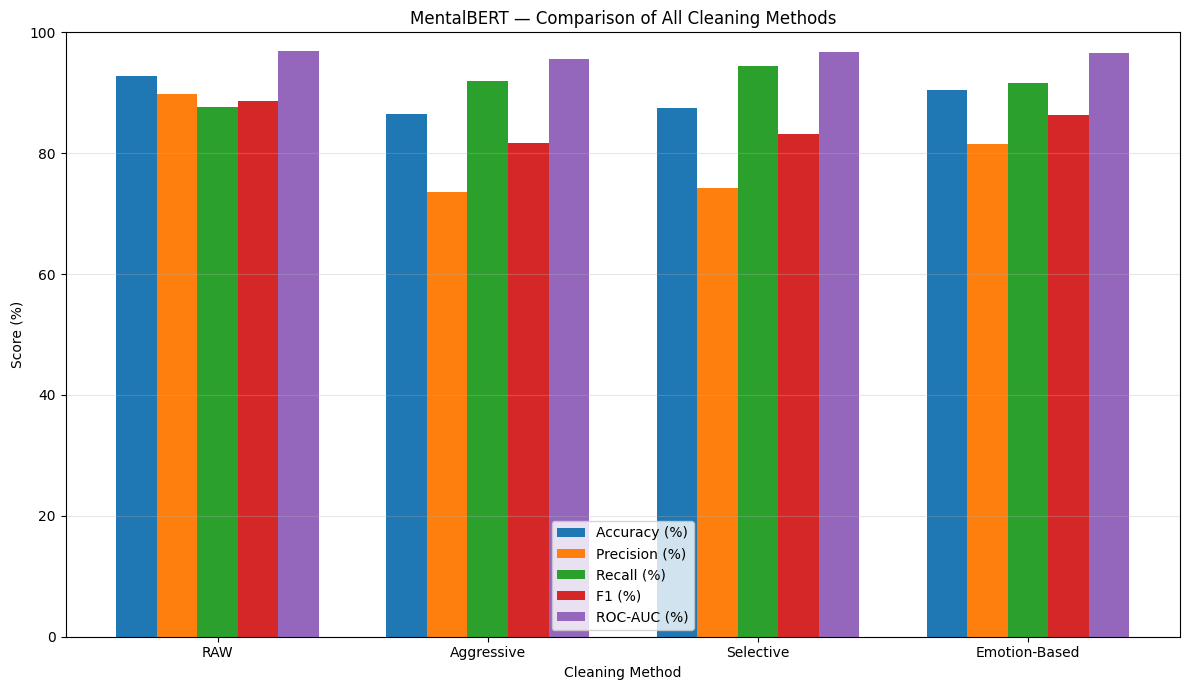

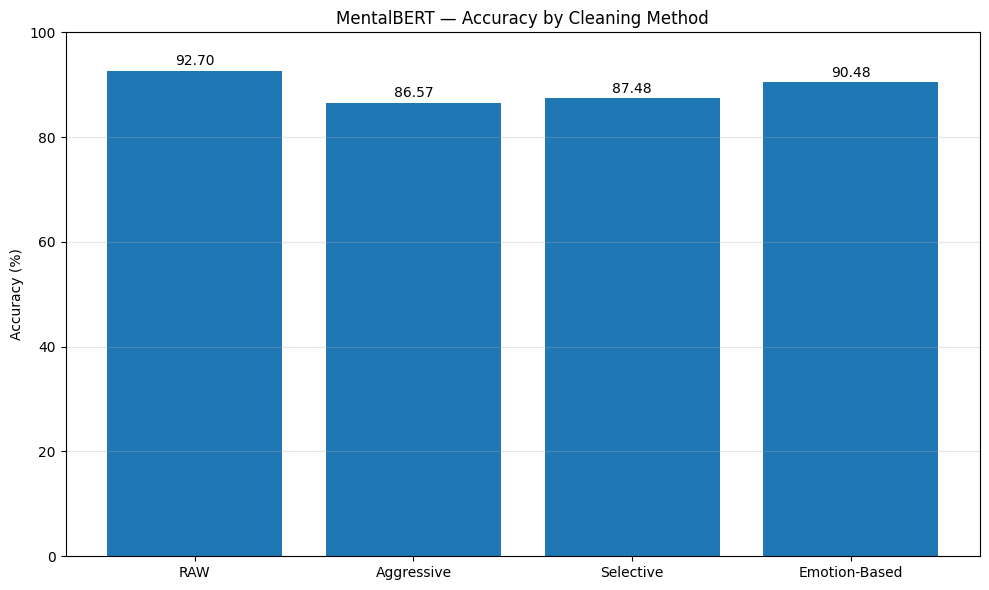

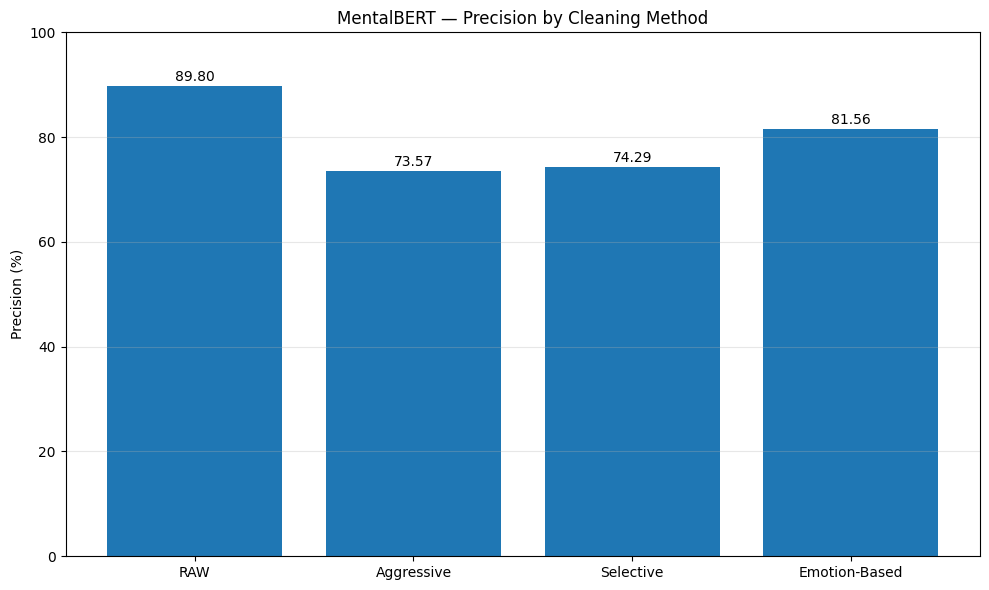

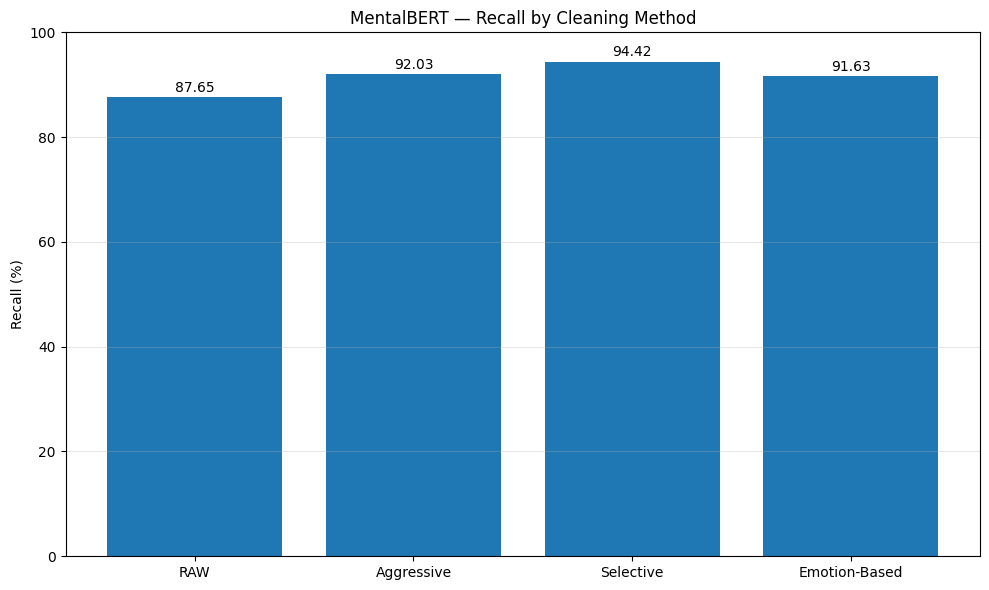

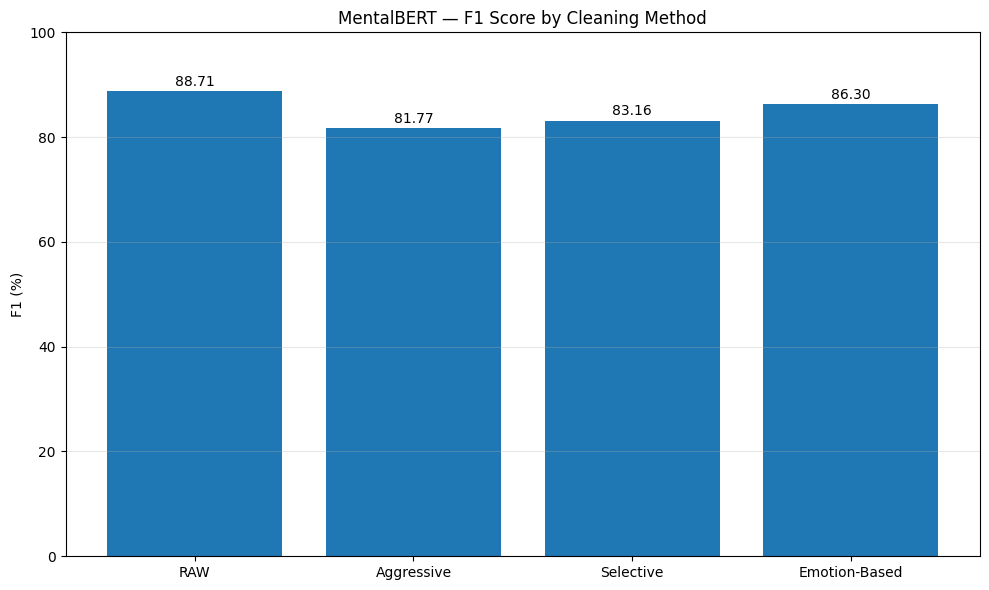

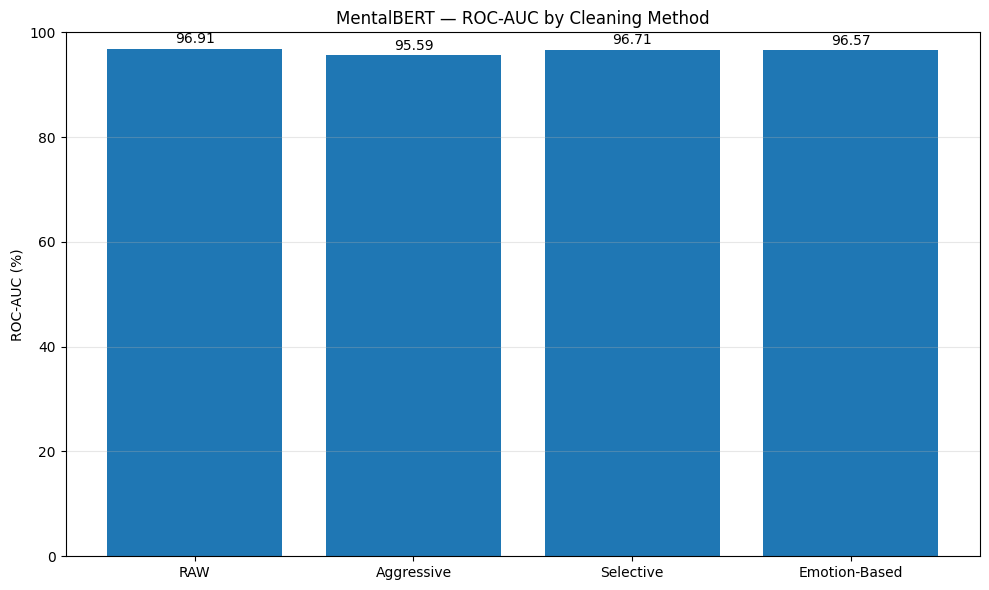

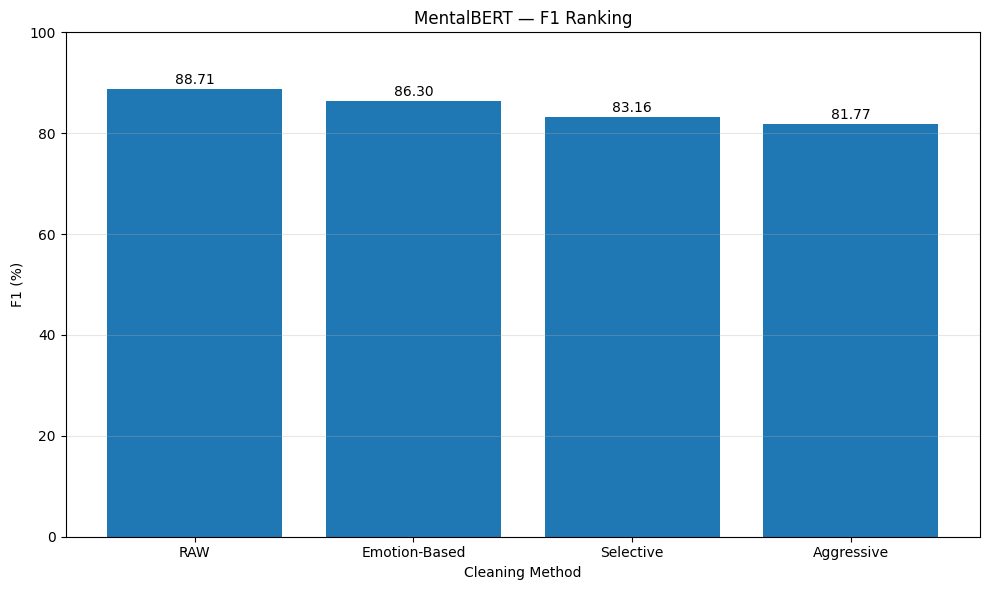

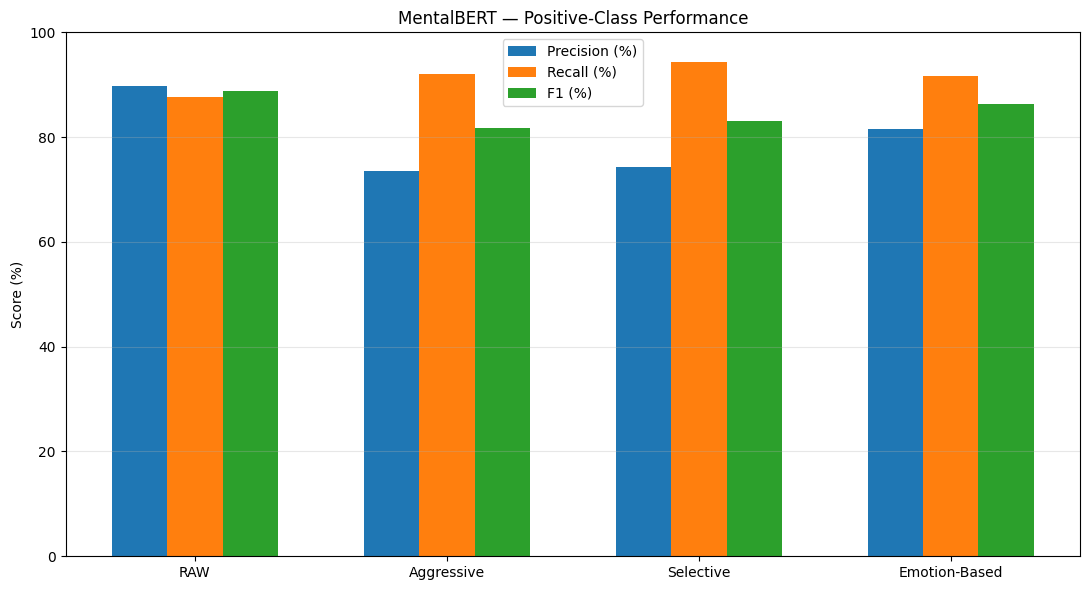

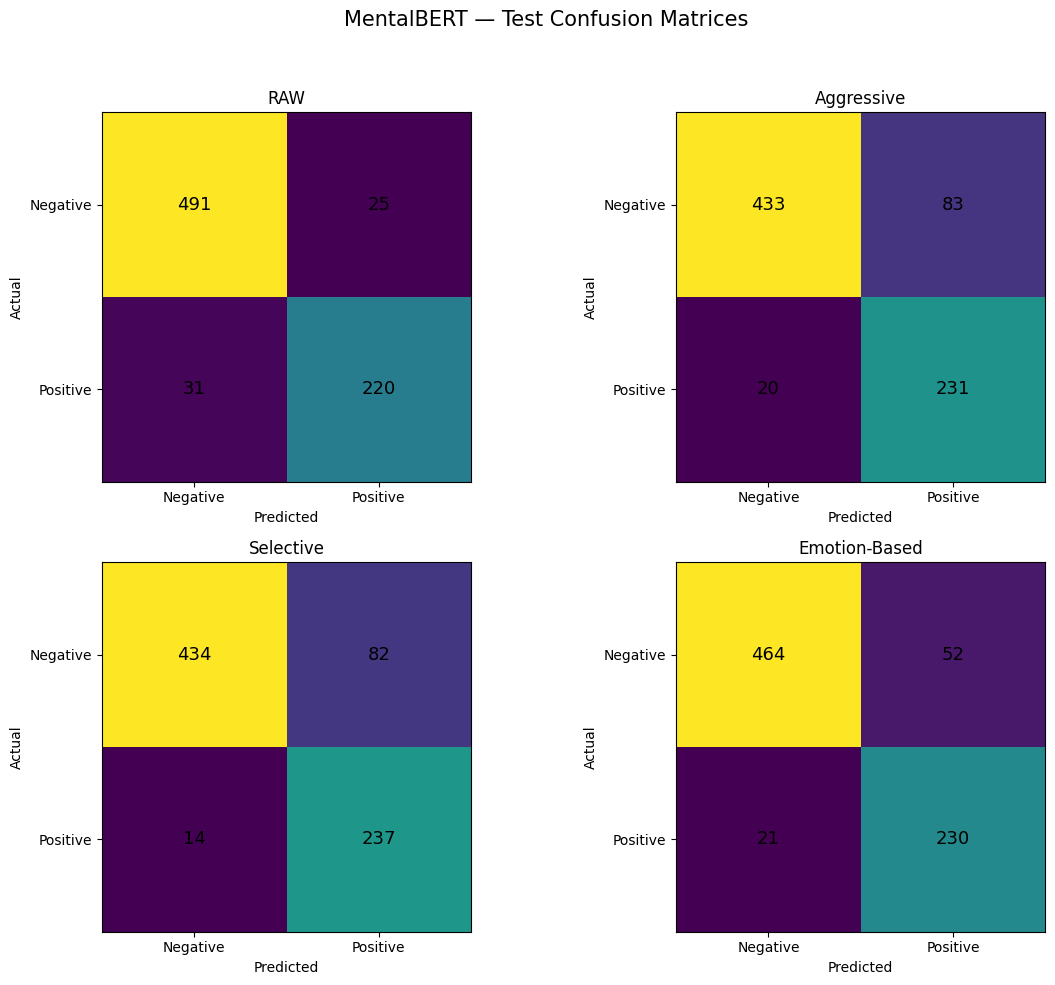

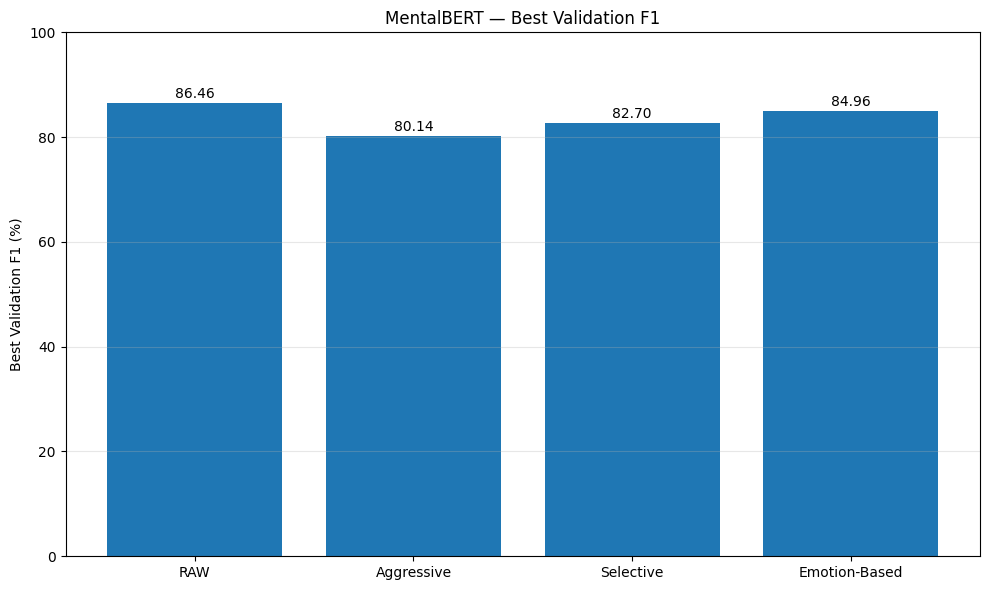


MENTALBERT ALL-4 COMPARISON COMPLETE

Sequence:
RAW → Aggressive → Selective → Emotion-Based

Master CSV:
/kaggle/working/mentalbert_all4_comparison/tables/MentalBERT_All4_Master_Comparison.csv

Excel:
/kaggle/working/mentalbert_all4_comparison/MentalBERT_All4_Cleaning_Comparison.xlsx

Figures:
/kaggle/working/mentalbert_all4_comparison/figures

Tables:
/kaggle/working/mentalbert_all4_comparison/tables

✓ 4 cleaning methods included
✓ Master comparison saved
✓ Best-by-metric table saved
✓ Confusion matrices saved
✓ 10 comparison figures saved
✓ Excel workbook saved
✓ JSON summary saved


In [15]:
# ============================================================
# MENTALBERT — ALL 4 CLEANING METHODS
# FINAL COMPARISON TABLE + GRAPHS + SAVED RESULTS
# ============================================================

import os
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import confusion_matrix


# ============================================================
# OUTPUT DIRECTORIES
# ============================================================

BASE_DIR = "/kaggle/working/mentalbert_all4_comparison"

FIGURE_DIR = os.path.join(
    BASE_DIR,
    "figures"
)

TABLE_DIR = os.path.join(
    BASE_DIR,
    "tables"
)

os.makedirs(
    FIGURE_DIR,
    exist_ok=True
)

os.makedirs(
    TABLE_DIR,
    exist_ok=True
)


# ============================================================
# EXPERIMENT ORDER
# IMPORTANT: DO NOT CHANGE
# ============================================================

comparison_data = [

    {
        "Model Name": "MentalBERT",
        "Cleaning Method": "RAW",
        "Accuracy (%)": 92.70,
        "Precision (%)": 89.80,
        "Recall (%)": 87.65,
        "F1 (%)": 88.71,
        "ROC-AUC (%)": 96.91,
        "Best Epoch": 1,
        "Best Val F1 (%)": 86.46,
        "Parameters (M)": 110.253,
        "TN": 491,
        "FP": 25,
        "FN": 31,
        "TP": 220
    },

    {
        "Model Name": "MentalBERT",
        "Cleaning Method": "Aggressive",
        "Accuracy (%)": 86.57,
        "Precision (%)": 73.57,
        "Recall (%)": 92.03,
        "F1 (%)": 81.77,
        "ROC-AUC (%)": 95.59,
        "Best Epoch": 3,
        "Best Val F1 (%)": 80.14,
        "Parameters (M)": 110.253,
        "TN": 433,
        "FP": 83,
        "FN": 20,
        "TP": 231
    },

    {
        "Model Name": "MentalBERT",
        "Cleaning Method": "Selective",
        "Accuracy (%)": 87.48,
        "Precision (%)": 74.29,
        "Recall (%)": 94.42,
        "F1 (%)": 83.16,
        "ROC-AUC (%)": 96.71,
        "Best Epoch": 5,
        "Best Val F1 (%)": 82.70,
        "Parameters (M)": 110.253,
        "TN": 434,
        "FP": 82,
        "FN": 14,
        "TP": 237
    },

    {
        "Model Name": "MentalBERT",
        "Cleaning Method": "Emotion-Based",
        "Accuracy (%)": 90.48,
        "Precision (%)": 81.56,
        "Recall (%)": 91.63,
        "F1 (%)": 86.30,
        "ROC-AUC (%)": 96.57,
        "Best Epoch": 4,
        "Best Val F1 (%)": 84.96,
        "Parameters (M)": 110.253,
        "TN": 464,
        "FP": 52,
        "FN": 21,
        "TP": 230
    }
]


# ============================================================
# MASTER COMPARISON DATAFRAME
# ============================================================

comparison_df = pd.DataFrame(
    comparison_data
)

print("=" * 90)
print("MENTALBERT — MASTER COMPARISON TABLE")
print("=" * 90)

print(
    comparison_df.to_string(
        index=False
    )
)


# ============================================================
# SAVE MASTER CSV
# ============================================================

master_csv_path = os.path.join(
    TABLE_DIR,
    "MentalBERT_All4_Master_Comparison.csv"
)

comparison_df.to_csv(
    master_csv_path,
    index=False
)


# ============================================================
# BEST RESULT FOR EACH METRIC
# ============================================================

metric_columns = [
    "Accuracy (%)",
    "Precision (%)",
    "Recall (%)",
    "F1 (%)",
    "ROC-AUC (%)"
]

best_rows = []

for metric in metric_columns:

    best_idx = comparison_df[
        metric
    ].idxmax()

    row = comparison_df.loc[
        best_idx
    ]

    best_rows.append({

        "Metric":
            metric,

        "Best Score":
            row[metric],

        "Model Name":
            row["Model Name"],

        "Cleaning Method":
            row["Cleaning Method"]
    })


best_metrics_df = pd.DataFrame(
    best_rows
)

print()
print("=" * 90)
print("BEST RESULT FOR EACH METRIC")
print("=" * 90)

print(
    best_metrics_df.to_string(
        index=False
    )
)

best_metrics_df.to_csv(
    os.path.join(
        TABLE_DIR,
        "MentalBERT_Best_By_Metric.csv"
    ),
    index=False
)


# ============================================================
# CONFUSION MATRIX TABLE
# ============================================================

cm_df = comparison_df[
    [
        "Cleaning Method",
        "TN",
        "FP",
        "FN",
        "TP"
    ]
].copy()

print()
print("=" * 90)
print("CONFUSION MATRIX VALUES")
print("=" * 90)

print(
    cm_df.to_string(
        index=False
    )
)

cm_df.to_csv(
    os.path.join(
        TABLE_DIR,
        "MentalBERT_Confusion_Matrices.csv"
    ),
    index=False
)


# ============================================================
# GRAPH 1 — ALL MAIN METRICS
# ============================================================

methods = comparison_df[
    "Cleaning Method"
].tolist()

x = np.arange(
    len(methods)
)

metric_plot_columns = [
    "Accuracy (%)",
    "Precision (%)",
    "Recall (%)",
    "F1 (%)",
    "ROC-AUC (%)"
]

plt.figure(
    figsize=(12, 7)
)

width = 0.15

for i, metric in enumerate(
    metric_plot_columns
):

    values = comparison_df[
        metric
    ].values

    plt.bar(
        x + (
            i - 2
        ) * width,
        values,
        width,
        label=metric
    )

plt.xticks(
    x,
    methods
)

plt.ylabel(
    "Score (%)"
)

plt.xlabel(
    "Cleaning Method"
)

plt.title(
    "MentalBERT — Comparison of All Cleaning Methods"
)

plt.ylim(
    0,
    100
)

plt.legend()

plt.grid(
    axis="y",
    alpha=0.3
)

plt.tight_layout()

plt.savefig(
    os.path.join(
        FIGURE_DIR,
        "01_all_metrics_comparison.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# GRAPH 2 — ACCURACY
# ============================================================

plt.figure(
    figsize=(10, 6)
)

values = comparison_df[
    "Accuracy (%)"
].values

bars = plt.bar(
    methods,
    values
)

plt.ylabel(
    "Accuracy (%)"
)

plt.title(
    "MentalBERT — Accuracy by Cleaning Method"
)

plt.ylim(
    0,
    100
)

for bar, value in zip(
    bars,
    values
):

    plt.text(
        bar.get_x()
        + bar.get_width() / 2,
        value + 1,
        f"{value:.2f}",
        ha="center"
    )

plt.grid(
    axis="y",
    alpha=0.3
)

plt.tight_layout()

plt.savefig(
    os.path.join(
        FIGURE_DIR,
        "02_accuracy_comparison.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# GRAPH 3 — PRECISION
# ============================================================

plt.figure(
    figsize=(10, 6)
)

values = comparison_df[
    "Precision (%)"
].values

bars = plt.bar(
    methods,
    values
)

plt.ylabel(
    "Precision (%)"
)

plt.title(
    "MentalBERT — Precision by Cleaning Method"
)

plt.ylim(
    0,
    100
)

for bar, value in zip(
    bars,
    values
):

    plt.text(
        bar.get_x()
        + bar.get_width() / 2,
        value + 1,
        f"{value:.2f}",
        ha="center"
    )

plt.grid(
    axis="y",
    alpha=0.3
)

plt.tight_layout()

plt.savefig(
    os.path.join(
        FIGURE_DIR,
        "03_precision_comparison.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# GRAPH 4 — RECALL
# ============================================================

plt.figure(
    figsize=(10, 6)
)

values = comparison_df[
    "Recall (%)"
].values

bars = plt.bar(
    methods,
    values
)

plt.ylabel(
    "Recall (%)"
)

plt.title(
    "MentalBERT — Recall by Cleaning Method"
)

plt.ylim(
    0,
    100
)

for bar, value in zip(
    bars,
    values
):

    plt.text(
        bar.get_x()
        + bar.get_width() / 2,
        value + 1,
        f"{value:.2f}",
        ha="center"
    )

plt.grid(
    axis="y",
    alpha=0.3
)

plt.tight_layout()

plt.savefig(
    os.path.join(
        FIGURE_DIR,
        "04_recall_comparison.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# GRAPH 5 — F1
# ============================================================

plt.figure(
    figsize=(10, 6)
)

values = comparison_df[
    "F1 (%)"
].values

bars = plt.bar(
    methods,
    values
)

plt.ylabel(
    "F1 (%)"
)

plt.title(
    "MentalBERT — F1 Score by Cleaning Method"
)

plt.ylim(
    0,
    100
)

for bar, value in zip(
    bars,
    values
):

    plt.text(
        bar.get_x()
        + bar.get_width() / 2,
        value + 1,
        f"{value:.2f}",
        ha="center"
    )

plt.grid(
    axis="y",
    alpha=0.3
)

plt.tight_layout()

plt.savefig(
    os.path.join(
        FIGURE_DIR,
        "05_f1_comparison.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# GRAPH 6 — ROC-AUC
# ============================================================

plt.figure(
    figsize=(10, 6)
)

values = comparison_df[
    "ROC-AUC (%)"
].values

bars = plt.bar(
    methods,
    values
)

plt.ylabel(
    "ROC-AUC (%)"
)

plt.title(
    "MentalBERT — ROC-AUC by Cleaning Method"
)

plt.ylim(
    0,
    100
)

for bar, value in zip(
    bars,
    values
):

    plt.text(
        bar.get_x()
        + bar.get_width() / 2,
        value + 1,
        f"{value:.2f}",
        ha="center"
    )

plt.grid(
    axis="y",
    alpha=0.3
)

plt.tight_layout()

plt.savefig(
    os.path.join(
        FIGURE_DIR,
        "06_roc_auc_comparison.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# GRAPH 7 — F1 RANKING
# ============================================================

f1_ranked = (
    comparison_df
    .sort_values(
        "F1 (%)",
        ascending=False
    )
)

plt.figure(
    figsize=(10, 6)
)

bars = plt.bar(
    f1_ranked[
        "Cleaning Method"
    ],
    f1_ranked[
        "F1 (%)"
    ]
)

plt.ylabel(
    "F1 (%)"
)

plt.xlabel(
    "Cleaning Method"
)

plt.title(
    "MentalBERT — F1 Ranking"
)

plt.ylim(
    0,
    100
)

for bar, value in zip(
    bars,
    f1_ranked[
        "F1 (%)"
    ]
):

    plt.text(
        bar.get_x()
        + bar.get_width() / 2,
        value + 1,
        f"{value:.2f}",
        ha="center"
    )

plt.grid(
    axis="y",
    alpha=0.3
)

plt.tight_layout()

plt.savefig(
    os.path.join(
        FIGURE_DIR,
        "07_f1_ranking.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# GRAPH 8 — POSITIVE CLASS METRICS
# ============================================================

positive_metrics = [
    "Precision (%)",
    "Recall (%)",
    "F1 (%)"
]

plt.figure(
    figsize=(11, 6)
)

width = 0.22

for i, metric in enumerate(
    positive_metrics
):

    plt.bar(
        x + (
            i - 1
        ) * width,

        comparison_df[
            metric
        ],

        width,

        label=metric
    )

plt.xticks(
    x,
    methods
)

plt.ylabel(
    "Score (%)"
)

plt.title(
    "MentalBERT — Positive-Class Performance"
)

plt.ylim(
    0,
    100
)

plt.legend()

plt.grid(
    axis="y",
    alpha=0.3
)

plt.tight_layout()

plt.savefig(
    os.path.join(
        FIGURE_DIR,
        "08_positive_class_metrics.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# GRAPH 9 — CONFUSION MATRICES
# ============================================================

fig, axes = plt.subplots(
    2,
    2,
    figsize=(12, 10)
)

for ax, (_, row) in zip(
    axes.flatten(),
    comparison_df.iterrows()
):

    matrix = np.array([
        [
            row["TN"],
            row["FP"]
        ],
        [
            row["FN"],
            row["TP"]
        ]
    ])

    ax.imshow(
        matrix,
        interpolation="nearest"
    )

    ax.set_title(
        row[
            "Cleaning Method"
        ]
    )

    ax.set_xlabel(
        "Predicted"
    )

    ax.set_ylabel(
        "Actual"
    )

    ax.set_xticks(
        [0, 1]
    )

    ax.set_yticks(
        [0, 1]
    )

    ax.set_xticklabels(
        ["Negative", "Positive"]
    )

    ax.set_yticklabels(
        ["Negative", "Positive"]
    )

    for i in range(2):

        for j in range(2):

            ax.text(
                j,
                i,
                str(
                    matrix[i, j]
                ),
                ha="center",
                va="center",
                fontsize=13
            )

plt.suptitle(
    "MentalBERT — Test Confusion Matrices",
    fontsize=15
)

plt.tight_layout(
    rect=[
        0,
        0,
        1,
        0.95
    ]
)

plt.savefig(
    os.path.join(
        FIGURE_DIR,
        "09_all_confusion_matrices.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# GRAPH 10 — BEST VALIDATION F1
# ============================================================

plt.figure(
    figsize=(10, 6)
)

values = comparison_df[
    "Best Val F1 (%)"
].values

bars = plt.bar(
    methods,
    values
)

plt.ylabel(
    "Best Validation F1 (%)"
)

plt.title(
    "MentalBERT — Best Validation F1"
)

plt.ylim(
    0,
    100
)

for bar, value in zip(
    bars,
    values
):

    plt.text(
        bar.get_x()
        + bar.get_width() / 2,
        value + 1,
        f"{value:.2f}",
        ha="center"
    )

plt.grid(
    axis="y",
    alpha=0.3
)

plt.tight_layout()

plt.savefig(
    os.path.join(
        FIGURE_DIR,
        "10_best_validation_f1.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# GRAPH INDEX
# ============================================================

graph_index = pd.DataFrame({

    "Figure": [

        "01_all_metrics_comparison.png",

        "02_accuracy_comparison.png",

        "03_precision_comparison.png",

        "04_recall_comparison.png",

        "05_f1_comparison.png",

        "06_roc_auc_comparison.png",

        "07_f1_ranking.png",

        "08_positive_class_metrics.png",

        "09_all_confusion_matrices.png",

        "10_best_validation_f1.png"
    ],

    "Description": [

        "Accuracy, Precision, Recall, F1 and ROC-AUC",

        "Test Accuracy",

        "Test Precision",

        "Test Recall",

        "Test F1",

        "Test ROC-AUC",

        "F1 ranking",

        "Positive-class Precision, Recall and F1",

        "Confusion matrices for all four cleaning methods",

        "Best validation F1"
    ]
})


graph_index.to_csv(
    os.path.join(
        TABLE_DIR,
        "Graph_Index.csv"
    ),
    index=False
)


# ============================================================
# EXCEL WORKBOOK
# ============================================================

excel_path = os.path.join(
    BASE_DIR,
    "MentalBERT_All4_Cleaning_Comparison.xlsx"
)


with pd.ExcelWriter(
    excel_path,
    engine="openpyxl"
) as writer:

    comparison_df.to_excel(
        writer,
        sheet_name="Master Comparison",
        index=False
    )

    best_metrics_df.to_excel(
        writer,
        sheet_name="Best By Metric",
        index=False
    )

    cm_df.to_excel(
        writer,
        sheet_name="Confusion Matrices",
        index=False
    )

    graph_index.to_excel(
        writer,
        sheet_name="Graph Index",
        index=False
    )


# ============================================================
# JSON SUMMARY
# ============================================================

summary = {

    "model":
        "MentalBERT",

    "cleaning_order": methods,

    "best_by_f1":
        best_metrics_df.loc[
            best_metrics_df["Metric"]
            == "F1 (%)"
        ].iloc[0].to_dict(),

    "best_by_accuracy":
        best_metrics_df.loc[
            best_metrics_df["Metric"]
            == "Accuracy (%)"
        ].iloc[0].to_dict(),

    "best_by_recall":
        best_metrics_df.loc[
            best_metrics_df["Metric"]
            == "Recall (%)"
        ].iloc[0].to_dict(),

    "best_by_roc_auc":
        best_metrics_df.loc[
            best_metrics_df["Metric"]
            == "ROC-AUC (%)"
        ].iloc[0].to_dict(),

    "output_directory":
        BASE_DIR
}


with open(
    os.path.join(
        BASE_DIR,
        "MentalBERT_All4_Summary.json"
    ),
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        summary,
        f,
        indent=2
    )


# ============================================================
# FINAL OUTPUT
# ============================================================

print()
print("=" * 90)
print("MENTALBERT ALL-4 COMPARISON COMPLETE")
print("=" * 90)

print()
print("Sequence:")
print(
    "RAW → Aggressive → Selective → Emotion-Based"
)

print()
print(
    "Master CSV:"
)
print(
    master_csv_path
)

print()
print(
    "Excel:"
)
print(
    excel_path
)

print()
print(
    "Figures:"
)
print(
    FIGURE_DIR
)

print()
print(
    "Tables:"
)
print(
    TABLE_DIR
)

print()
print(
    "✓ 4 cleaning methods included"
)

print(
    "✓ Master comparison saved"
)

print(
    "✓ Best-by-metric table saved"
)

print(
    "✓ Confusion matrices saved"
)

print(
    "✓ 10 comparison figures saved"
)

print(
    "✓ Excel workbook saved"
)

print(
    "✓ JSON summary saved"
)

t-SNE REPRESENTATION ANALYSIS
MENTALBERT + EMOTION-BASED

✓ MentalBERT model in evaluation mode

EXTRACTING FUSED REPRESENTATIONS
Processed batch 1/48
Processed batch 10/48
Processed batch 20/48
Processed batch 30/48
Processed batch 40/48
Processed batch 48/48

FUSED REPRESENTATION SUMMARY
Fused representation shape: (767, 832)
Test users: 767
Fused dimensions: 832
Negative users: 516
Positive users: 251
Metadata gate: 0.500049

PCA REDUCTION
Original dimensions: 832
PCA dimensions: 50
Variance retained: 99.25%

t-SNE REDUCTION
t-SNE output shape: (767, 2)


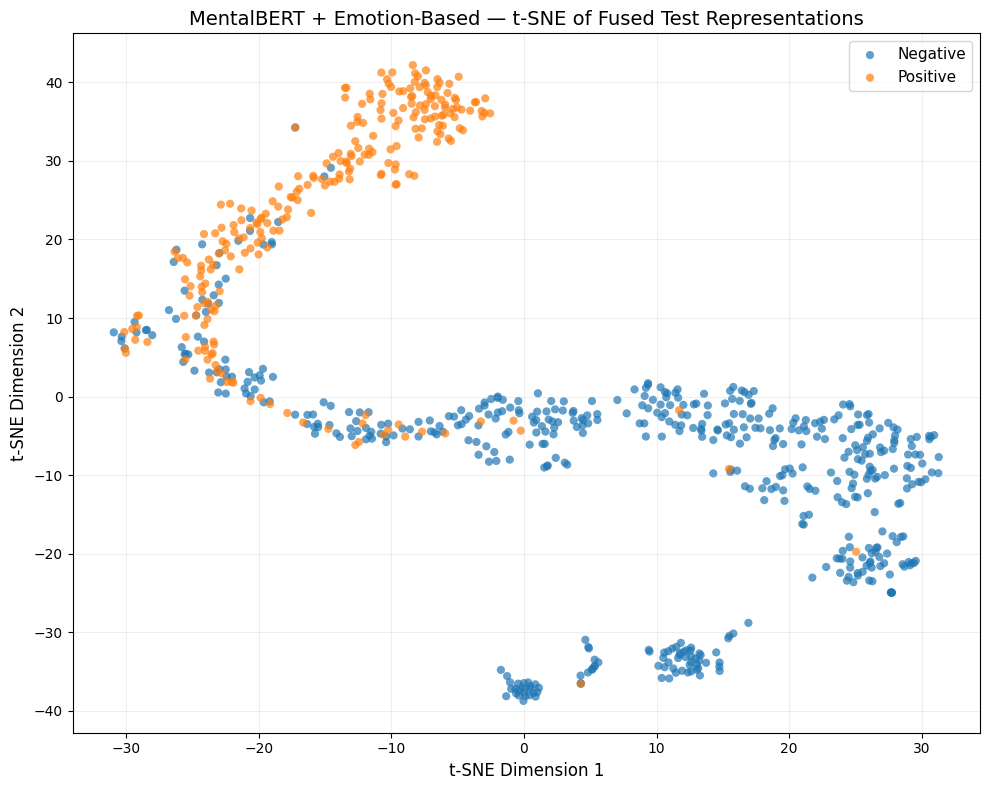


t-SNE ANALYSIS COMPLETE
✓ MentalBERT fused representation extracted
✓ PCA reduction completed
✓ t-SNE reduction completed
✓ t-SNE graph saved:
/kaggle/working/mentalbert_emotion/explainability/tsne/mentalbert_emotion_tsne.png
✓ t-SNE graph displayed above
✓ Coordinates saved:
/kaggle/working/mentalbert_emotion/explainability/tsne/mentalbert_emotion_tsne_coordinates.csv
✓ Configuration saved


In [21]:
# ============================================================
# CELL 15 — MENTALBERT + EMOTION-BASED
# t-SNE REPRESENTATION ANALYSIS
# ============================================================

import os
import json
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

from sklearn.decomposition import PCA
from sklearn.manifold import TSNE

print("=" * 70)
print("t-SNE REPRESENTATION ANALYSIS")
print("MENTALBERT + EMOTION-BASED")
print("=" * 70)

# ============================================================
# FIXED EXPLAINABILITY SETTINGS
# ============================================================

EXPLAINABILITY_SEED = 42

PCA_COMPONENTS = 50

TSNE_COMPONENTS = 2
TSNE_PERPLEXITY = 30
TSNE_LEARNING_RATE = 200
TSNE_MAX_ITER = 1000

np.random.seed(
    EXPLAINABILITY_SEED
)

torch.manual_seed(
    EXPLAINABILITY_SEED
)

# ============================================================
# OUTPUT DIRECTORIES
# ============================================================

EXPLAINABILITY_DIR = os.path.join(
    BASE_RESULT_DIR,
    "explainability"
)

TSNE_DIR = os.path.join(
    EXPLAINABILITY_DIR,
    "tsne"
)

os.makedirs(
    TSNE_DIR,
    exist_ok=True
)

# ============================================================
# MODEL
# ============================================================

model_mental_emotion.eval()

print()
print("✓ MentalBERT model in evaluation mode")

# ============================================================
# EXTRACT FUSED REPRESENTATIONS
# ============================================================

fused_representations = []
test_labels = []

print()
print("=" * 70)
print("EXTRACTING FUSED REPRESENTATIONS")
print("=" * 70)

with torch.no_grad():

    for batch_idx, batch in enumerate(
        test_mental_emotion_loader,
        start=1
    ):

        input_ids = batch[
            "input_ids"
        ].to(device)

        attention_mask = batch[
            "attention_mask"
        ].to(device)

        metadata = batch[
            "metadata"
        ].to(device)

        labels = batch[
            "labels"
        ].to(device)

        output = model_mental_emotion(
            input_ids=input_ids,
            attention_mask=attention_mask,
            metadata=metadata
        )

        # ----------------------------------------------------
        # ACTUAL REPRESENTATIONS FROM THIS MODEL
        # ----------------------------------------------------

        text_representation = output[
            "text_representation"
        ]

        metadata_representation = output[
            "metadata_representation"
        ]

        # ----------------------------------------------------
        # LEARNED METADATA GATE
        # ----------------------------------------------------

        metadata_gate = torch.sigmoid(
            model_mental_emotion.metadata_beta
        )

        gated_metadata = (
            metadata_gate
            *
            metadata_representation
        )

        # ----------------------------------------------------
        # EXACT FUSED REPRESENTATION USED BY CLASSIFIER
        # ----------------------------------------------------

        fused = torch.cat(
            [
                text_representation,
                gated_metadata
            ],
            dim=1
        )

        fused_representations.append(
            fused.cpu().numpy()
        )

        test_labels.extend(
            labels.cpu().numpy().tolist()
        )

        if (
            batch_idx == 1
            or batch_idx % 10 == 0
            or batch_idx == len(test_mental_emotion_loader)
        ):

            print(
                f"Processed batch "
                f"{batch_idx}/{len(test_mental_emotion_loader)}"
            )

# ============================================================
# COMBINE
# ============================================================

fused_representations = np.concatenate(
    fused_representations,
    axis=0
)

test_labels = np.array(
    test_labels
)

# ============================================================
# REPRESENTATION CHECK
# ============================================================

print()
print("=" * 70)
print("FUSED REPRESENTATION SUMMARY")
print("=" * 70)

print(
    "Fused representation shape:",
    fused_representations.shape
)

print(
    "Test users:",
    len(test_labels)
)

print(
    "Fused dimensions:",
    fused_representations.shape[1]
)

print(
    "Negative users:",
    int(
        (test_labels == 0).sum()
    )
)

print(
    "Positive users:",
    int(
        (test_labels == 1).sum()
    )
)

print(
    "Metadata gate:",
    f"{float(metadata_gate.item()):.6f}"
)

assert (
    fused_representations.shape[0]
    ==
    len(test_labels)
)

assert np.isfinite(
    fused_representations
).all()

# ============================================================
# PCA
# ============================================================

print()
print("=" * 70)
print("PCA REDUCTION")
print("=" * 70)

pca_dimensions = min(
    PCA_COMPONENTS,
    fused_representations.shape[1]
)

pca = PCA(
    n_components=pca_dimensions,
    random_state=EXPLAINABILITY_SEED
)

pca_representation = pca.fit_transform(
    fused_representations
)

pca_variance_retained = (
    pca.explained_variance_ratio_.sum()
)

print(
    "Original dimensions:",
    fused_representations.shape[1]
)

print(
    "PCA dimensions:",
    pca_representation.shape[1]
)

print(
    "Variance retained:",
    f"{pca_variance_retained * 100:.2f}%"
)

# ============================================================
# t-SNE
# ============================================================

print()
print("=" * 70)
print("t-SNE REDUCTION")
print("=" * 70)

tsne = TSNE(
    n_components=TSNE_COMPONENTS,
    perplexity=TSNE_PERPLEXITY,
    learning_rate=TSNE_LEARNING_RATE,
    init="pca",
    random_state=EXPLAINABILITY_SEED,
    max_iter=TSNE_MAX_ITER
)

tsne_representation = tsne.fit_transform(
    pca_representation
)

print(
    "t-SNE output shape:",
    tsne_representation.shape
)

# ============================================================
# SAVE t-SNE COORDINATES
# ============================================================

tsne_df = pd.DataFrame({

    "tsne_1":
        tsne_representation[:, 0],

    "tsne_2":
        tsne_representation[:, 1],

    "label":
        test_labels

})

tsne_df["class"] = tsne_df[
    "label"
].map({
    0: "Negative",
    1: "Positive"
})

tsne_csv_path = os.path.join(
    TSNE_DIR,
    "mentalbert_emotion_tsne_coordinates.csv"
)

tsne_df.to_csv(
    tsne_csv_path,
    index=False
)

# ============================================================
# PUBLICATION-QUALITY t-SNE PLOT
# ============================================================

plt.figure(
    figsize=(10, 8)
)

negative_mask = (
    test_labels == 0
)

positive_mask = (
    test_labels == 1
)

plt.scatter(
    tsne_representation[
        negative_mask,
        0
    ],
    tsne_representation[
        negative_mask,
        1
    ],
    s=35,
    alpha=0.70,
    label="Negative",
    edgecolors="none"
)

plt.scatter(
    tsne_representation[
        positive_mask,
        0
    ],
    tsne_representation[
        positive_mask,
        1
    ],
    s=35,
    alpha=0.70,
    label="Positive",
    edgecolors="none"
)

plt.xlabel(
    "t-SNE Dimension 1",
    fontsize=12
)

plt.ylabel(
    "t-SNE Dimension 2",
    fontsize=12
)

plt.title(
    "MentalBERT + Emotion-Based — "
    "t-SNE of Fused Test Representations",
    fontsize=14
)

plt.legend(
    fontsize=11
)

plt.grid(
    alpha=0.20
)

plt.tight_layout()

tsne_plot_path = os.path.join(
    TSNE_DIR,
    "mentalbert_emotion_tsne.png"
)

# SAVE
plt.savefig(
    tsne_plot_path,
    dpi=300,
    bbox_inches="tight"
)

# DISPLAY
plt.show()

plt.close()

# ============================================================
# SAVE CONFIGURATION
# ============================================================

tsne_config = {

    "model":
        "MentalBERT",

    "base_encoder":
        MODEL_NAME,

    "cleaning":
        "Emotion-Based",

    "dataset":
        "Held-out test set",

    "test_users":
        int(len(test_labels)),

    "input_representation":
        "Fused classifier representation",

    "text_representation_dimension":
        int(
            text_representation.shape[1]
        ),

    "metadata_representation_dimension":
        int(
            metadata_representation.shape[1]
        ),

    "fused_representation_dimension":
        int(
            fused_representations.shape[1]
        ),

    "pca_dimensions":
        int(pca_dimensions),

    "pca_variance_retained":
        float(
            pca_variance_retained
        ),

    "tsne_dimensions":
        int(TSNE_COMPONENTS),

    "tsne_perplexity":
        int(TSNE_PERPLEXITY),

    "tsne_learning_rate":
        TSNE_LEARNING_RATE,

    "tsne_max_iterations":
        int(TSNE_MAX_ITER),

    "random_seed":
        EXPLAINABILITY_SEED,

    "metadata_gate":
        float(
            metadata_gate.item()
        )

}

with open(
    os.path.join(
        TSNE_DIR,
        "mentalbert_emotion_tsne_config.json"
    ),
    "w"
) as f:

    json.dump(
        tsne_config,
        f,
        indent=2
    )

# ============================================================
# COMPLETE
# ============================================================

print()
print("=" * 70)
print("t-SNE ANALYSIS COMPLETE")
print("=" * 70)

print(
    "✓ MentalBERT fused representation extracted"
)

print(
    "✓ PCA reduction completed"
)

print(
    "✓ t-SNE reduction completed"
)

print(
    "✓ t-SNE graph saved:"
)

print(
    tsne_plot_path
)

print(
    "✓ t-SNE graph displayed above"
)

print(
    "✓ Coordinates saved:"
)

print(
    tsne_csv_path
)

print(
    "✓ Configuration saved"
)

SHAP ANALYSIS
MENTALBERT + EMOTION-BASED

Total metadata features: 53
SHAP background samples: 50

SHAP test samples: 100
Negative: 50
Positive: 50

✓ MentalBERT model set to evaluation mode
✓ No model parameters will be updated
✓ Text input remains fixed per user

COMPUTING SHAP VALUES
Explained 1/100 test users
Explained 10/100 test users
Explained 20/100 test users
Explained 30/100 test users
Explained 40/100 test users
Explained 50/100 test users
Explained 60/100 test users
Explained 70/100 test users
Explained 80/100 test users
Explained 90/100 test users
Explained 100/100 test users

SHAP RESULT SUMMARY
SHAP matrix: (100, 53)
Metadata matrix: (100, 53)

TOP 20 SHAP FEATURES
                feature  mean_abs_shap  mean_signed_shap
           lda_topic_17       0.000339          0.000047
        neg_emoji_count       0.000293         -0.000208
           lda_topic_14       0.000287         -0.000078
     hopelessness_score       0.000286          0.000047
         negation_ratio   

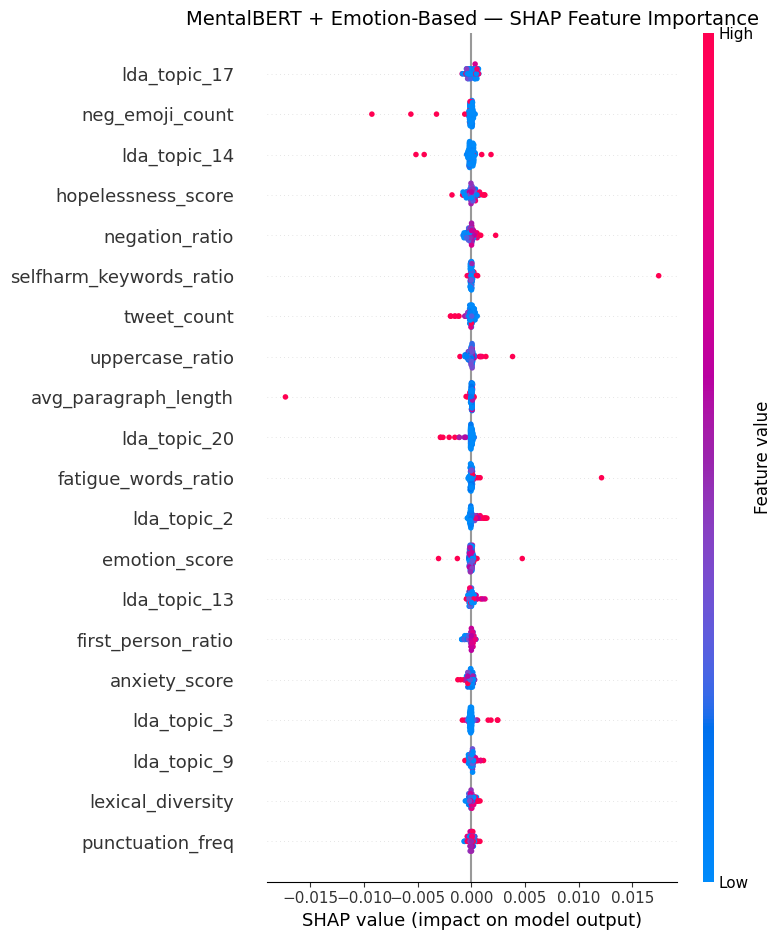

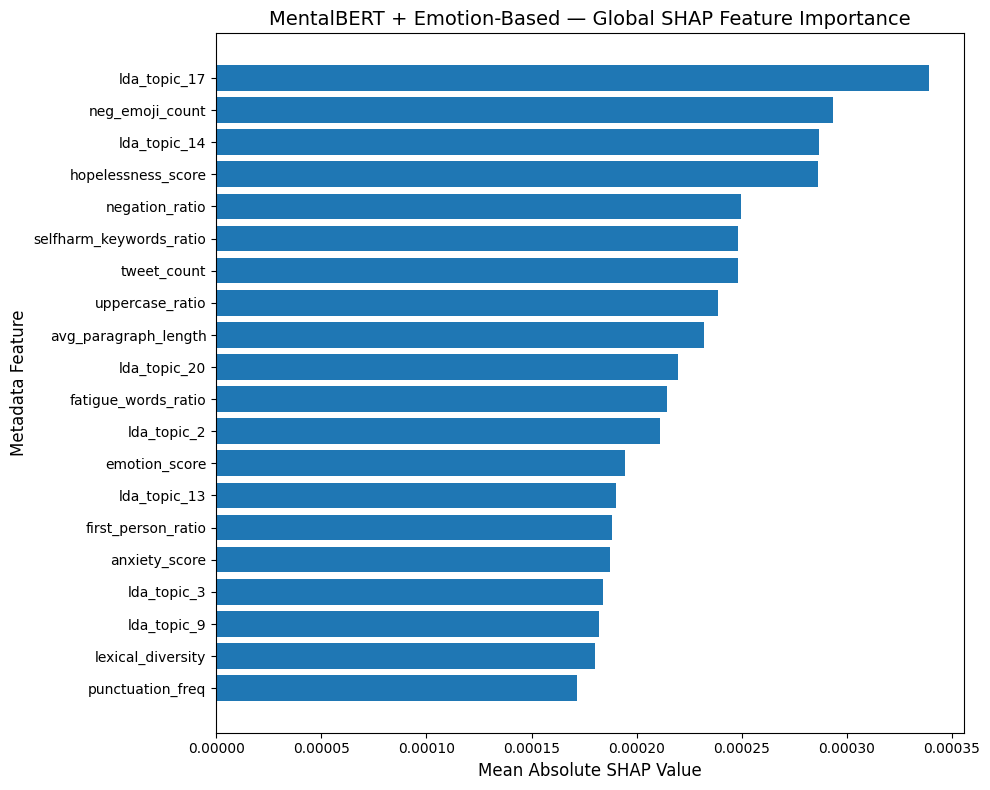


SHAP ANALYSIS COMPLETE
✓ 53 metadata features explained
✓ 100 fixed test users explained
✓ 50 negative + 50 positive
✓ Text input fixed per user
✓ Positive-class logit explained
✓ MentalBERT weights unchanged
✓ SHAP beeswarm saved and displayed
✓ SHAP bar plot saved and displayed
✓ SHAP values saved
✓ Feature ranking saved
✓ Configuration saved

SHAP output directory: /kaggle/working/mentalbert_emotion/explainability/shap


In [24]:
# ============================================================
# CELL 16 — MENTALBERT + EMOTION-BASED
# SHAP GLOBAL METADATA FEATURE EXPLANATION
# ============================================================

import os
import json
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
import shap

print("=" * 70)
print("SHAP ANALYSIS")
print("MENTALBERT + EMOTION-BASED")
print("=" * 70)

# ============================================================
# FIXED SHAP SETTINGS
# ============================================================

SHAP_SEED = 42
SHAP_BACKGROUND_SIZE = 50
SHAP_TEST_SIZE_PER_CLASS = 50
SHAP_TOP_FEATURES = 20

np.random.seed(SHAP_SEED)
torch.manual_seed(SHAP_SEED)

# ============================================================
# OUTPUT DIRECTORY
# ============================================================

SHAP_DIR = os.path.join(
    EXPLAINABILITY_DIR,
    "shap"
)

os.makedirs(
    SHAP_DIR,
    exist_ok=True
)

# ============================================================
# METADATA FEATURE NAMES
# ============================================================

feature_names = list(
    selected_metadata_names
)

assert len(feature_names) == 53

print()
print(
    "Total metadata features:",
    len(feature_names)
)

# ============================================================
# FIXED BACKGROUND
# TRAINING USERS ONLY
# ============================================================

background_metadata = (
    train_mental_emotion_dataset.metadata[
        :SHAP_BACKGROUND_SIZE
    ]
    .clone()
    .detach()
    .to(device)
)

print(
    "SHAP background samples:",
    background_metadata.shape[0]
)

assert background_metadata.shape[1] == 53

# ============================================================
# FIXED TEST USERS
# 50 NEGATIVE + 50 POSITIVE
# ============================================================

test_labels_tensor = (
    test_mental_emotion_dataset.labels
    .detach()
    .cpu()
)

negative_indices = torch.where(
    test_labels_tensor == 0
)[0].numpy()

positive_indices = torch.where(
    test_labels_tensor == 1
)[0].numpy()

assert len(negative_indices) >= 50
assert len(positive_indices) >= 50

shap_negative_indices = (
    negative_indices[
        :SHAP_TEST_SIZE_PER_CLASS
    ]
)

shap_positive_indices = (
    positive_indices[
        :SHAP_TEST_SIZE_PER_CLASS
    ]
)

shap_test_indices = np.concatenate(
    [
        shap_negative_indices,
        shap_positive_indices
    ]
)

print()
print(
    "SHAP test samples:",
    len(shap_test_indices)
)

print(
    "Negative:",
    len(shap_negative_indices)
)

print(
    "Positive:",
    len(shap_positive_indices)
)

# ============================================================
# MODEL WRAPPER
# ============================================================
# Text representation remains fixed for each user
# while the 53 metadata features are varied.

class MetadataSHAPWrapper(
    nn.Module
):

    def __init__(
        self,
        base_model,
        fixed_input_ids,
        fixed_attention_mask
    ):

        super().__init__()

        self.base_model = base_model

        self.fixed_input_ids = (
            fixed_input_ids.to(device)
        )

        self.fixed_attention_mask = (
            fixed_attention_mask.to(device)
        )

    def forward(
        self,
        metadata
    ):

        batch_size = metadata.size(0)

        input_ids = (
            self.fixed_input_ids
            .expand(batch_size, -1)
        )

        attention_mask = (
            self.fixed_attention_mask
            .expand(batch_size, -1)
        )

        output = self.base_model(
            input_ids=input_ids,
            attention_mask=attention_mask,
            metadata=metadata
        )

        # Positive/depression class logit
        return output[
            "logits"
        ][:, 1:2]


# ============================================================
# MODEL PREPARATION
# ============================================================

model_mental_emotion.eval()

for parameter in model_mental_emotion.parameters():
    parameter.requires_grad = False

print()
print("✓ MentalBERT model set to evaluation mode")
print("✓ No model parameters will be updated")
print("✓ Text input remains fixed per user")

# ============================================================
# COMPUTE SHAP VALUES
# ============================================================

all_shap_values = []
all_metadata_values = []
all_explained_labels = []

print()
print("=" * 70)
print("COMPUTING SHAP VALUES")
print("=" * 70)

for count, test_index in enumerate(
    shap_test_indices,
    start=1
):

    sample = test_mental_emotion_dataset[
        int(test_index)
    ]

    input_ids = (
        sample["input_ids"]
        .unsqueeze(0)
    )

    attention_mask = (
        sample["attention_mask"]
        .unsqueeze(0)
    )

    metadata_sample = (
        sample["metadata"]
        .unsqueeze(0)
        .to(device)
    )

    label = int(
        sample["labels"].item()
    )

    # --------------------------------------------------------
    # USER-SPECIFIC WRAPPER
    # --------------------------------------------------------

    wrapper = MetadataSHAPWrapper(
        model_mental_emotion,
        input_ids,
        attention_mask
    ).to(device)

    wrapper.eval()

    # --------------------------------------------------------
    # GRADIENT SHAP
    # --------------------------------------------------------

    explainer = shap.GradientExplainer(
        wrapper,
        background_metadata
    )

    shap_result = explainer.shap_values(
        metadata_sample
    )

    # --------------------------------------------------------
    # HANDLE SHAP OUTPUT FORMAT
    # --------------------------------------------------------

    if isinstance(
        shap_result,
        list
    ):

        shap_array = np.asarray(
            shap_result[0]
        )

    else:

        shap_array = np.asarray(
            shap_result
        )

    shap_array = np.squeeze(
        shap_array
    )

    assert shap_array.shape == (
        53,
    )

    all_shap_values.append(
        shap_array
    )

    all_metadata_values.append(
        metadata_sample
        .detach()
        .cpu()
        .numpy()
        .squeeze(0)
    )

    all_explained_labels.append(
        label
    )

    if (
        count == 1
        or count % 10 == 0
        or count == len(shap_test_indices)
    ):

        print(
            f"Explained "
            f"{count}/{len(shap_test_indices)} "
            f"test users"
        )

# ============================================================
# COMBINE
# ============================================================

all_shap_values = np.vstack(
    all_shap_values
)

all_metadata_values = np.vstack(
    all_metadata_values
)

all_explained_labels = np.array(
    all_explained_labels
)

print()
print("=" * 70)
print("SHAP RESULT SUMMARY")
print("=" * 70)

print(
    "SHAP matrix:",
    all_shap_values.shape
)

print(
    "Metadata matrix:",
    all_metadata_values.shape
)

assert all_shap_values.shape == (
    len(shap_test_indices),
    53
)

assert np.isfinite(
    all_shap_values
).all()

# ============================================================
# GLOBAL FEATURE IMPORTANCE
# ============================================================

mean_abs_shap = np.mean(
    np.abs(all_shap_values),
    axis=0
)

mean_signed_shap = np.mean(
    all_shap_values,
    axis=0
)

feature_importance_df = pd.DataFrame({

    "feature":
        feature_names,

    "mean_abs_shap":
        mean_abs_shap,

    "mean_signed_shap":
        mean_signed_shap

})

feature_importance_df = (
    feature_importance_df
    .sort_values(
        "mean_abs_shap",
        ascending=False
    )
    .reset_index(
        drop=True
    )
)

print()
print("=" * 70)
print("TOP 20 SHAP FEATURES")
print("=" * 70)

print(
    feature_importance_df
    .head(
        SHAP_TOP_FEATURES
    )
    .to_string(
        index=False
    )
)

# ============================================================
# SAVE SHAP VALUES
# ============================================================

shap_values_df = pd.DataFrame(
    all_shap_values,
    columns=feature_names
)

shap_values_df.to_csv(
    os.path.join(
        SHAP_DIR,
        "mentalbert_emotion_shap_values.csv"
    ),
    index=False
)

# ============================================================
# SAVE FEATURE IMPORTANCE
# ============================================================

feature_importance_df.to_csv(
    os.path.join(
        SHAP_DIR,
        "mentalbert_emotion_shap_feature_importance.csv"
    ),
    index=False
)

# ============================================================
# SAVE TEST USER INFORMATION
# ============================================================

explained_users_df = pd.DataFrame({

    "test_index":
        shap_test_indices,

    "label":
        all_explained_labels

})

explained_users_df.to_csv(
    os.path.join(
        SHAP_DIR,
        "mentalbert_emotion_shap_test_users.csv"
    ),
    index=False
)

# ============================================================
# SHAP BEESWARM — PAPER FIGURE
# ============================================================

plt.figure(
    figsize=(11, 8)
)

shap.summary_plot(
    all_shap_values,
    all_metadata_values,
    feature_names=feature_names,
    max_display=SHAP_TOP_FEATURES,
    show=False
)

plt.title(
    "MentalBERT + Emotion-Based — "
    "SHAP Feature Importance",
    fontsize=14
)

plt.tight_layout()

shap_beeswarm_path = os.path.join(
    SHAP_DIR,
    "mentalbert_emotion_shap_beeswarm.png"
)

plt.savefig(
    shap_beeswarm_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

plt.close()

# ============================================================
# SHAP BAR — PAPER FIGURE
# ============================================================

top_features = (
    feature_importance_df
    .head(
        SHAP_TOP_FEATURES
    )
    .iloc[::-1]
)

plt.figure(
    figsize=(10, 8)
)

plt.barh(
    top_features["feature"],
    top_features["mean_abs_shap"]
)

plt.xlabel(
    "Mean Absolute SHAP Value",
    fontsize=12
)

plt.ylabel(
    "Metadata Feature",
    fontsize=12
)

plt.title(
    "MentalBERT + Emotion-Based — "
    "Global SHAP Feature Importance",
    fontsize=14
)

plt.tight_layout()

shap_bar_path = os.path.join(
    SHAP_DIR,
    "mentalbert_emotion_shap_bar.png"
)

plt.savefig(
    shap_bar_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

plt.close()

# ============================================================
# SAVE CONFIGURATION
# ============================================================

shap_config = {

    "model":
        "MentalBERT",

    "cleaning":
        "Emotion-Based",

    "dataset":
        "Held-out test set",

    "metadata_features":
        53,

    "background_samples":
        SHAP_BACKGROUND_SIZE,

    "test_samples_per_class":
        SHAP_TEST_SIZE_PER_CLASS,

    "total_explained_test_users":
        len(shap_test_indices),

    "target":
        "Positive/depression class logit",

    "explainer":
        "SHAP GradientExplainer",

    "fixed_inputs":
        [
            "Text input"
        ],

    "random_seed":
        SHAP_SEED,

    "top_features_displayed":
        SHAP_TOP_FEATURES

}

with open(
    os.path.join(
        SHAP_DIR,
        "mentalbert_emotion_shap_config.json"
    ),
    "w"
) as f:

    json.dump(
        shap_config,
        f,
        indent=2
    )

# ============================================================
# COMPLETE
# ============================================================

print()
print("=" * 70)
print("SHAP ANALYSIS COMPLETE")
print("=" * 70)

print(
    "✓ 53 metadata features explained"
)

print(
    "✓ 100 fixed test users explained"
)

print(
    "✓ 50 negative + 50 positive"
)

print(
    "✓ Text input fixed per user"
)

print(
    "✓ Positive-class logit explained"
)

print(
    "✓ MentalBERT weights unchanged"
)

print(
    "✓ SHAP beeswarm saved and displayed"
)

print(
    "✓ SHAP bar plot saved and displayed"
)

print(
    "✓ SHAP values saved"
)

print(
    "✓ Feature ranking saved"
)

print(
    "✓ Configuration saved"
)

print()
print(
    "SHAP output directory:",
    SHAP_DIR
)

LIME ANALYSIS
MENTALBERT + EMOTION-BASED

✓ MentalBERT model loaded
✓ Evaluation mode enabled
✓ No model parameters will be updated

FIXED REPRESENTATIVE TEST CASES
TP: test index = 1 | true = 1 | predicted = 1 | P(positive) = 0.8856
TN: test index = 0 | true = 0 | predicted = 0 | P(positive) = 0.0157
FP: test index = 27 | true = 0 | predicted = 1 | P(positive) = 0.9289
FN: test index = 23 | true = 1 | predicted = 0 | P(positive) = 0.1805

GENERATING LIME EXPLANATIONS

Processing TP (test index 1)...
✓ TP explanation complete

Processing TN (test index 0)...
✓ TN explanation complete

Processing FP (test index 27)...
✓ FP explanation complete

Processing FN (test index 23)...
✓ FN explanation complete

LIME EXPLANATIONS

TP — LIME LOCAL EXPLANATION



TN — LIME LOCAL EXPLANATION



FP — LIME LOCAL EXPLANATION



FN — LIME LOCAL EXPLANATION


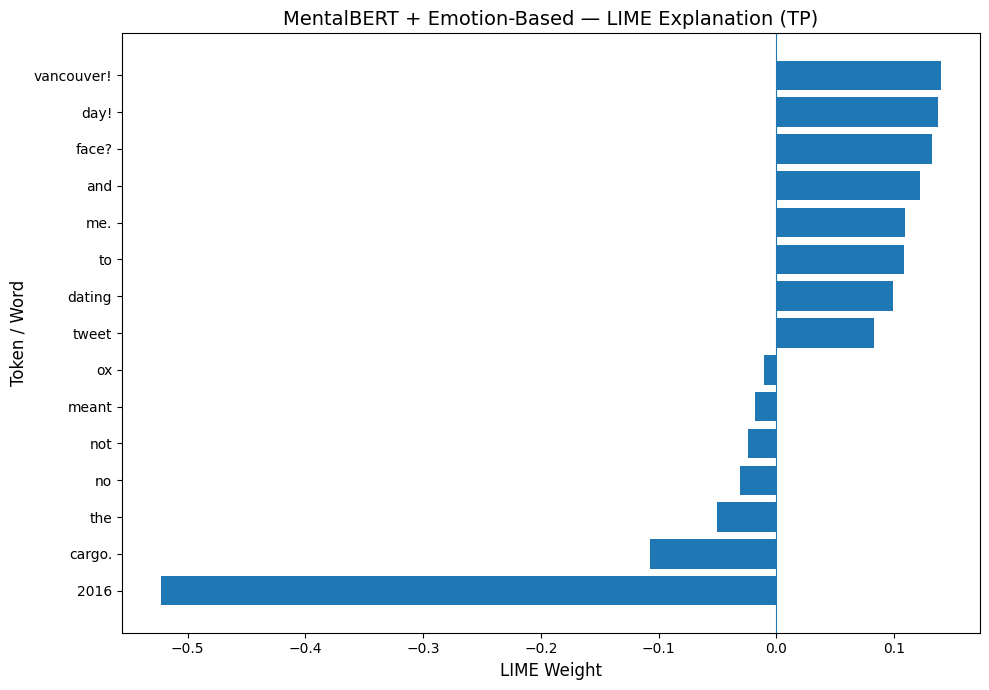

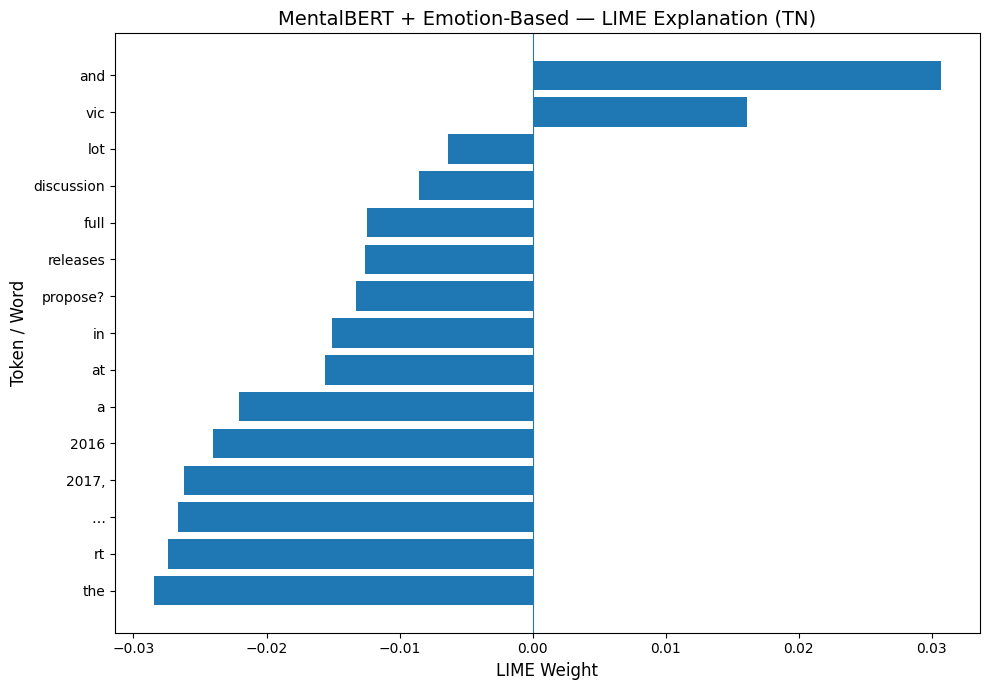

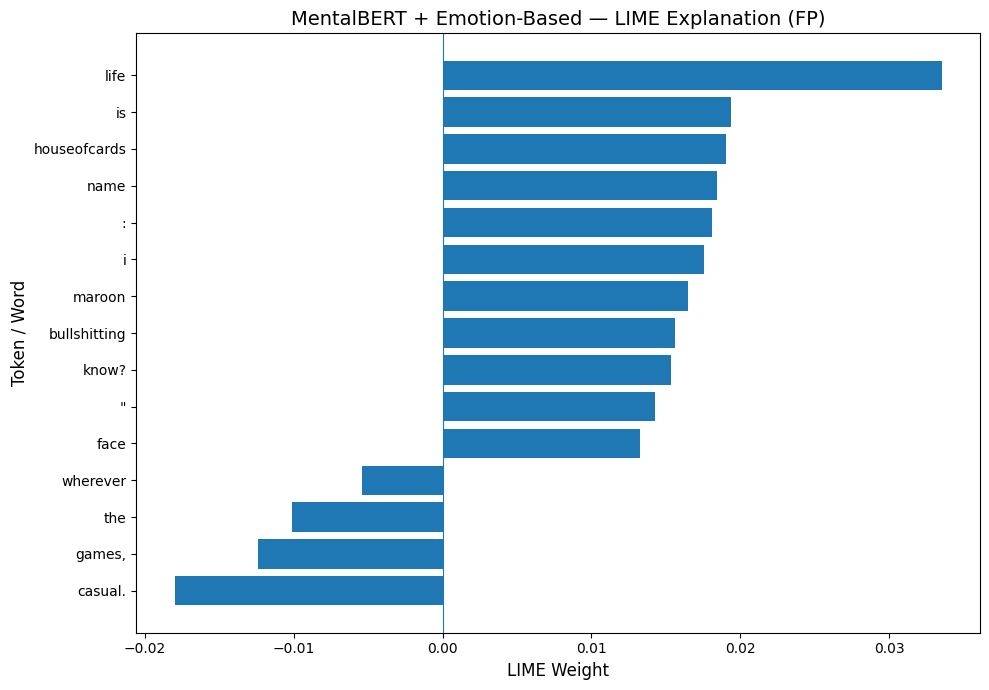

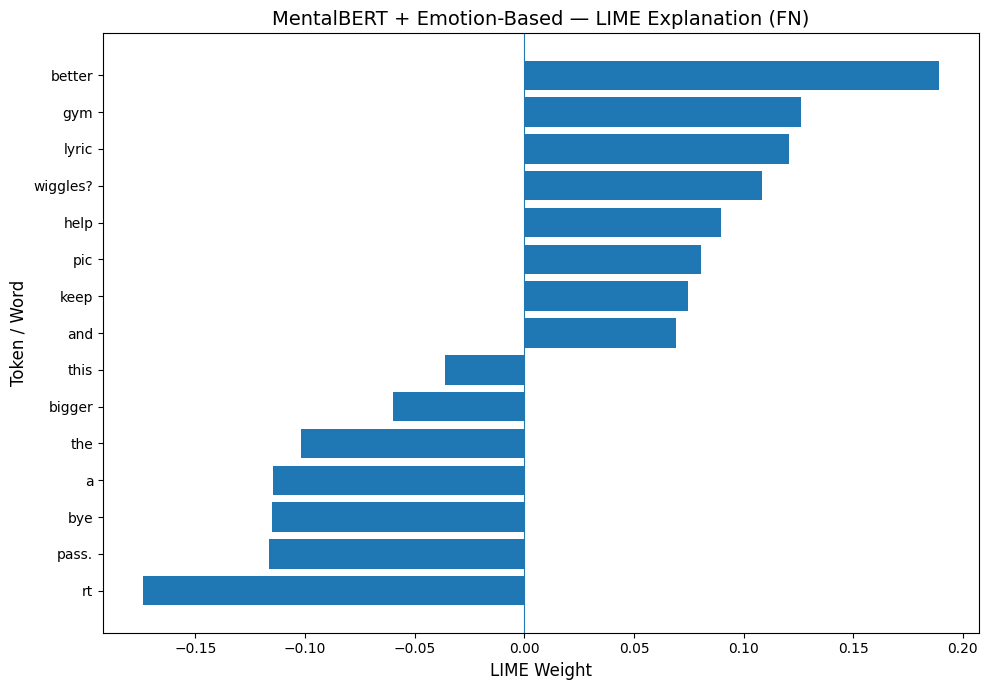


LIME ANALYSIS COMPLETE
✓ TP, TN, FP, FN cases explained
✓ Same trained MentalBERT model used
✓ Metadata held fixed per user
✓ 1000 LIME perturbations per case
✓ Top 15 features extracted
✓ LIME results saved
✓ HTML explanations saved
✓ Paper-ready LIME plots saved and displayed

LIME output directory: /kaggle/working/mentalbert_emotion/explainability/lime


In [28]:
# ============================================================
# CELL 17 — MENTALBERT + EMOTION-BASED
# LIME LOCAL TEXT EXPLANATIONS
# ============================================================

import os
import json
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

from lime.lime_text import LimeTextExplainer
from IPython.display import display, HTML

print("=" * 70)
print("LIME ANALYSIS")
print("MENTALBERT + EMOTION-BASED")
print("=" * 70)

# ============================================================
# FIXED LIME SETTINGS
# ============================================================

LIME_SEED = 42
LIME_NUM_SAMPLES = 1000
LIME_NUM_FEATURES = 15
LIME_BATCH_SIZE = 32

np.random.seed(LIME_SEED)
torch.manual_seed(LIME_SEED)

# ============================================================
# OUTPUT DIRECTORY
# ============================================================

LIME_DIR = os.path.join(
    EXPLAINABILITY_DIR,
    "lime"
)

os.makedirs(
    LIME_DIR,
    exist_ok=True
)

# ============================================================
# MODEL
# ============================================================

model_mental_emotion.eval()

for parameter in model_mental_emotion.parameters():
    parameter.requires_grad = False

print()
print("✓ MentalBERT model loaded")
print("✓ Evaluation mode enabled")
print("✓ No model parameters will be updated")

# ============================================================
# TEST PREDICTIONS FROM CELL 13
# ============================================================

assert len(test_labels_all) == len(test_predictions_all)
assert len(test_predictions_all) == len(test_probabilities_all)

labels_np = np.asarray(test_labels_all)
preds_np = np.asarray(test_predictions_all)
probs_np = np.asarray(test_probabilities_all)

# ============================================================
# DETERMINISTIC REPRESENTATIVE CASES
# ============================================================

case_masks = {

    "TP":
        (labels_np == 1) & (preds_np == 1),

    "TN":
        (labels_np == 0) & (preds_np == 0),

    "FP":
        (labels_np == 0) & (preds_np == 1),

    "FN":
        (labels_np == 1) & (preds_np == 0)
}

selected_cases = {}

for case_name, mask in case_masks.items():

    matching_indices = np.where(
        mask
    )[0]

    assert len(matching_indices) > 0, (
        f"No {case_name} example found "
        "in the test set."
    )

    # Same deterministic selection rule for all experiments
    selected_cases[case_name] = int(
        matching_indices[0]
    )

print()
print("=" * 70)
print("FIXED REPRESENTATIVE TEST CASES")
print("=" * 70)

for case_name, index in selected_cases.items():

    print(
        f"{case_name}: "
        f"test index = {index} | "
        f"true = {labels_np[index]} | "
        f"predicted = {preds_np[index]} | "
        f"P(positive) = {probs_np[index]:.4f}"
    )

# ============================================================
# GET TEXT FROM TOKENIZED TEST EXAMPLE
# ============================================================

def get_test_text(
    test_index
):

    sample = test_mental_emotion_dataset[
        int(test_index)
    ]

    input_ids = sample[
        "input_ids"
    ]

    text = mental_emotion_tokenizer.decode(
        input_ids,
        skip_special_tokens=True,
        clean_up_tokenization_spaces=True
    )

    return text

# ============================================================
# LIME PREDICTOR
# ============================================================
# Text is perturbed by LIME.
# Metadata remains fixed for the user.

def make_lime_predictor(
    test_index
):

    sample = test_mental_emotion_dataset[
        int(test_index)
    ]

    fixed_metadata = (
        sample["metadata"]
        .unsqueeze(0)
        .to(device)
    )

    def predictor(
        texts
    ):

        probabilities = []

        for start in range(
            0,
            len(texts),
            LIME_BATCH_SIZE
        ):

            batch_texts = texts[
                start:
                start + LIME_BATCH_SIZE
            ]

            encoded = mental_emotion_tokenizer(
                batch_texts,
                padding="max_length",
                truncation=True,
                max_length=MAX_LENGTH,
                return_tensors="pt"
            )

            input_ids = (
                encoded["input_ids"]
                .to(device)
            )

            attention_mask = (
                encoded["attention_mask"]
                .to(device)
            )

            metadata_batch = (
                fixed_metadata.expand(
                    len(batch_texts),
                    -1
                )
            )

            with torch.no_grad():

                output = model_mental_emotion(
                    input_ids=input_ids,
                    attention_mask=attention_mask,
                    metadata=metadata_batch
                )

                logits = output[
                    "logits"
                ]

                batch_probs = torch.softmax(
                    logits,
                    dim=1
                ).cpu().numpy()

            probabilities.append(
                batch_probs
            )

        return np.vstack(
            probabilities
        )

    return predictor

# ============================================================
# LIME EXPLAINER
# ============================================================

explainer = LimeTextExplainer(
    class_names=[
        "Negative",
        "Positive"
    ],
    split_expression=r"\s+",
    random_state=LIME_SEED
)

# ============================================================
# GENERATE EXPLANATIONS
# ============================================================

all_explanations = {}

print()
print("=" * 70)
print("GENERATING LIME EXPLANATIONS")
print("=" * 70)

for case_name, test_index in selected_cases.items():

    print()
    print(
        f"Processing {case_name} "
        f"(test index {test_index})..."
    )

    text = get_test_text(
        test_index
    )

    predictor = make_lime_predictor(
        test_index
    )

    explanation = explainer.explain_instance(
        text,
        predictor,
        labels=(1,),
        num_features=LIME_NUM_FEATURES,
        num_samples=LIME_NUM_SAMPLES
    )

    all_explanations[
        case_name
    ] = explanation

    print(
        f"✓ {case_name} explanation complete"
    )

# ============================================================
# SAVE LIME WORD WEIGHTS
# ============================================================

all_lime_rows = []

for case_name, explanation in all_explanations.items():

    explanation_list = explanation.as_list(
        label=1
    )

    for rank, (
        word,
        weight
    ) in enumerate(
        explanation_list,
        start=1
    ):

        all_lime_rows.append({

            "case":
                case_name,

            "test_index":
                selected_cases[case_name],

            "true_label":
                int(
                    labels_np[
                        selected_cases[case_name]
                    ]
                ),

            "predicted_label":
                int(
                    preds_np[
                        selected_cases[case_name]
                    ]
                ),

            "positive_probability":
                float(
                    probs_np[
                        selected_cases[case_name]
                    ]
                ),

            "rank":
                rank,

            "word":
                word,

            "lime_weight":
                float(weight)

        })

lime_results_df = pd.DataFrame(
    all_lime_rows
)

lime_results_df.to_csv(
    os.path.join(
        LIME_DIR,
        "mentalbert_emotion_lime_results.csv"
    ),
    index=False
)

# ============================================================
# DISPLAY + SAVE HTML EXPLANATIONS
# ============================================================

print()
print("=" * 70)
print("LIME EXPLANATIONS")
print("=" * 70)

for case_name, explanation in all_explanations.items():

    print()
    print(
        "=" * 60
    )

    print(
        f"{case_name} — "
        "LIME LOCAL EXPLANATION"
    )

    print(
        "=" * 60
    )

    # DISPLAY
    display(
        HTML(
            explanation.as_html(
                labels=[1]
            )
        )
    )

    # SAVE HTML
    html_path = os.path.join(
        LIME_DIR,
        f"mentalbert_emotion_lime_{case_name}.html"
    )

    with open(
        html_path,
        "w",
        encoding="utf-8"
    ) as f:

        f.write(
            explanation.as_html(
                labels=[1]
            )
        )

# ============================================================
# PAPER-READY LIME BAR PLOTS
# ============================================================

for case_name, explanation in all_explanations.items():

    explanation_list = explanation.as_list(
        label=1
    )

    plot_df = pd.DataFrame(
        explanation_list,
        columns=[
            "word",
            "weight"
        ]
    )

    plot_df = plot_df.sort_values(
        "weight"
    )

    plt.figure(
        figsize=(10, 7)
    )

    plt.barh(
        plot_df["word"],
        plot_df["weight"]
    )

    plt.axvline(
        0,
        linewidth=0.8
    )

    plt.xlabel(
        "LIME Weight",
        fontsize=12
    )

    plt.ylabel(
        "Token / Word",
        fontsize=12
    )

    plt.title(
        f"MentalBERT + Emotion-Based — "
        f"LIME Explanation ({case_name})",
        fontsize=14
    )

    plt.tight_layout()

    plot_path = os.path.join(
        LIME_DIR,
        f"mentalbert_emotion_lime_{case_name}.png"
    )

    # SAVE
    plt.savefig(
        plot_path,
        dpi=300,
        bbox_inches="tight"
    )

    # DISPLAY
    plt.show()

    plt.close()

# ============================================================
# SAVE CASE INFORMATION
# ============================================================

case_info_rows = []

for case_name, test_index in selected_cases.items():

    case_info_rows.append({

        "case":
            case_name,

        "test_index":
            int(test_index),

        "true_label":
            int(
                labels_np[test_index]
            ),

        "predicted_label":
            int(
                preds_np[test_index]
            ),

        "positive_probability":
            float(
                probs_np[test_index]
            ),

        "text_length_characters":
            len(
                get_test_text(test_index)
            )

    })

case_info_df = pd.DataFrame(
    case_info_rows
)

case_info_df.to_csv(
    os.path.join(
        LIME_DIR,
        "mentalbert_emotion_lime_case_information.csv"
    ),
    index=False
)

# ============================================================
# SAVE CONFIGURATION
# ============================================================

lime_config = {

    "model":
        "MentalBERT",

    "base_encoder":
        MODEL_NAME,

    "cleaning":
        "Emotion-Based",

    "dataset":
        "Held-out test set",

    "target":
        "Positive/depression class",

    "representative_cases":
        [
            "TP",
            "TN",
            "FP",
            "FN"
        ],

    "case_selection":
        "First matching test example in fixed test order",

    "random_seed":
        LIME_SEED,

    "num_samples":
        LIME_NUM_SAMPLES,

    "num_features":
        LIME_NUM_FEATURES,

    "batch_size":
        LIME_BATCH_SIZE,

    "metadata":
        "Fixed for each explained user",

    "text_perturbation":
        "LIME word-level perturbations",

    "model_training":
        "No additional training"

}

with open(
    os.path.join(
        LIME_DIR,
        "mentalbert_emotion_lime_config.json"
    ),
    "w"
) as f:

    json.dump(
        lime_config,
        f,
        indent=2
    )

# ============================================================
# COMPLETE
# ============================================================

print()
print("=" * 70)
print("LIME ANALYSIS COMPLETE")
print("=" * 70)

print(
    "✓ TP, TN, FP, FN cases explained"
)

print(
    "✓ Same trained MentalBERT model used"
)

print(
    "✓ Metadata held fixed per user"
)

print(
    "✓ 1000 LIME perturbations per case"
)

print(
    "✓ Top 15 features extracted"
)

print(
    "✓ LIME results saved"
)

print(
    "✓ HTML explanations saved"
)

print(
    "✓ Paper-ready LIME plots saved and displayed"
)

print()
print(
    "LIME output directory:",
    LIME_DIR
)

GRAD-CAM ANALYSIS
MENTALBERT + EMOTION-BASED

✓ MentalBERT model in evaluation mode
✓ All model parameters remain frozen
✓ No model training will occur

REPRESENTATIVE TEST CASES
TP: test index = 1
TN: test index = 0
FP: test index = 27
FN: test index = 23

GENERATING GRAD-CAM EXPLANATIONS

Processing TP (test index 1)...
✓ TP Grad-CAM complete

Processing TN (test index 0)...
✓ TN Grad-CAM complete

Processing FP (test index 27)...
✓ FP Grad-CAM complete

Processing FN (test index 23)...
✓ FN Grad-CAM complete

GRAD-CAM TOKEN IMPORTANCE


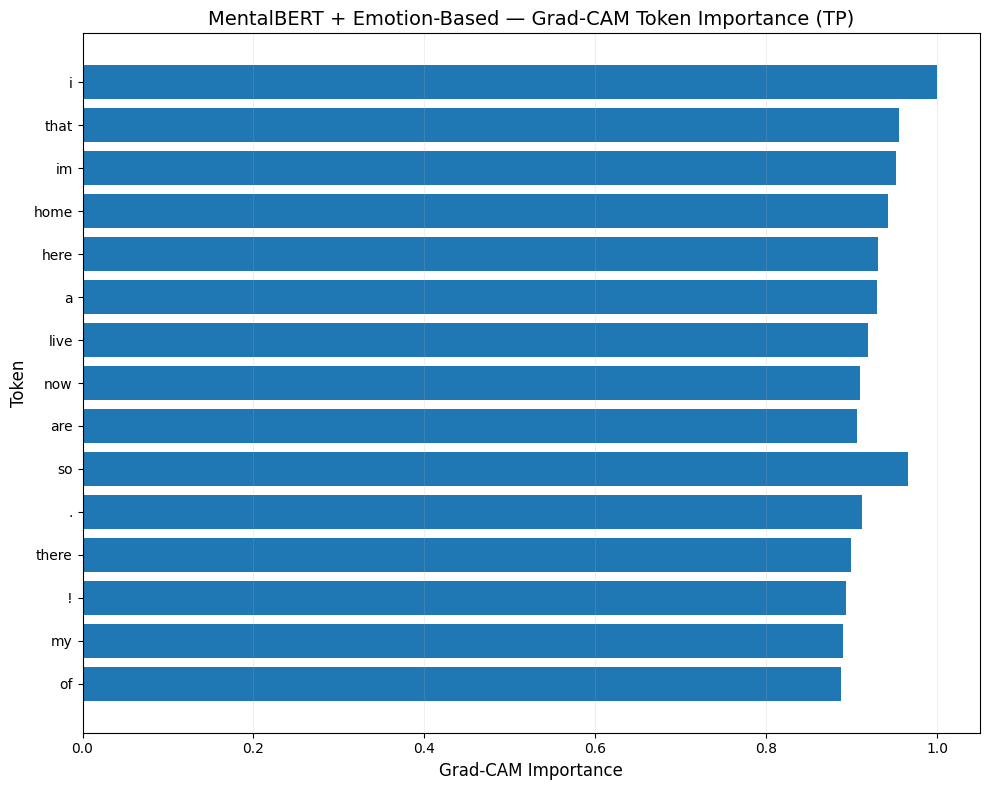

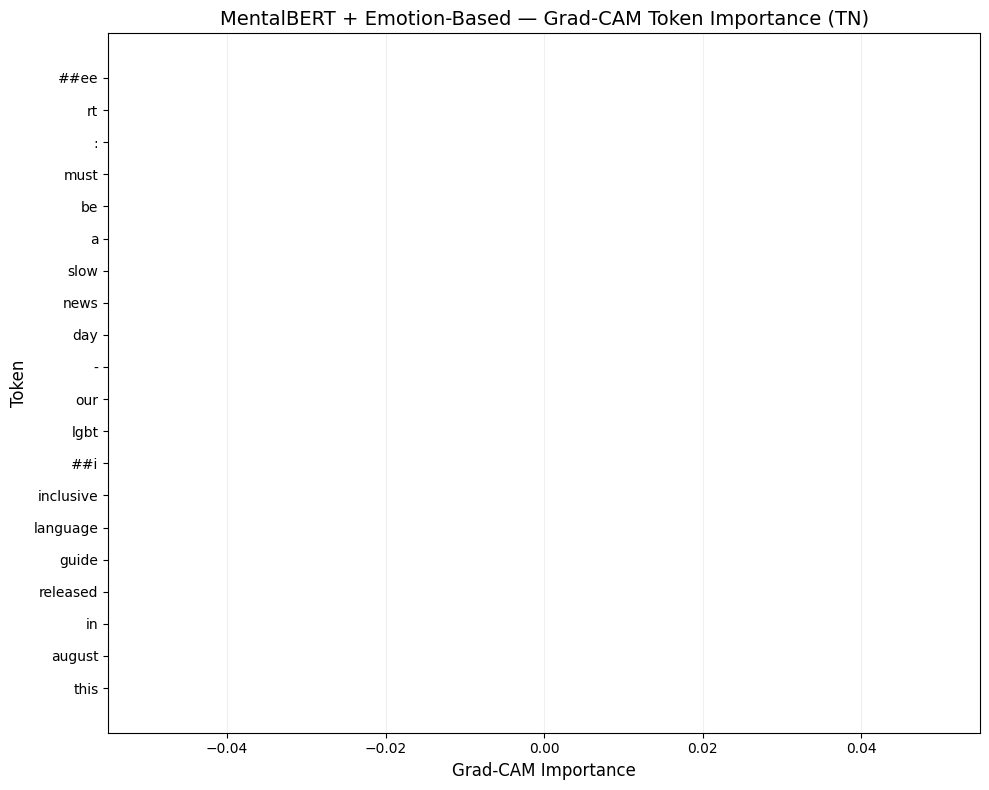

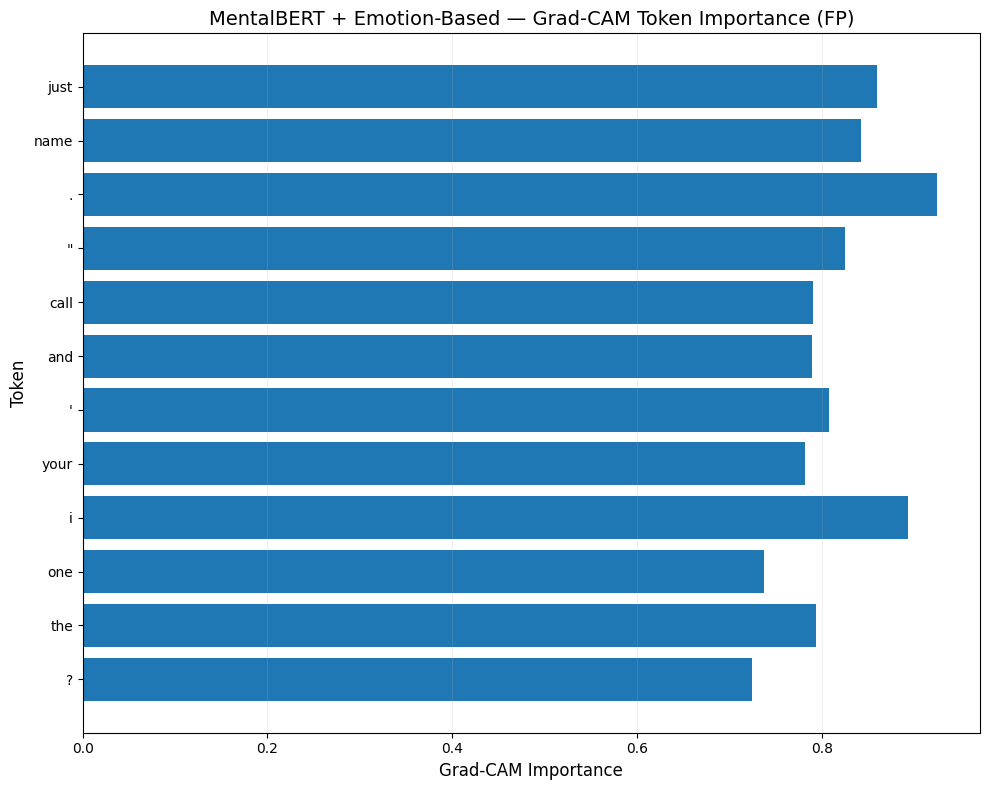

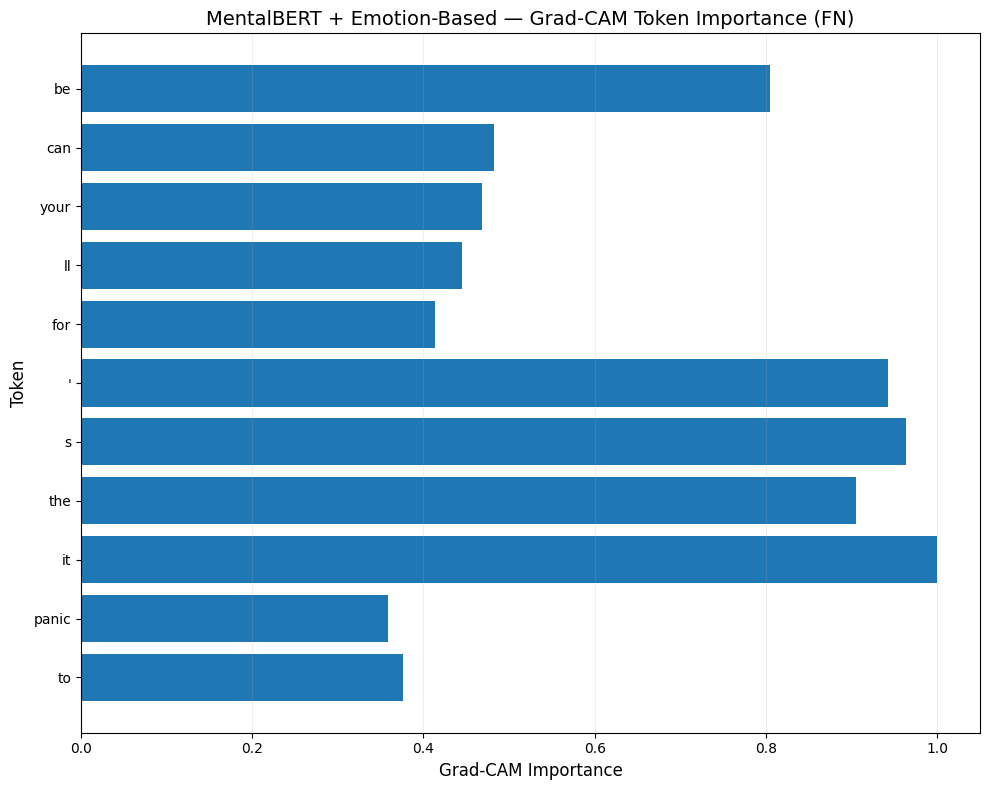


GRAD-CAM ANALYSIS COMPLETE
✓ TP, TN, FP, FN explained
✓ Final Transformer hidden states used
✓ Positive-class gradients computed
✓ MentalBERT backbone remained frozen
✓ No additional model training
✓ Token importance calculated
✓ Top-20 token plots saved and displayed
✓ Complete token importance CSV saved
✓ Top-token table saved
✓ Case information saved
✓ Configuration saved

Grad-CAM output directory: /kaggle/working/mentalbert_emotion/explainability/gradcam


In [29]:
# ============================================================
# CELL 18 — MENTALBERT + EMOTION-BASED
# GRAD-CAM TOKEN-LEVEL EXPLANATION
# ============================================================

import os
import json
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

print("=" * 70)
print("GRAD-CAM ANALYSIS")
print("MENTALBERT + EMOTION-BASED")
print("=" * 70)

# ============================================================
# FIXED GRAD-CAM SETTINGS
# ============================================================

GRADCAM_SEED = 42
GRADCAM_TOP_TOKENS = 20

np.random.seed(
    GRADCAM_SEED
)

torch.manual_seed(
    GRADCAM_SEED
)

# ============================================================
# OUTPUT DIRECTORY
# ============================================================

GRADCAM_DIR = os.path.join(
    EXPLAINABILITY_DIR,
    "gradcam"
)

os.makedirs(
    GRADCAM_DIR,
    exist_ok=True
)

# ============================================================
# MODEL
# ============================================================

model_mental_emotion.eval()

for parameter in model_mental_emotion.parameters():
    parameter.requires_grad = False

print()
print("✓ MentalBERT model in evaluation mode")
print("✓ All model parameters remain frozen")
print("✓ No model training will occur")

# ============================================================
# CHECK REPRESENTATIVE CASES
# ============================================================

assert "selected_cases" in globals()

print()
print("=" * 70)
print("REPRESENTATIVE TEST CASES")
print("=" * 70)

for case_name, test_index in selected_cases.items():

    print(
        f"{case_name}: "
        f"test index = {test_index}"
    )

# ============================================================
# GRAD-CAM FUNCTION
# ============================================================

def compute_mentalbert_gradcam(
    test_index
):

    sample = test_mental_emotion_dataset[
        int(test_index)
    ]

    input_ids = (
        sample["input_ids"]
        .unsqueeze(0)
        .to(device)
    )

    attention_mask = (
        sample["attention_mask"]
        .unsqueeze(0)
        .to(device)
    )

    metadata = (
        sample["metadata"]
        .unsqueeze(0)
        .to(device)
    )

    # --------------------------------------------------------
    # FORWARD PASS WITH GRADIENTS
    # --------------------------------------------------------

    with torch.enable_grad():

        encoder_output = (
            model_mental_emotion.mentalbert(
                input_ids=input_ids,
                attention_mask=attention_mask
            )
        )

        hidden_states = (
            encoder_output.last_hidden_state
        )

        # Frozen encoder weights but gradients are retained
        # with respect to the activation tensor.
        hidden_states = (
            hidden_states
            .detach()
            .requires_grad_(True)
        )

        hidden_states.retain_grad()

        # ----------------------------------------------------
        # EXACT TEXT ATTENTION POOLING
        # ----------------------------------------------------

        projected = torch.tanh(
            model_mental_emotion.attention_projection(
                hidden_states
            )
        )

        attention_scores = (
            model_mental_emotion.attention_score(
                projected
            )
            .squeeze(-1)
        )

        attention_scores = (
            attention_scores.masked_fill(
                attention_mask == 0,
                -1e9
            )
        )

        attention_weights = torch.softmax(
            attention_scores,
            dim=1
        )

        text_representation = torch.sum(
            hidden_states
            *
            attention_weights.unsqueeze(-1),
            dim=1
        )

        # ----------------------------------------------------
        # EXACT METADATA BRANCH
        # ----------------------------------------------------

        metadata_representation = (
            model_mental_emotion.metadata_branch(
                metadata
            )
        )

        metadata_gate = torch.sigmoid(
            model_mental_emotion.metadata_beta
        )

        gated_metadata = (
            metadata_gate
            *
            metadata_representation
        )

        # ----------------------------------------------------
        # EXACT FUSION
        # ----------------------------------------------------

        fused_representation = torch.cat(
            [
                text_representation,
                gated_metadata
            ],
            dim=1
        )

        logits = model_mental_emotion.classifier(
            fused_representation
        )

        # Positive/depression class
        target_score = logits[
            0,
            1
        ]

        # ----------------------------------------------------
        # BACKWARD
        # ----------------------------------------------------

        model_mental_emotion.zero_grad(
            set_to_none=True
        )

        target_score.backward()

        gradients = (
            hidden_states.grad
            .detach()
            .clone()
        )

        activations = (
            hidden_states.detach()
            .clone()
        )

    # ========================================================
    # GRAD-CAM
    # ========================================================

    # Channel-wise mean gradient
    channel_weights = gradients.mean(
        dim=1
    )

    # Weighted activation map
    cam = torch.sum(
        activations
        *
        channel_weights.unsqueeze(1),
        dim=-1
    )

    # ReLU
    cam = torch.relu(
        cam
    )

    cam = (
        cam
        .squeeze(0)
        .cpu()
        .numpy()
    )

    attention_weights_np = (
        attention_weights
        .detach()
        .squeeze(0)
        .cpu()
        .numpy()
    )

    input_ids_np = (
        input_ids
        .detach()
        .squeeze(0)
        .cpu()
        .numpy()
    )

    valid_mask = (
        attention_mask
        .detach()
        .squeeze(0)
        .cpu()
        .numpy()
        .astype(bool)
    )

    # --------------------------------------------------------
    # NORMALIZATION
    # --------------------------------------------------------

    valid_cam = cam[
        valid_mask
    ]

    if (
        valid_cam.max()
        -
        valid_cam.min()
    ) > 1e-12:

        cam_normalized = (
            cam
            -
            valid_cam.min()
        ) / (
            valid_cam.max()
            -
            valid_cam.min()
        )

    else:

        cam_normalized = (
            np.zeros_like(cam)
        )

    # Padding receives zero importance
    cam_normalized[
        ~valid_mask
    ] = 0.0

    return {

        "cam":
            cam_normalized,

        "attention_weights":
            attention_weights_np,

        "input_ids":
            input_ids_np,

        "attention_mask":
            valid_mask,

        "positive_logit":
            float(
                target_score
                .detach()
                .cpu()
                .item()
            ),

        "logits":
            logits
            .detach()
            .cpu()
            .numpy()
            .squeeze(0)

    }


# ============================================================
# TOKEN INFORMATION
# ============================================================

def get_token_information(
    result
):

    tokens = mental_emotion_tokenizer.convert_ids_to_tokens(
        result["input_ids"].tolist()
    )

    cam = result[
        "cam"
    ]

    valid_mask = result[
        "attention_mask"
    ]

    rows = []

    for position, (
        token,
        importance,
        valid
    ) in enumerate(
        zip(
            tokens,
            cam,
            valid_mask
        )
    ):

        if not valid:
            continue

        if token in mental_emotion_tokenizer.all_special_tokens:
            continue

        rows.append({

            "position":
                position,

            "token":
                token,

            "importance":
                float(
                    importance
                )

        })

    token_df = pd.DataFrame(
        rows
    )

    token_df = (
        token_df
        .sort_values(
            "importance",
            ascending=False
        )
        .reset_index(
            drop=True
        )
    )

    token_df["rank"] = (
        np.arange(
            len(token_df)
        ) + 1
    )

    return token_df


# ============================================================
# RUN FOUR CASES
# ============================================================

gradcam_results = {}

print()
print("=" * 70)
print("GENERATING GRAD-CAM EXPLANATIONS")
print("=" * 70)

for case_name, test_index in selected_cases.items():

    print()
    print(
        f"Processing {case_name} "
        f"(test index {test_index})..."
    )

    result = compute_mentalbert_gradcam(
        test_index
    )

    token_df = get_token_information(
        result
    )

    gradcam_results[
        case_name
    ] = {

        "test_index":
            test_index,

        "result":
            result,

        "token_df":
            token_df

    }

    print(
        f"✓ {case_name} Grad-CAM complete"
    )

# ============================================================
# SAVE ALL TOKEN IMPORTANCE
# ============================================================

all_gradcam_rows = []

for case_name, data in gradcam_results.items():

    token_df = data[
        "token_df"
    ]

    for _, row in token_df.iterrows():

        test_index = data[
            "test_index"
        ]

        all_gradcam_rows.append({

            "case":
                case_name,

            "test_index":
                int(test_index),

            "true_label":
                int(
                    labels_np[test_index]
                ),

            "predicted_label":
                int(
                    preds_np[test_index]
                ),

            "positive_probability":
                float(
                    probs_np[test_index]
                ),

            "position":
                int(
                    row["position"]
                ),

            "token":
                row["token"],

            "gradcam_importance":
                float(
                    row["importance"]
                ),

            "rank":
                int(
                    row["rank"]
                )

        })

gradcam_results_df = pd.DataFrame(
    all_gradcam_rows
)

gradcam_results_df.to_csv(
    os.path.join(
        GRADCAM_DIR,
        "mentalbert_emotion_gradcam_token_importance.csv"
    ),
    index=False
)

# ============================================================
# TOP-20 TOKEN PLOTS
# ============================================================

print()
print("=" * 70)
print("GRAD-CAM TOKEN IMPORTANCE")
print("=" * 70)

for case_name, data in gradcam_results.items():

    token_df = (
        data["token_df"]
        .head(
            GRADCAM_TOP_TOKENS
        )
        .copy()
    )

    token_df = token_df.iloc[
        ::-1
    ]

    plt.figure(
        figsize=(10, 8)
    )

    plt.barh(
        token_df["token"],
        token_df["importance"]
    )

    plt.xlabel(
        "Grad-CAM Importance",
        fontsize=12
    )

    plt.ylabel(
        "Token",
        fontsize=12
    )

    plt.title(
        f"MentalBERT + Emotion-Based — "
        f"Grad-CAM Token Importance ({case_name})",
        fontsize=14
    )

    plt.grid(
        axis="x",
        alpha=0.20
    )

    plt.tight_layout()

    plot_path = os.path.join(
        GRADCAM_DIR,
        f"mentalbert_emotion_gradcam_{case_name}.png"
    )

    # SAVE
    plt.savefig(
        plot_path,
        dpi=300,
        bbox_inches="tight"
    )

    # DISPLAY
    plt.show()

    plt.close()

# ============================================================
# SAVE TOP TOKENS TABLE
# ============================================================

top_token_rows = []

for case_name, data in gradcam_results.items():

    top_tokens = (
        data["token_df"]
        .head(
            GRADCAM_TOP_TOKENS
        )
    )

    for _, row in top_tokens.iterrows():

        top_token_rows.append({

            "case":
                case_name,

            "rank":
                int(
                    row["rank"]
                ),

            "token":
                row["token"],

            "gradcam_importance":
                float(
                    row["importance"]
                )

        })

top_token_df = pd.DataFrame(
    top_token_rows
)

top_token_df.to_csv(
    os.path.join(
        GRADCAM_DIR,
        "mentalbert_emotion_gradcam_top_tokens.csv"
    ),
    index=False
)

# ============================================================
# SAVE CASE INFORMATION
# ============================================================

case_rows = []

for case_name, data in gradcam_results.items():

    test_index = data[
        "test_index"
    ]

    case_rows.append({

        "case":
            case_name,

        "test_index":
            int(test_index),

        "true_label":
            int(
                labels_np[test_index]
            ),

        "predicted_label":
            int(
                preds_np[test_index]
            ),

        "positive_probability":
            float(
                probs_np[test_index]
            )

    })

case_df = pd.DataFrame(
    case_rows
)

case_df.to_csv(
    os.path.join(
        GRADCAM_DIR,
        "mentalbert_emotion_gradcam_case_information.csv"
    ),
    index=False
)

# ============================================================
# SAVE CONFIGURATION
# ============================================================

gradcam_config = {

    "model":
        "MentalBERT",

    "base_encoder":
        MODEL_NAME,

    "cleaning":
        "Emotion-Based",

    "dataset":
        "Held-out test set",

    "target":
        "Positive/depression class logit",

    "layer":
        "Final Transformer hidden states",

    "method":
        "Transformer Grad-CAM",

    "hidden_dimension":
        768,

    "cases":
        [
            "TP",
            "TN",
            "FP",
            "FN"
        ],

    "top_tokens_displayed":
        GRADCAM_TOP_TOKENS,

    "random_seed":
        GRADCAM_SEED,

    "model_training":
        "No additional training",

    "transformer_weights":
        "Frozen"

}

with open(
    os.path.join(
        GRADCAM_DIR,
        "mentalbert_emotion_gradcam_config.json"
    ),
    "w"
) as f:

    json.dump(
        gradcam_config,
        f,
        indent=2
    )

# ============================================================
# COMPLETE
# ============================================================

print()
print("=" * 70)
print("GRAD-CAM ANALYSIS COMPLETE")
print("=" * 70)

print(
    "✓ TP, TN, FP, FN explained"
)

print(
    "✓ Final Transformer hidden states used"
)

print(
    "✓ Positive-class gradients computed"
)

print(
    "✓ MentalBERT backbone remained frozen"
)

print(
    "✓ No additional model training"
)

print(
    "✓ Token importance calculated"
)

print(
    "✓ Top-20 token plots saved and displayed"
)

print(
    "✓ Complete token importance CSV saved"
)

print(
    "✓ Top-token table saved"
)

print(
    "✓ Case information saved"
)

print(
    "✓ Configuration saved"
)

print()
print(
    "Grad-CAM output directory:",
    GRADCAM_DIR
)